
# Project 6: Sales Forecasting Across Multiple Retail Stores

## Notebook 04: Machine Learning Modeling and Evaluation

### 1. Notebook objective

The objective of this notebook is to develop, compare and evaluate machine-learning regression models for predicting daily Rossmann store sales. The project business requirement is to forecast sales for individual stores up to six weeks ahead.

This notebook continues from **Notebook 03: Feature Engineering and Preprocessing**. It uses the saved, validated model-ready matrices and targets produced there. We will follow a chronological validation strategy so that model evaluation reflects forecasting on future dates.

### 2. Official project requirements covered here

This notebook addresses the machine-learning modelling and post-prediction requirements in the project brief:

- **Task 2.2 – Building models with scikit-learn pipelines:** create regression models using `sklearn.pipeline.Pipeline`; begin with a tree-based model, with `RandomForestRegressor` as the recommended starting point.
- **Task 2.3 – Choose a loss function:** select suitable training/evaluation measures and explain why they are appropriate for store-sales forecasting.
- **Task 2.4 – Post-prediction analysis:** inspect model feature importance and develop an estimate of prediction intervals; evaluate how those intervals behave on the validation set.
- **Task 2.5 – Serialize models:** save the selected model with a timestamp so that model versions can be distinguished and tracked.

### 3. Inputs from Notebook 03

Notebook 03 completed feature engineering, missing-value handling, categorical encoding and numerical scaling. It fitted the preprocessing transformations using the training data only, transformed the validation and test data with those already-fitted transformations, and saved the resulting artifacts.

The verified data shapes from Notebook 03 are:

| Dataset | Rows | Processed features |
|---|---:|---:|
| Training | 970,379 | 1,149 |
| Validation | 46,830 | 1,149 |
| Test | 41,088 | 1,149 |

The training and validation targets are saved separately. The test dataset has identifiers but no observed `Sales` target.

### 4. Modelling and evaluation methodology

1. Load the processed sparse matrices, target files, test identifiers, processed feature names, modelling metadata and fitted preprocessor saved by Notebook 03.
2. Validate file availability, row counts, feature counts, target alignment and absence of invalid numeric values before fitting any model.
3. Keep the **chronological 42-day validation set** created in Notebook 03. Do not randomly reshuffle the time-based split.
4. Build a `DummyRegressor` baseline first. This gives us a simple reference score that a useful machine-learning model must improve upon.
5. Build a scikit-learn `Pipeline` containing the regression estimator. The feature preprocessing has already been fitted and saved in Notebook 03, so this notebook will train the estimator pipeline on the processed matrices. We will not fit the preprocessor again on validation or test data.
6. Train a controlled Random Forest pilot before increasing model complexity. The dataset is large and the feature matrix is sparse, so model size and runtime will be checked rather than assumed. Any final configuration will be selected using validation results only.
7. Keep the test set out of model selection and hyperparameter tuning. Use it only after the modelling decisions are complete, for final prediction generation.
8. Save the fitted model and supporting metadata with a timestamp. Preserve the fitted preprocessor so future raw input data can be transformed in exactly the same way.

### 5. Metric and loss-function decision

We will report **RMSPE**, **MAE** and **RMSE** on the validation data:

- **RMSPE (primary model-comparison metric):** expresses prediction error relative to actual sales. This is useful when stores have very different sales volumes. It will be calculated only where actual `Sales` is greater than zero, because division by zero is undefined.
- **MAE (secondary metric):** reports the average absolute error in sales units and is easy to interpret.
- **RMSE (secondary metric):** penalizes larger errors more strongly than MAE, helping us identify models that make very large mistakes.

Important distinction: the Random Forest's `criterion="squared_error"` controls how its trees choose splits during training. RMSPE is our primary **validation/model-selection metric**; the standard Random Forest estimator does not directly optimize RMSPE. We will state this distinction clearly in the results rather than implying otherwise.

### 6. Feature importance and prediction intervals

- Examine Random Forest feature importance and connect the leading features to the business problem. Feature importance indicates model reliance/association; it does not prove that a feature causes sales to change.
- Estimate lower and upper prediction bounds from the distribution of predictions across individual trees (initially using selected quantiles, such as the 5th and 95th percentiles).
- Measure interval coverage and average width on the validation data. These tree-spread bounds are **empirical prediction intervals**, not automatically calibrated or guaranteed statistical confidence intervals. Their limitations will be stated in the notebook.

### 7. Planned notebook sections

| Section | Work to complete |
|---|---|
| 1 | Environment setup, reproducibility, logging and project-path detection |
| 2 | Load Notebook 03 model-ready artifacts and validate metadata |
| 3 | Validate datasets, dimensions, target distribution and feature leakage |
| 4 | Train and evaluate a Dummy regression baseline |
| 5 | Train a Random Forest regression pipeline using a resource-aware configuration |
| 6 | Compare models using RMSPE, MAE and RMSE |
| 7 | Tune the selected model using the chronological validation set only |
| 8 | Analyse and visualize feature importance |
| 9 | Estimate empirical prediction intervals and evaluate coverage and width |
| 10 | Save the selected pilot model, preprocessor reference and metadata with a timestamp |
| 11 | Record pilot modelling results, limitations and completion audit |
| 12 | Refit the selected Random Forest on all training rows, compare with a matched full-training Dummy baseline, evaluate, serialize and verify the final model |

### 8. Work that belongs to later project stages

The following official requirements will be completed after this notebook, in their own clearly separated stages:

- **Task 2.6:** LSTM time-series modelling (stationarity, differencing where appropriate, ACF/PACF, supervised sequences, scaling to `(-1, 1)` and an LSTM model with no more than two layers).
- **Task 2.7:** MLflow tracking/serving and inference on the test data.
- **Task 3:** a web dashboard to collect input parameters and show/download predictions, followed by deployment/hosting.

### 9. Execution discipline

Run the notebook from top to bottom. Complete and inspect one section before moving to the next. If a cell fails, stop at that cell and resolve the error before continuing. Record actual outputs and measured results; do not invent model scores or claim that an unexecuted model has been validated.



# SECTION 1: ENVIRONMENT SETUP AND REPRODUCIBILITY

## Purpose

Prepare the notebook environment, import the libraries needed for regression modelling, configure reproducibility and logging, and locate the model-ready artifacts saved by Notebook 03.

## Required artifacts

This section checks for the nine outputs created by Notebook 03:

- Three processed feature matrices (`.npz` sparse matrices).
- Training and validation target files.
- Original test identifiers.
- Processed feature names and modelling metadata.
- The fitted preprocessing object.

## Important methodology

No model is trained in this section. It only prepares the environment and confirms that Notebook 04 can access the validated inputs from Notebook 03.

## Expected outcome

- Reproducible random seed.
- Configured logger.
- Detected project root.
- Verified artifact paths.
- `section_1_successful = True` only when all required input files are available.


In [17]:

# ============================================================
# PROJECT 6 - NOTEBOOK 04
# SECTION 1: ENVIRONMENT SETUP AND REPRODUCIBILITY
# ============================================================

# STEP 1: IMPORT STANDARD PYTHON LIBRARIES

import os
import sys
import json
import random
import logging
import warnings

from pathlib import Path
from datetime import datetime


# STEP 2: IMPORT DATA SCIENCE LIBRARIES

import numpy as np
import pandas as pd
import scipy
import scipy.sparse as sp
import sklearn
import joblib

from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)


# STEP 3: SET RANDOM SEED FOR REPRODUCIBILITY

RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)


# STEP 4: CONFIGURE PANDAS DISPLAY SETTINGS

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 140)
pd.set_option(
    "display.float_format",
    lambda value: f"{value:,.4f}"
)


# STEP 5: DETECT PROJECT ROOT DIRECTORY

# The notebook is expected to be inside the notebooks folder.
# We search the current working directory and its parent folders
# to locate the main Project 6 directory.

current_directory = Path.cwd().resolve()

candidate_roots = [
    current_directory,
    *current_directory.parents
]


# These are the nine artifacts saved by Notebook 03.

required_relative_paths = [
    Path("data/model_ready/X_train_processed.npz"),
    Path("data/model_ready/X_valid_processed.npz"),
    Path("data/model_ready/X_test_processed.npz"),
    Path("data/model_ready/y_train.csv"),
    Path("data/model_ready/y_valid.csv"),
    Path("data/model_ready/test_ids.csv"),
    Path("data/model_ready/processed_feature_names.csv"),
    Path("data/model_ready/modeling_metadata.json"),
    Path("models/preprocessor.joblib")
]


# Find the project folder containing all required artifacts.

matching_roots = [
    root
    for root in candidate_roots
    if all(
        (root / relative_path).is_file()
        for relative_path in required_relative_paths
    )
]


# Stop execution with a clear message if the project folder
# or any required artifact cannot be located.

if not matching_roots:

    missing_by_root = {}

    for root in candidate_roots:

        missing = [
            str(relative_path)
            for relative_path in required_relative_paths
            if not (root / relative_path).is_file()
        ]

        missing_by_root[str(root)] = missing

    raise FileNotFoundError(
        "Could not locate the Project 6 root containing "
        "all nine Notebook 03 artifacts.\n"
        f"Current working directory: {current_directory}\n"
        "Expected files under data/model_ready/ and models/.\n"
        f"Missing-file check: {missing_by_root}"
    )


# Select the closest matching project root.

PROJECT_ROOT = matching_roots[0]

MODEL_READY_DIR = PROJECT_ROOT / "data" / "model_ready"

MODELS_DIR = PROJECT_ROOT / "models"


# STEP 6: CREATE NOTEBOOK 04 OUTPUT DIRECTORIES

ML_MODEL_DIR = MODELS_DIR / "machine_learning"

EVALUATION_DIR = (
    PROJECT_ROOT / "reports" / "model_evaluation"
)

LOG_DIR = PROJECT_ROOT / "logs"


for directory in [
    ML_MODEL_DIR,
    EVALUATION_DIR,
    LOG_DIR
]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# STEP 7: DEFINE NOTEBOOK 03 ARTIFACT PATHS

ARTIFACT_PATHS = {

    "X_train_processed":
        MODEL_READY_DIR / "X_train_processed.npz",

    "X_valid_processed":
        MODEL_READY_DIR / "X_valid_processed.npz",

    "X_test_processed":
        MODEL_READY_DIR / "X_test_processed.npz",

    "y_train":
        MODEL_READY_DIR / "y_train.csv",

    "y_valid":
        MODEL_READY_DIR / "y_valid.csv",

    "test_ids":
        MODEL_READY_DIR / "test_ids.csv",

    "feature_names":
        MODEL_READY_DIR / "processed_feature_names.csv",

    "metadata":
        MODEL_READY_DIR / "modeling_metadata.json",

    "preprocessor":
        MODELS_DIR / "preprocessor.joblib"
}


# Check that all nine files exist and are not empty.

missing_artifacts = [

    name

    for name, path in ARTIFACT_PATHS.items()

    if not path.is_file() or path.stat().st_size == 0

]


if missing_artifacts:

    raise FileNotFoundError(
        "The following Notebook 03 artifacts "
        "are missing or empty: "
        f"{missing_artifacts}"
    )


# STEP 8: CONFIGURE PYTHON LOGGING

logger = logging.getLogger(
    "Project6_ML_Modeling"
)

logger.setLevel(logging.INFO)

# Prevent duplicate log messages.

logger.propagate = False


# Avoid adding duplicate handlers when the cell
# is executed more than once.

if not logger.handlers:

    log_format = logging.Formatter(
        "%(asctime)s | %(levelname)s | "
        "%(name)s | %(message)s"
    )

    # Console logging handler.

    console_handler = logging.StreamHandler()

    console_handler.setLevel(logging.INFO)

    console_handler.setFormatter(log_format)

    logger.addHandler(console_handler)


    # File logging handler.

    file_handler = logging.FileHandler(
        LOG_DIR / "notebook04_modeling.log",
        encoding="utf-8"
    )

    file_handler.setLevel(logging.INFO)

    file_handler.setFormatter(log_format)

    logger.addHandler(file_handler)


# STEP 9: DISPLAY ENVIRONMENT INFORMATION

print("=" * 90)

print(
    "PROJECT 6: NOTEBOOK 04 - "
    "MACHINE LEARNING MODELING"
)

print("=" * 90)


print("\nPython Version:")

print(sys.version.split()[0])


print("\nNumPy Version:")

print(np.__version__)


print("\nPandas Version:")

print(pd.__version__)


print("\nSciPy Version:")

print(scipy.__version__)


print("\nScikit-learn Version:")

print(sklearn.__version__)


print("\nRandom State:")

print(RANDOM_STATE)


print("\nDetected Project Root:")

print(PROJECT_ROOT)


# STEP 10: DISPLAY ARTIFACT VERIFICATION

print("\nNotebook 03 Artifact Verification:")

for artifact_name, artifact_path in ARTIFACT_PATHS.items():

    print(
        f"{artifact_name:<24}: "
        f"{artifact_path.is_file()}"
    )


# STEP 11: DISPLAY OUTPUT DIRECTORIES

print("\nNotebook 04 Output Directories:")

print("Model directory:", ML_MODEL_DIR)

print("Evaluation directory:", EVALUATION_DIR)

print("Log directory:", LOG_DIR)


# STEP 12: FINAL SECTION VALIDATION

section_1_successful = (

    RANDOM_STATE == 42

    and PROJECT_ROOT.is_dir()

    and len(ARTIFACT_PATHS) == 9

    and all(
        path.is_file() and path.stat().st_size > 0
        for path in ARTIFACT_PATHS.values()
    )

    and ML_MODEL_DIR.is_dir()

    and EVALUATION_DIR.is_dir()

    and LOG_DIR.is_dir()

)


print("\n" + "=" * 90)

print(
    "SECTION 1 COMPLETED SUCCESSFULLY:",
    section_1_successful
)

print("=" * 90)


if not section_1_successful:

    raise RuntimeError(
        "Notebook 04 environment setup did not pass "
        "all validation checks."
    )


# Record successful completion in the log file.

logger.info(
    "Notebook 04 Section 1 completed successfully. "
    "Environment and nine Notebook 03 artifacts verified."
)


2026-11-05 17:11:43,647 | INFO | Project6_ML_Modeling | Notebook 04 Section 1 completed successfully. Environment and nine Notebook 03 artifacts verified.


PROJECT 6: NOTEBOOK 04 - MACHINE LEARNING MODELING

Python Version:
3.13.14

NumPy Version:
2.5.4

Pandas Version:
3.1.0

SciPy Version:
1.18.1

Scikit-learn Version:
1.9.1

Random State:
42

Detected Project Root:
D:\Project_6_Rossmann_Forecasting

Notebook 03 Artifact Verification:
X_train_processed       : True
X_valid_processed       : True
X_test_processed        : True
y_train                 : True
y_valid                 : True
test_ids                : True
feature_names           : True
metadata                : True
preprocessor            : True

Notebook 04 Output Directories:
Model directory: D:\Project_6_Rossmann_Forecasting\models\machine_learning
Evaluation directory: D:\Project_6_Rossmann_Forecasting\reports\model_evaluation
Log directory: D:\Project_6_Rossmann_Forecasting\logs

SECTION 1 COMPLETED SUCCESSFULLY: True



# SECTION 2: LOAD AND VALIDATE NOTEBOOK 03 MODEL-READY ARTIFACTS

## Purpose

Load the processed training, validation and test feature matrices, target variables, original test identifiers, processed feature names, modelling metadata and fitted preprocessing object saved by Notebook 03.

## Required artifacts

1. X_train_processed.npz
2. X_valid_processed.npz
3. X_test_processed.npz
4. y_train.csv
5. y_valid.csv
6. test_ids.csv
7. processed_feature_names.csv
8. modeling_metadata.json
9. preprocessor.joblib

## Validation methodology

- Load feature matrices in sparse CSR format to reduce memory usage.
- Validate matrix dimensions and target/identifier row alignment.
- Check for missing, infinite and invalid target values.
- Verify that processed feature names match the matrix columns and fitted preprocessor.
- Confirm that the preprocessing object is fitted.
- Audit the saved metadata against the actual loaded artifacts.

## Important consideration

The processed matrices and corresponding target/identifier files are used as the source of truth for actual row counts.

If the saved metadata contains discrepancies, the original JSON is preserved. A corrected in-memory metadata copy is created for Notebook 04, and all discrepancies are reported transparently.

## Expected outcome

The nine artifacts should load successfully, and all core model-input validation checks should pass.

The notebook will separately report whether the saved metadata audit passed.
No model training is performed in this section.


In [18]:

# ============================================================
# PROJECT 6 - NOTEBOOK 04
# SECTION 2: LOAD AND VALIDATE NOTEBOOK 03 ARTIFACTS
# ============================================================

import warnings

# STEP 1: CONFIRM SECTION 1 IS COMPLETE

if "section_1_successful" not in globals() or not section_1_successful:

    raise RuntimeError(
        "Section 1 has not completed successfully. "
        "Run Section 1 before Section 2."
    )

logger.info("Section 2 started: loading Notebook 03 artifacts.")


# STEP 2: CHECK ALL REQUIRED FILES BEFORE LOADING

missing_or_empty_files = [
    name
    for name, path in ARTIFACT_PATHS.items()
    if not path.is_file() or path.stat().st_size == 0
]

if missing_or_empty_files:

    raise FileNotFoundError(
        "These Notebook 03 artifacts are missing or empty: "
        f"{missing_or_empty_files}"
    )


# STEP 3: LOAD THE THREE SPARSE FEATURE MATRICES

# Keep the matrices sparse.
# Do not convert these large matrices to dense arrays.

X_train_processed = sp.load_npz(
    ARTIFACT_PATHS["X_train_processed"]
).tocsr()

X_valid_processed = sp.load_npz(
    ARTIFACT_PATHS["X_valid_processed"]
).tocsr()

X_test_processed = sp.load_npz(
    ARTIFACT_PATHS["X_test_processed"]
).tocsr()


# STEP 4: LOAD TARGETS, TEST IDS, FEATURE NAMES AND METADATA

y_train_df = pd.read_csv(
    ARTIFACT_PATHS["y_train"]
)

y_valid_df = pd.read_csv(
    ARTIFACT_PATHS["y_valid"]
)

test_ids_df = pd.read_csv(
    ARTIFACT_PATHS["test_ids"]
)

feature_names_df = pd.read_csv(
    ARTIFACT_PATHS["feature_names"]
)


with open(
    ARTIFACT_PATHS["metadata"],
    "r",
    encoding="utf-8"
) as file:

    modeling_metadata_source = json.load(file)


# Keep the original saved metadata unchanged.

if not isinstance(modeling_metadata_source, dict):

    raise TypeError(
        "modeling_metadata.json must contain a JSON object."
    )


# STEP 5: LOAD THE PREPROCESSOR SAVED BY NOTEBOOK 03

preprocessor = joblib.load(
    ARTIFACT_PATHS["preprocessor"]
)


if not callable(getattr(preprocessor, "transform", None)):

    raise TypeError(
        "The saved preprocessor does not expose "
        "a callable transform() method."
    )


# Confirm that the saved preprocessing object is fitted.

from sklearn.utils.validation import check_is_fitted

try:

    check_is_fitted(preprocessor)

except Exception as exc:

    raise ValueError(
        "The saved preprocessor does not appear to be fitted. "
        "Recheck Notebook 03 Sections 12-14."
    ) from exc


# STEP 6: VALIDATE FILE SCHEMAS

expected_csv_columns = {

    "y_train": (y_train_df, ["Sales"]),

    "y_valid": (y_valid_df, ["Sales"]),

    "test_ids": (test_ids_df, ["Id"]),

    "feature_names": (
        feature_names_df,
        ["Feature_Name"]
    )

}


for file_label, (dataframe, expected_columns) in expected_csv_columns.items():

    if dataframe.columns.tolist() != expected_columns:

        raise ValueError(
            f"Unexpected columns in {file_label}. "
            f"Expected {expected_columns}, "
            f"found {dataframe.columns.tolist()}."
        )


# STEP 7: EXTRACT NUMERIC TARGET ARRAYS AND PRESERVE ORIGINAL TEST IDS

y_train = pd.to_numeric(
    y_train_df["Sales"],
    errors="raise"
).to_numpy(dtype=np.float64)


y_valid = pd.to_numeric(
    y_valid_df["Sales"],
    errors="raise"
).to_numpy(dtype=np.float64)


# Preserve original test IDs.

test_ids = test_ids_df["Id"].copy()


# Load processed feature names.

feature_names = (
    feature_names_df["Feature_Name"]
    .astype(str)
    .str.strip()
    .tolist()
)


# STEP 8: VALIDATE SPARSE MATRIX DATA

processed_matrices = {

    "Training": X_train_processed,

    "Validation": X_valid_processed,

    "Test": X_test_processed

}


for matrix_name, matrix in processed_matrices.items():

    if not sp.issparse(matrix):

        raise TypeError(
            f"{matrix_name} features were not loaded "
            "as a sparse matrix."
        )

    if matrix.ndim != 2:

        raise ValueError(
            f"{matrix_name} feature matrix must be two-dimensional."
        )

    if not np.isfinite(matrix.data).all():

        raise ValueError(
            f"{matrix_name} feature matrix contains NaN or infinity."
        )


# STEP 9: CHECK EXPECTED NOTEBOOK 03 DIMENSIONS

# These dimensions were verified at the end of Notebook 03.

expected_shapes = {

    "Training": (970379, 1149),

    "Validation": (46830, 1149),

    "Test": (41088, 1149)

}


observed_shapes = {

    "Training": X_train_processed.shape,

    "Validation": X_valid_processed.shape,

    "Test": X_test_processed.shape

}


shape_checks = {

    name: observed_shapes[name] == expected_shapes[name]

    for name in expected_shapes

}


if not all(shape_checks.values()):

    raise ValueError(
        "Feature-matrix dimensions do not match "
        "the verified Notebook 03 outputs. "
        f"Expected: {expected_shapes}; "
        f"observed: {observed_shapes}."
    )


# STEP 10: CHECK TARGET AND TEST-ID ALIGNMENT

row_alignment_checks = {

    "Training rows match y_train":
        X_train_processed.shape[0] == len(y_train),

    "Validation rows match y_valid":
        X_valid_processed.shape[0] == len(y_valid),

    "Test rows match original test IDs":
        X_test_processed.shape[0] == len(test_ids)

}


if not all(row_alignment_checks.values()):

    raise ValueError(
        f"Row-alignment checks failed: {row_alignment_checks}"
    )


# Check target values.

if not np.isfinite(y_train).all() or not np.isfinite(y_valid).all():

    raise ValueError(
        "Sales targets contain NaN or infinite values."
    )


if (y_train < 0).any() or (y_valid < 0).any():

    raise ValueError(
        "Sales targets contain negative values, "
        "which require investigation."
    )


# Check test IDs.

if test_ids.isna().any() or not test_ids.is_unique:

    raise ValueError(
        "Original test IDs contain missing or duplicate values."
    )


# STEP 11: CHECK PROCESSED FEATURE NAMES

feature_count = X_train_processed.shape[1]

feature_names_valid = (

    len(feature_names) == feature_count

    and len(set(feature_names)) == feature_count

    and all(bool(name) for name in feature_names)

)


if not feature_names_valid:

    raise ValueError(
        "Processed feature names are missing, duplicated, "
        "or do not match the matrix columns. "
        f"Expected {feature_count}; "
        f"found {len(feature_names)} names."
    )


# Cross-check feature names against the fitted preprocessor.

if callable(getattr(preprocessor, "get_feature_names_out", None)):

    preprocessor_feature_names = (
        preprocessor
        .get_feature_names_out()
        .astype(str)
        .tolist()
    )

    if preprocessor_feature_names != feature_names:

        raise ValueError(
            "The feature-name CSV does not match the fitted "
            "preprocessor's get_feature_names_out() result. "
            "Check Notebook 03 artifacts."
        )

else:

    preprocessor_feature_names = None


# STEP 12: AUDIT SAVED METADATA AGAINST LOADED ARTIFACTS

# Actual matrix and target files are the source of truth
# for the row counts used by Notebook 04.

actual_metadata_values = {

    "train_rows":
        int(X_train_processed.shape[0]),

    "validation_rows":
        int(X_valid_processed.shape[0]),

    "test_rows":
        int(X_test_processed.shape[0]),

    "processed_feature_count":
        int(feature_count),

    "target_variable":
        "Sales"

}


metadata_audit = {}

metadata_discrepancies = []


# Compare original saved metadata with verified values.

for key, verified_value in actual_metadata_values.items():

    saved_value = modeling_metadata_source.get(
        key,
        "<missing>"
    )

    if key.endswith("_rows") or key == "processed_feature_count":

        try:

            matched = int(saved_value) == verified_value

        except (TypeError, ValueError):

            matched = False

    else:

        matched = (
            str(saved_value).strip().casefold()
            == verified_value.casefold()
        )


    metadata_audit[key] = {

        "saved_value": saved_value,

        "verified_value_from_artifacts": verified_value,

        "matched": bool(matched)

    }


    if not matched:

        metadata_discrepancies.append(key)


# Check the preprocessing fit description.

saved_fit_description = modeling_metadata_source.get(
    "preprocessing_fitted_on",
    "<missing>"
)


normalized_fit_description = (

    str(saved_fit_description)

    .strip()

    .casefold()

    .replace("_", "")

    .replace(" ", "")

    .replace("-", "")

)


accepted_fit_descriptions = {

    "xtrainonly",

    "trainingdataonly",

    "trainonly"

}


fit_description_matches = (
    normalized_fit_description in accepted_fit_descriptions
)


metadata_audit["preprocessing_fitted_on"] = {

    "saved_value": saved_fit_description,

    "verified_expected_value": "X_train only",

    "matched": bool(fit_description_matches)

}


if not fit_description_matches:

    metadata_discrepancies.append(
        "preprocessing_fitted_on"
    )


# Preserve the source JSON in modeling_metadata_source.
# Correct only the in-memory copy using verified artifacts
# and Notebook 03's documented training-only fit strategy.

modeling_metadata = dict(modeling_metadata_source)

modeling_metadata.update(actual_metadata_values)

modeling_metadata["preprocessing_fitted_on"] = "X_train only"

modeling_metadata["section_2_metadata_audit"] = metadata_audit

modeling_metadata["source_metadata_discrepancies"] = (
    metadata_discrepancies
)


# STEP 13: DISPLAY LOADED ARTIFACT INFORMATION

print("=" * 90)

print("SECTION 2: NOTEBOOK 03 ARTIFACTS LOADED")

print("=" * 90)


print("\nProcessed Matrix Shapes:")

for name, matrix in processed_matrices.items():

    total_entries = matrix.shape[0] * matrix.shape[1]

    density = (
        matrix.nnz / total_entries
        if total_entries
        else 0.0
    )

    print(
        f"{name:<12}: shape={matrix.shape}, "
        f"non_zero={matrix.nnz:,}, "
        f"density={density:.6f}"
    )


print("\nTarget and Identifier Lengths:")

print("y_train:", len(y_train))

print("y_valid:", len(y_valid))

print("test_ids:", len(test_ids))

print("Unique test IDs:", test_ids.nunique())


print("\nProcessed Feature Count:")

print(feature_count)


print("\nFirst 10 Feature Names:")

print(feature_names[:10])


# Display saved versus verified metadata.

print("\nSaved Metadata Audit:")

print(
    json.dumps(
        metadata_audit,
        indent=4,
        default=str
    )
)


# Report metadata discrepancies as warnings, not hidden errors.

if metadata_discrepancies:

    warning_message = (

        "Saved modeling_metadata.json contains discrepancies in: "

        f"{metadata_discrepancies}. "

        "The source JSON was preserved. "

        "A corrected in-memory metadata copy is being used "
        "for Notebook 04."

    )

    warnings.warn(
        warning_message,
        RuntimeWarning
    )

    logger.warning(warning_message)

else:

    logger.info(
        "Saved modeling metadata matches the loaded artifacts."
    )


# STEP 14: FINAL SECTION VALIDATION

core_artifact_checks = {

    "All three matrix shapes verified":
        all(shape_checks.values()),

    "All row alignments verified":
        all(row_alignment_checks.values()),

    "Feature names verified":
        feature_names_valid,

    "Training target finite":
        bool(np.isfinite(y_train).all()),

    "Validation target finite":
        bool(np.isfinite(y_valid).all()),

    "Test IDs valid and unique":
        bool(test_ids.notna().all() and test_ids.is_unique),

    "Preprocessor can transform":
        callable(getattr(preprocessor, "transform", None))

}


print("\nCore Artifact Validation:")

for check_name, check_result in core_artifact_checks.items():

    print(
        f"{check_name:<42}: {check_result}"
    )


metadata_audit_passed = (
    len(metadata_discrepancies) == 0
)


# Section success depends on actual model inputs being valid.
# Metadata discrepancies are separately displayed above.

section_2_successful = all(
    core_artifact_checks.values()
)


print("\nMetadata Audit Passed:", metadata_audit_passed)

print(
    "Metadata Discrepancies:",
    metadata_discrepancies
)

print(
    "SECTION 2 COMPLETED SUCCESSFULLY:",
    section_2_successful
)

print("=" * 90)


if not section_2_successful:

    raise RuntimeError(
        "Section 2 core artifact validation failed. "
        "Review the failed checks printed above before continuing."
    )


logger.info(
    "Section 2 completed. All model-input artifacts passed "
    "core validation. "
    f"Metadata audit passed: {metadata_audit_passed}."
)


2026-11-05 17:11:43,710 | INFO | Project6_ML_Modeling | Section 2 started: loading Notebook 03 artifacts.
2026-11-05 17:11:44,579 | INFO | Project6_ML_Modeling | Saved modeling metadata matches the loaded artifacts.
2026-11-05 17:11:44,583 | INFO | Project6_ML_Modeling | Section 2 completed. All model-input artifacts passed core validation. Metadata audit passed: True.


SECTION 2: NOTEBOOK 03 ARTIFACTS LOADED

Processed Matrix Shapes:
Training    : shape=(970379, 1149), non_zero=24,259,475, density=0.021758
Validation  : shape=(46830, 1149), non_zero=1,170,750, density=0.021758
Test        : shape=(41088, 1149), non_zero=1,027,200, density=0.021758

Target and Identifier Lengths:
y_train: 970379
y_valid: 46830
test_ids: 41088
Unique test IDs: 41088

Processed Feature Count:
1149

First 10 Feature Names:
['numerical__DayOfWeek', 'numerical__Open', 'numerical__Promo', 'numerical__SchoolHoliday', 'numerical__CompetitionDistance', 'numerical__Promo2', 'numerical__Year', 'numerical__Month', 'numerical__Day', 'numerical__WeekOfYear']

Saved Metadata Audit:
{
    "train_rows": {
        "saved_value": 970379,
        "verified_value_from_artifacts": 970379,
        "matched": true
    },
    "validation_rows": {
        "saved_value": 46830,
        "verified_value_from_artifacts": 46830,
        "matched": true
    },
    "test_rows": {
        "saved_value


# SECTION 3: DATA INTEGRITY, TARGET DISTRIBUTION AND FEATURE LEAKAGE CHECK

## Purpose

Perform additional data-integrity checks before developing the regression models. This section examines the Sales target distribution, validates the processed feature names for possible target leakage, and checks the chronological date ranges recorded in Notebook 03.

## Key activities

1. Examine the training and validation Sales distributions.
2. Calculate minimum, maximum, mean, median, standard deviation and selected percentiles.
3. Identify zero-sales and positive-sales observations.
4. Confirm that target values are finite and non-negative.
5. Verify that Sales, Customers, Id and Date have not entered the processed model features.
6. Confirm that the training, validation and test date ranges follow the required chronological order.
7. Record any difference between the training and validation target distributions.

## Important methodology

- Zero-sales observations will not automatically be removed. They can represent legitimate store-closure days and should be investigated rather than discarded.
- Target distribution differences will be reported, not automatically treated as errors.
- The test dataset has no observed Sales target, so test-set target statistics will not be calculated.
- No feature transformation, model fitting or test-set tuning will be performed in this section.

## Expected outcome

The target arrays, processed feature names and available chronological metadata should pass their integrity checks.

The final status will be recorded as `section_3_successful`.


In [19]:

# ============================================================
# PROJECT 6 - NOTEBOOK 04
# SECTION 3: DATA INTEGRITY, TARGET DISTRIBUTION
# AND FEATURE LEAKAGE CHECK
# ============================================================

# STEP 1: CONFIRM SECTION 2 COMPLETED SUCCESSFULLY

if "section_2_successful" not in globals() or not section_2_successful:

    raise RuntimeError(
        "Section 2 has not completed successfully. "
        "Run Section 2 before Section 3."
    )


logger.info("Section 3 started: data integrity validation.")


# STEP 2: VALIDATE BASIC INPUT DIMENSIONS

basic_input_checks = {

    "Training rows match target":
        X_train_processed.shape[0] == len(y_train),

    "Validation rows match target":
        X_valid_processed.shape[0] == len(y_valid),

    "Test rows match IDs":
        X_test_processed.shape[0] == len(test_ids),

    "All datasets have same feature count":
        (
            X_train_processed.shape[1]
            == X_valid_processed.shape[1]
            == X_test_processed.shape[1]
            == len(feature_names)
        )

}


if not all(basic_input_checks.values()):

    raise ValueError(
        "Section 3 input dimension checks failed: "
        f"{basic_input_checks}"
    )


# STEP 3: VALIDATE SALES TARGET VALUES

# Verify that the target arrays contain finite values
# and do not contain negative sales.

target_validity_checks = {

    "Training target finite":
        bool(np.isfinite(y_train).all()),

    "Validation target finite":
        bool(np.isfinite(y_valid).all()),

    "Training Sales non-negative":
        bool((y_train >= 0).all()),

    "Validation Sales non-negative":
        bool((y_valid >= 0).all()),

    "Training target has positive observations":
        bool((y_train > 0).any()),

    "Validation target has positive observations":
        bool((y_valid > 0).any())

}


if not all(target_validity_checks.values()):

    raise ValueError(
        "Sales target validation failed: "
        f"{target_validity_checks}"
    )


# STEP 4: CREATE A REUSABLE SALES SUMMARY FUNCTION

def create_sales_summary(sales_array, dataset_name):
    """
    Calculate descriptive statistics for Sales.

    Zero-sales observations are retained.
    The function does not modify the original target array.
    """

    sales_series = pd.Series(
        sales_array,
        dtype="float64"
    )

    total_rows = len(sales_series)

    zero_sales_count = int(
        (sales_series == 0).sum()
    )

    positive_sales_count = int(
        (sales_series > 0).sum()
    )

    summary = {

        "Dataset": dataset_name,

        "Total_Rows": total_rows,

        "Minimum_Sales": float(
            sales_series.min()
        ),

        "Maximum_Sales": float(
            sales_series.max()
        ),

        "Mean_Sales": float(
            sales_series.mean()
        ),

        "Median_Sales": float(
            sales_series.median()
        ),

        "Standard_Deviation": float(
            sales_series.std()
        ),

        "Zero_Sales_Count": zero_sales_count,

        "Zero_Sales_Percentage": (
            zero_sales_count / total_rows * 100
        ),

        "Positive_Sales_Count": positive_sales_count,

        "Positive_Sales_Percentage": (
            positive_sales_count / total_rows * 100
        ),

        "Sales_25th_Percentile": float(
            sales_series.quantile(0.25)
        ),

        "Sales_50th_Percentile": float(
            sales_series.quantile(0.50)
        ),

        "Sales_75th_Percentile": float(
            sales_series.quantile(0.75)
        ),

        "Sales_95th_Percentile": float(
            sales_series.quantile(0.95)
        )

    }

    return summary


# STEP 5: CALCULATE TRAINING AND VALIDATION SALES STATISTICS

train_sales_summary = create_sales_summary(
    y_train,
    "Training"
)


valid_sales_summary = create_sales_summary(
    y_valid,
    "Validation"
)


sales_summary_df = pd.DataFrame(
    [
        train_sales_summary,
        valid_sales_summary
    ]
)


print("=" * 90)

print("SALES TARGET DISTRIBUTION SUMMARY")

print("=" * 90)

display(
    sales_summary_df.round(2)
)


# STEP 6: CALCULATE TRAINING-VALIDATION DISTRIBUTION DIFFERENCE

train_mean_sales = train_sales_summary["Mean_Sales"]

valid_mean_sales = valid_sales_summary["Mean_Sales"]


if train_mean_sales > 0:

    mean_sales_percentage_change = (
        (valid_mean_sales - train_mean_sales)
        / train_mean_sales
    ) * 100

else:

    mean_sales_percentage_change = np.nan


train_median_sales = train_sales_summary["Median_Sales"]

valid_median_sales = valid_sales_summary["Median_Sales"]


print("\nTRAINING VS VALIDATION TARGET COMPARISON")

print("-" * 90)

print(
    f"Training Mean Sales      : "
    f"{train_mean_sales:,.2f}"
)

print(
    f"Validation Mean Sales    : "
    f"{valid_mean_sales:,.2f}"
)

print(
    f"Mean Sales Change        : "
    f"{mean_sales_percentage_change:.2f}%"
)

print(
    f"Training Median Sales    : "
    f"{train_median_sales:,.2f}"
)

print(
    f"Validation Median Sales  : "
    f"{valid_median_sales:,.2f}"
)


# STEP 7: CHECK POSSIBLE TARGET LEAKAGE IN FEATURES

# These columns must not be used as model inputs:
# Sales     = target variable
# Customers = unavailable in supplied test data
# Id        = test record identifier
# Date      = raw date column, not a direct model input

forbidden_feature_names = {

    "sales",

    "customers",

    "id",

    "date"

}


possible_leakage_features = []


for feature_name in feature_names:

    # Remove the transformer prefix if one exists.
    # Example: numerical__DayOfWeek -> DayOfWeek

    base_feature_name = (
        feature_name
        .split("__", 1)[-1]
        .strip()
        .casefold()
    )


    # Check exact names and one-hot encoded variants.
    # Example: Customers_123 or Date_DayOfWeek

    for forbidden_name in forbidden_feature_names:

        if (
            base_feature_name == forbidden_name

            or base_feature_name.startswith(
                forbidden_name + "_"
            )
        ):

            possible_leakage_features.append(
                feature_name
            )

            break


feature_leakage_check_passed = (
    len(possible_leakage_features) == 0
)


print("\nFEATURE LEAKAGE CHECK")

print("-" * 90)

print(
    "Number of processed features:",
    len(feature_names)
)

print(
    "Possible target/identifier leakage:",
    possible_leakage_features
)

print(
    "Feature leakage check passed:",
    feature_leakage_check_passed
)


if not feature_leakage_check_passed:

    raise ValueError(
        "Potential target leakage detected in processed features: "
        f"{possible_leakage_features}"
    )


# STEP 8: CHECK CHRONOLOGICAL DATE METADATA

# Notebook 03 stores these date-range fields
# in modeling_metadata.json.

date_metadata_keys = [

    "training_date_start",

    "training_date_end",

    "validation_date_start",

    "validation_date_end",

    "test_date_start",

    "test_date_end"

]


missing_date_metadata = [

    key

    for key in date_metadata_keys

    if key not in modeling_metadata_source

]


temporal_metadata_available = (
    len(missing_date_metadata) == 0
)


temporal_split_check_passed = None


if temporal_metadata_available:

    date_ranges = {

        key: pd.Timestamp(
            modeling_metadata_source[key]
        )

        for key in date_metadata_keys

    }


    # Verify the chronological order of all three datasets.

    train_dates_ordered = (
        date_ranges["training_date_start"]
        <= date_ranges["training_date_end"]
    )

    validation_dates_ordered = (
        date_ranges["validation_date_start"]
        <= date_ranges["validation_date_end"]
    )

    test_dates_ordered = (
        date_ranges["test_date_start"]
        <= date_ranges["test_date_end"]
    )


    training_before_validation = (
        date_ranges["training_date_end"]
        < date_ranges["validation_date_start"]
    )


    validation_before_test = (
        date_ranges["validation_date_end"]
        < date_ranges["test_date_start"]
    )


    # Check that the validation window contains 42 calendar days.

    validation_window_days = (

        date_ranges["validation_date_end"]

        - date_ranges["validation_date_start"]

    ).days + 1


    validation_window_check = (
        validation_window_days == 42
    )


    temporal_checks = {

        "Training dates ordered":
            train_dates_ordered,

        "Validation dates ordered":
            validation_dates_ordered,

        "Test dates ordered":
            test_dates_ordered,

        "Training before validation":
            training_before_validation,

        "Validation before test":
            validation_before_test,

        "Validation window is 42 days":
            validation_window_check

    }


    temporal_split_check_passed = all(
        temporal_checks.values()
    )


    print("\nCHRONOLOGICAL SPLIT VALIDATION")

    print("-" * 90)


    for key, value in date_ranges.items():

        print(
            f"{key:<25}: "
            f"{value.date()}"
        )


    print(
        "\nValidation window days:",
        validation_window_days
    )


    for check_name, check_status in temporal_checks.items():

        print(
            f"{check_name:<35}: "
            f"{check_status}"
        )


    if not temporal_split_check_passed:

        raise ValueError(
            "Chronological split validation failed: "
            f"{temporal_checks}"
        )


else:

    warnings.warn(
        "Some chronological date fields are missing "
        "from the original modeling metadata: "
        f"{missing_date_metadata}. "
        "Chronological metadata could not be fully verified.",
        RuntimeWarning
    )

    logger.warning(
        "Chronological date metadata was incomplete: "
        f"{missing_date_metadata}"
    )


# STEP 9: CALCULATE ZERO-SALES OBSERVATION COUNTS

# We retain zero-sales rows because they may be meaningful
# for store-closure days. They will not be deleted here.

zero_sales_report = pd.DataFrame({

    "Dataset": [
        "Training",
        "Validation"
    ],

    "Zero_Sales_Rows": [
        train_sales_summary["Zero_Sales_Count"],
        valid_sales_summary["Zero_Sales_Count"]
    ],

    "Zero_Sales_Percentage": [
        train_sales_summary["Zero_Sales_Percentage"],
        valid_sales_summary["Zero_Sales_Percentage"]
    ]

})


print("\nZERO SALES OBSERVATIONS")

print("-" * 90)

display(
    zero_sales_report.round(2)
)


# STEP 10: FINAL SECTION VALIDATION

section_3_checks = {

    "Basic input dimensions valid":
        all(basic_input_checks.values()),

    "Sales targets valid":
        all(target_validity_checks.values()),

    "Feature leakage absent":
        feature_leakage_check_passed,

    "Chronological split valid or metadata unavailable":
        (
            temporal_split_check_passed is True
            or temporal_metadata_available is False
        )

}


section_3_successful = all(
    section_3_checks.values()
)


print("\n" + "=" * 90)

print("SECTION 3 FINAL VALIDATION")

print("=" * 90)


for check_name, check_result in section_3_checks.items():

    print(
        f"{check_name:<55}: "
        f"{check_result}"
    )


print(
    "\nSECTION 3 COMPLETED SUCCESSFULLY:",
    section_3_successful
)


print("=" * 90)


if not section_3_successful:

    raise RuntimeError(
        "Section 3 validation failed. "
        "Review the failed checks before proceeding."
    )


logger.info(
    "Section 3 completed successfully. "
    "Target distribution, feature leakage and "
    "available chronological metadata were checked."
)


2026-11-05 17:11:44,631 | INFO | Project6_ML_Modeling | Section 3 started: data integrity validation.


SALES TARGET DISTRIBUTION SUMMARY


,Dataset,Total_Rows,Minimum_Sales,Maximum_Sales,Mean_Sales,Median_Sales,Standard_Deviation,Zero_Sales_Count,Zero_Sales_Percentage,Positive_Sales_Count,Positive_Sales_Percentage,Sales_25th_Percentile,Sales_50th_Percentile,Sales_75th_Percentile,Sales_95th_Percentile
0,Training,970379,0.0000,"38,722.0000","5,762.7700","5,736.0000","3,855.4600",166323,17.1400,804056,82.8600,"3,708.0000","5,736.0000","7,850.0000","12,135.0000"
1,Validation,46830,0.0000,"41,551.0000","6,002.8500","5,902.0000","3,726.1400",6548,13.9800,40282,86.0200,"4,091.0000","5,902.0000","7,964.0000","12,157.5500"



TRAINING VS VALIDATION TARGET COMPARISON
------------------------------------------------------------------------------------------
Training Mean Sales      : 5,762.77
Validation Mean Sales    : 6,002.85
Mean Sales Change        : 4.17%
Training Median Sales    : 5,736.00
Validation Median Sales  : 5,902.00

FEATURE LEAKAGE CHECK
------------------------------------------------------------------------------------------
Number of processed features: 1149
Possible target/identifier leakage: []
Feature leakage check passed: True

CHRONOLOGICAL SPLIT VALIDATION
------------------------------------------------------------------------------------------
training_date_start      : 2013-01-01
training_date_end        : 2015-06-19
validation_date_start    : 2015-06-20
validation_date_end      : 2015-07-31
test_date_start          : 2015-08-01
test_date_end            : 2015-09-17

Validation window days: 42
Training dates ordered             : True
Validation dates ordered           : True
Test

,Dataset,Zero_Sales_Rows,Zero_Sales_Percentage
0,Training,166323,17.1400
1,Validation,6548,13.9800


2026-11-05 17:11:44,755 | INFO | Project6_ML_Modeling | Section 3 completed successfully. Target distribution, feature leakage and available chronological metadata were checked.



SECTION 3 FINAL VALIDATION
Basic input dimensions valid                           : True
Sales targets valid                                    : True
Feature leakage absent                                 : True
Chronological split valid or metadata unavailable      : True

SECTION 3 COMPLETED SUCCESSFULLY: True



# SECTION 4: BUILD AND EVALUATE THE DUMMY REGRESSION BASELINE

## Purpose

Build a simple baseline regression model using scikit-learn's DummyRegressor. This model provides a reference point against which more advanced regression models, especially RandomForestRegressor, will be evaluated.

## Why DummyRegressor?

The mean strategy predicts the average Sales value calculated from the training dataset for every observation.

It does not learn complex relationships between store characteristics, promotions, dates or other features. Its purpose is to establish a simple and reproducible baseline.

## Modelling methodology

1. Build a scikit-learn Pipeline containing DummyRegressor.
2. Use `strategy="mean"` to predict the average training Sales.
3. Fit the pipeline using only the processed training matrix and training Sales target.
4. Generate predictions for both training and validation datasets.
5. Calculate MAE, RMSE and RMSPE.
6. Calculate RMSPE only for observations with positive actual Sales to avoid division by zero.
7. Include zero-sales observations in MAE and RMSE.
8. Save the baseline evaluation results for comparison with future models.

## Important considerations

- The validation dataset is used only for model evaluation, not model fitting.
- The test dataset is not used in baseline training or evaluation.
- This baseline is not expected to capture store-specific or time-dependent patterns.
- More advanced models should demonstrate a meaningful improvement over this reference model.

## Expected outcome

A fitted `baseline_pipeline`, training and validation predictions, and a `baseline_metrics_df` containing the evaluation metrics.

The section will finish with `section_4_successful = True` only after model fitting, prediction and metric validation are completed successfully.


In [20]:

# ============================================================
# PROJECT 6 - NOTEBOOK 04
# SECTION 4: DUMMY REGRESSION BASELINE
# ============================================================


# STEP 1: CHECK PREVIOUS SECTIONS

if "section_3_successful" not in globals() or not section_3_successful:

    raise RuntimeError(
        "Section 3 has not completed successfully. "
        "Run Section 3 before Section 4."
    )


logger.info(
    "Section 4 started: building DummyRegressor baseline."
)


# STEP 2: DEFINE A REUSABLE REGRESSION METRICS FUNCTION

def calculate_sales_metrics(
    y_true,
    y_pred,
    dataset_name
):
    """
    Calculate MAE, RMSE and RMSPE for sales forecasting.

    MAE and RMSE:
        Calculated on all observations, including zero sales.

    RMSPE:
        Calculated only where actual Sales is positive,
        avoiding division by zero.
    """

    # Convert inputs to one-dimensional NumPy arrays.

    actual = np.asarray(
        y_true,
        dtype=np.float64
    ).reshape(-1)


    predicted = np.asarray(
        y_pred,
        dtype=np.float64
    ).reshape(-1)


    # Validate array dimensions.

    if len(actual) != len(predicted):

        raise ValueError(
            f"{dataset_name}: Actual and predicted "
            "arrays have different lengths."
        )


    if len(actual) == 0:

        raise ValueError(
            f"{dataset_name}: Evaluation dataset is empty."
        )


    # Validate numeric values.

    if not np.isfinite(actual).all():

        raise ValueError(
            f"{dataset_name}: Actual Sales contains "
            "NaN or infinite values."
        )


    if not np.isfinite(predicted).all():

        raise ValueError(
            f"{dataset_name}: Predictions contain "
            "NaN or infinite values."
        )


    if (actual < 0).any():

        raise ValueError(
            f"{dataset_name}: Actual Sales contains "
            "negative values."
        )


    # MAE and RMSE use all observations.

    mae_value = mean_absolute_error(
        actual,
        predicted
    )


    rmse_value = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )


    # RMSPE excludes zero actual Sales observations.

    positive_sales_mask = actual > 0


    positive_actual = actual[
        positive_sales_mask
    ]


    positive_predicted = predicted[
        positive_sales_mask
    ]


    if len(positive_actual) == 0:

        raise ValueError(
            f"{dataset_name}: No positive actual Sales "
            "observations are available for RMSPE."
        )


    rmspe_value = np.sqrt(
        np.mean(
            (
                (positive_actual - positive_predicted)
                / positive_actual
            ) ** 2
        )
    ) * 100


    # Return all evaluation results.

    return {

        "Dataset": dataset_name,

        "Total_Observations": len(actual),

        "Positive_Sales_Observations": len(
            positive_actual
        ),

        "MAE": float(mae_value),

        "RMSE": float(rmse_value),

        "RMSPE_Percent": float(rmspe_value)

    }


# STEP 3: CREATE DUMMY REGRESSION PIPELINE

# The mean strategy predicts the average Sales
# observed in the training dataset.

baseline_pipeline = Pipeline(
    steps=[
        (
            "regressor",
            DummyRegressor(
                strategy="mean"
            )
        )
    ]
)


print("=" * 90)

print("DUMMY REGRESSION BASELINE")

print("=" * 90)


print("\nBaseline Strategy: Mean")

print("Estimator: DummyRegressor")

print("Pipeline: scikit-learn Pipeline")


# STEP 4: FIT THE BASELINE MODEL

# Only training data is used for fitting.

baseline_pipeline.fit(
    X_train_processed,
    y_train
)


logger.info(
    "DummyRegressor baseline fitted successfully."
)


# STEP 5: EXTRACT THE LEARNED BASELINE SALES VALUE

baseline_mean_sales = float(
    np.asarray(
        baseline_pipeline.named_steps[
            "regressor"
        ].constant_
    ).reshape(-1)[0]
)


print(
    "\nMean Sales learned by baseline model:",
    f"{baseline_mean_sales:,.2f}"
)


# STEP 6: GENERATE TRAINING PREDICTIONS

baseline_train_predictions = (
    baseline_pipeline.predict(
        X_train_processed
    )
)


# STEP 7: GENERATE VALIDATION PREDICTIONS

# Validation data is used only for prediction.
# The model is not refitted on validation data.

baseline_valid_predictions = (
    baseline_pipeline.predict(
        X_valid_processed
    )
)


# STEP 8: VALIDATE PREDICTION OUTPUTS

if len(baseline_train_predictions) != len(y_train):

    raise ValueError(
        "Training prediction count does not match "
        "the training target count."
    )


if len(baseline_valid_predictions) != len(y_valid):

    raise ValueError(
        "Validation prediction count does not match "
        "the validation target count."
    )


if not np.isfinite(baseline_train_predictions).all():

    raise ValueError(
        "Training predictions contain invalid values."
    )


if not np.isfinite(baseline_valid_predictions).all():

    raise ValueError(
        "Validation predictions contain invalid values."
    )


# STEP 9: EVALUATE TRAINING PREDICTIONS

baseline_train_metrics = calculate_sales_metrics(
    y_true=y_train,
    y_pred=baseline_train_predictions,
    dataset_name="Training"
)


# STEP 10: EVALUATE VALIDATION PREDICTIONS

baseline_valid_metrics = calculate_sales_metrics(
    y_true=y_valid,
    y_pred=baseline_valid_predictions,
    dataset_name="Validation"
)


# STEP 11: CREATE BASELINE METRICS TABLE

baseline_metrics_df = pd.DataFrame(
    [
        baseline_train_metrics,
        baseline_valid_metrics
    ]
)


print("\n" + "=" * 90)

print("BASELINE MODEL EVALUATION RESULTS")

print("=" * 90)


display(
    baseline_metrics_df.round(4)
)


# STEP 12: SHOW VALIDATION METRICS CLEARLY

print("\nVALIDATION BASELINE PERFORMANCE")

print("-" * 90)

print(
    f"MAE           : "
    f"{baseline_valid_metrics['MAE']:,.2f}"
)

print(
    f"RMSE          : "
    f"{baseline_valid_metrics['RMSE']:,.2f}"
)

print(
    f"RMSPE         : "
    f"{baseline_valid_metrics['RMSPE_Percent']:.2f}%"
)


# STEP 13: VERIFY BASELINE PREDICTION BEHAVIOUR

# DummyRegressor with mean strategy should return
# the same prediction for every observation.

baseline_prediction_checks = {

    "Training predictions are constant":
        bool(
            np.allclose(
                baseline_train_predictions,
                baseline_mean_sales
            )
        ),

    "Validation predictions are constant":
        bool(
            np.allclose(
                baseline_valid_predictions,
                baseline_mean_sales
            )
        ),

    "Training prediction count valid":
        len(baseline_train_predictions) == len(y_train),

    "Validation prediction count valid":
        len(baseline_valid_predictions) == len(y_valid),

    "Training predictions finite":
        bool(
            np.isfinite(
                baseline_train_predictions
            ).all()
        ),

    "Validation predictions finite":
        bool(
            np.isfinite(
                baseline_valid_predictions
            ).all()
        )

}


print("\nBASELINE PREDICTION VALIDATION")

print("-" * 90)


for check_name, check_status in baseline_prediction_checks.items():

    print(
        f"{check_name:<45}: "
        f"{check_status}"
    )


if not all(baseline_prediction_checks.values()):

    raise ValueError(
        "Baseline prediction validation failed: "
        f"{baseline_prediction_checks}"
    )


# STEP 14: SAVE BASELINE EVALUATION RESULTS

baseline_results_path = (
    EVALUATION_DIR / "baseline_evaluation.csv"
)


baseline_metrics_df.to_csv(
    baseline_results_path,
    index=False
)


if (
    not baseline_results_path.is_file()
    or baseline_results_path.stat().st_size == 0
):

    raise IOError(
        "Baseline evaluation file could not be saved correctly."
    )


# STEP 15: FINAL SECTION VALIDATION

section_4_successful = (

    all(baseline_prediction_checks.values())

    and len(baseline_metrics_df) == 2

    and np.isfinite(
        baseline_metrics_df[
            [
                "MAE",
                "RMSE",
                "RMSPE_Percent"
            ]
        ].to_numpy()
    ).all()

    and baseline_results_path.is_file()

)


print("\n" + "=" * 90)

print(
    "SECTION 4 COMPLETED SUCCESSFULLY:",
    section_4_successful
)

print("=" * 90)


print(
    "\nBaseline evaluation saved at:"
)

print(baseline_results_path)


if not section_4_successful:

    raise RuntimeError(
        "Section 4 baseline model validation failed."
    )


logger.info(
    "Section 4 completed successfully. "
    "DummyRegressor baseline metrics were calculated "
    "and saved."
)


2026-11-05 17:11:44,789 | INFO | Project6_ML_Modeling | Section 4 started: building DummyRegressor baseline.
2026-11-05 17:11:44,801 | INFO | Project6_ML_Modeling | DummyRegressor baseline fitted successfully.


DUMMY REGRESSION BASELINE

Baseline Strategy: Mean
Estimator: DummyRegressor
Pipeline: scikit-learn Pipeline

Mean Sales learned by baseline model: 5,762.77

BASELINE MODEL EVALUATION RESULTS


,Dataset,Total_Observations,Positive_Sales_Observations,MAE,RMSE,RMSPE_Percent
0,Training,970379,804056,"2,893.9239","3,855.4552",50.0787
1,Validation,46830,40282,"2,757.6462","3,733.8283",45.7752


2026-11-05 17:11:44,859 | INFO | Project6_ML_Modeling | Section 4 completed successfully. DummyRegressor baseline metrics were calculated and saved.



VALIDATION BASELINE PERFORMANCE
------------------------------------------------------------------------------------------
MAE           : 2,757.65
RMSE          : 3,733.83
RMSPE         : 45.78%

BASELINE PREDICTION VALIDATION
------------------------------------------------------------------------------------------
Training predictions are constant            : True
Validation predictions are constant          : True
Training prediction count valid              : True
Validation prediction count valid            : True
Training predictions finite                  : True
Validation predictions finite                : True

SECTION 4 COMPLETED SUCCESSFULLY: True

Baseline evaluation saved at:
D:\Project_6_Rossmann_Forecasting\reports\model_evaluation\baseline_evaluation.csv



# SECTION 5: RANDOM FOREST REGRESSION PIPELINE – PILOT MODEL

## Purpose

Develop an initial Random Forest regression model using a scikit-learn Pipeline. This model will learn relationships between the processed store, promotion, date and other features and the Sales target.

## Why Random Forest?

Random Forest is an ensemble tree-based regression algorithm. It combines predictions from multiple decision trees and can learn non-linear relationships between input features and Sales.

It is a suitable starting model for this regression problem as recommended by the official project guideline.

## Resource-aware modelling strategy

The complete training matrix contains 970,379 rows and 1,149 processed features. Training a large forest immediately may require substantial memory and computation.

Therefore, this section will:

1. Draw a reproducible random sample of 60,000 rows from the training dataset only.
2. Check whether the pilot sample reasonably represents the training target distribution.
3. Train a sample-size-matched DummyRegressor for a fair pilot comparison.
4. Build a RandomForestRegressor inside a scikit-learn Pipeline.
5. Fit the Random Forest on the 60,000-row pilot sample.
6. Generate predictions on the complete chronological validation dataset.
7. Calculate MAE, RMSE and RMSPE.
8. Visualize actual versus predicted Sales and the residual distribution.
9. Save pilot evaluation results and diagnostic plots.

## Initial Random Forest configuration

- Number of trees: 40
- Maximum tree depth: 18
- Minimum samples per leaf: 10
- Maximum features per split: square root of available features
- Bootstrap sampling: enabled
- Random state: 42
- Parallel jobs: 2

These are initial resource-conscious pilot settings, not claimed optimal hyperparameters.

## Important methodology

- The pilot sample is selected only from the training dataset.
- The complete validation dataset remains separate and is not used for fitting.
- The test dataset is not used in model training or tuning.
- The preprocessing has already been fitted in Notebook 03; it will not be fitted again.
- The pilot model will be compared with both the full-training baseline and a sample-size-matched baseline.

## Expected outcome

A fitted `rf_pilot_pipeline`, validation predictions, pilot evaluation tables and diagnostic visualizations.

The section will finish with `section_5_successful = True` only after model fitting, prediction, evaluation and output verification succeed.


2026-11-05 17:11:44,920 | INFO | Project6_ML_Modeling | Section 5 started: developing Random Forest pilot model.


PILOT SAMPLE REPRESENTATION


Dataset,Rows,Zero_Sales_Rows,Zero_Sales_Percent,Mean_Sales,Median_Sales
Full Training,"970,379","166,323",17.14%,"5,762.77","5,736.00"
Random Pilot Sample,"60,000","10,300",17.17%,"5,751.49","5,727.50"



RANDOM FOREST PILOT CONFIGURATION
------------------------------------------------------------------------------------------
n_estimators             : 40
max_depth                : 18
min_samples_split        : 20
min_samples_leaf         : 10
max_features             : sqrt
bootstrap                : True
max_samples              : 0.8
criterion                : squared_error
random_state             : 42
n_jobs                   : 2

Training Random Forest pilot model...
Training rows: 60,000
Processed features: 1,149


2026-11-05 17:11:45,673 | INFO | Project6_ML_Modeling | Random Forest pilot model fitted successfully.



PILOT MODEL VALIDATION COMPARISON


Model,Training_Rows,MAE,RMSE,RMSPE_Percent
DummyRegressor - Full Training,"970,379","2,757.65","3,733.83",45.78%
DummyRegressor - Pilot Sample,"60,000","2,758.12","3,734.57",45.69%
Random Forest - Pilot,"60,000","1,847.65","2,525.37",43.25%


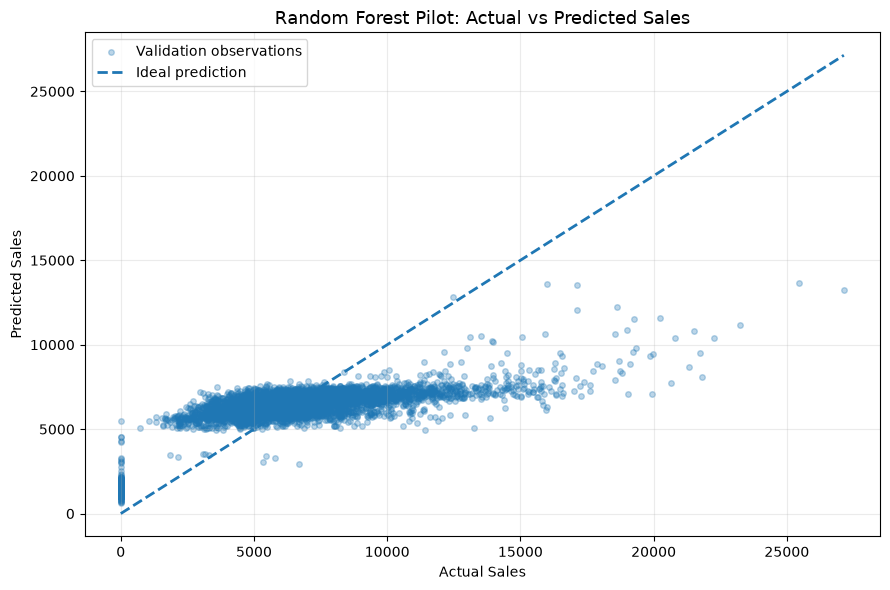

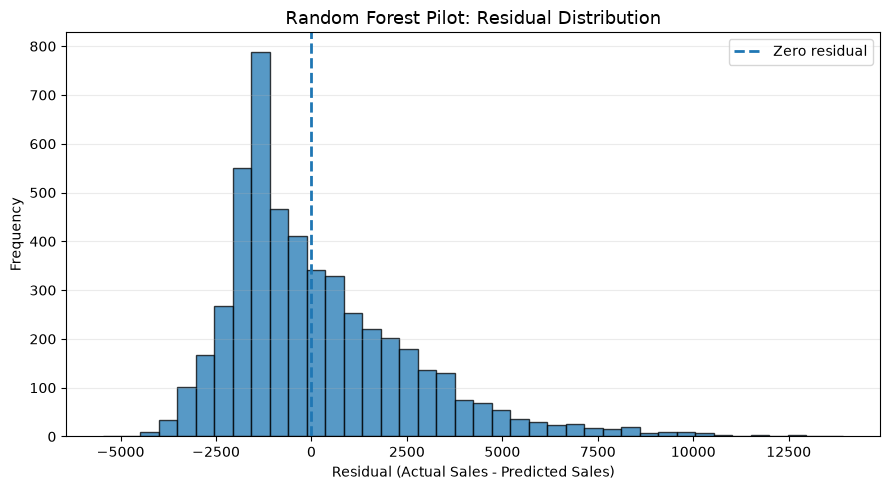

2026-11-05 17:11:46,465 | INFO | Project6_ML_Modeling | Section 5 completed successfully. Random Forest pilot predictions, evaluation table and diagnostic graphs were generated.



SECTION 5 FINAL VALIDATION
Pilot training rows: 60,000
Validation rows: 46,830
Processed feature count: 1149
Pilot evaluation CSV                    : True
Actual versus predicted graph           : True
Residual distribution graph             : True

SECTION 5 COMPLETED SUCCESSFULLY: True


In [21]:

# ============================================================
# PROJECT 6 - NOTEBOOK 04
# SECTION 5: RANDOM FOREST REGRESSION PILOT MODEL
# ============================================================

import matplotlib.pyplot as plt


# STEP 1: CHECK PREVIOUS SECTIONS

if "section_4_successful" not in globals() or not section_4_successful:

    raise RuntimeError(
        "Section 4 has not completed successfully. "
        "Run Section 4 before Section 5."
    )


logger.info(
    "Section 5 started: developing Random Forest pilot model."
)


# STEP 2: DEFINE PILOT SAMPLE SIZE

# We will use a reproducible sample from training data only.
# The full validation dataset will remain untouched.

PILOT_SAMPLE_SIZE = 60000

actual_pilot_size = min(
    PILOT_SAMPLE_SIZE,
    X_train_processed.shape[0]
)


if actual_pilot_size < 1000:

    raise ValueError(
        "Insufficient training rows for the Random Forest pilot."
    )


# STEP 3: SELECT REPRODUCIBLE TRAINING ROWS

rng = np.random.default_rng(
    RANDOM_STATE
)


pilot_indices = np.sort(
    rng.choice(
        X_train_processed.shape[0],
        size=actual_pilot_size,
        replace=False
    )
)


# Extract only the selected sparse training rows.

X_train_pilot = X_train_processed[
    pilot_indices
].tocsr()


# Select their corresponding Sales targets.

y_train_pilot = y_train[
    pilot_indices
]


# STEP 4: VALIDATE THE PILOT SAMPLE

if not sp.issparse(X_train_pilot):

    raise TypeError(
        "Pilot training matrix is not sparse."
    )


if X_train_pilot.shape[0] != len(y_train_pilot):

    raise ValueError(
        "Pilot features and target rows are not aligned."
    )


if X_train_pilot.shape[1] != X_valid_processed.shape[1]:

    raise ValueError(
        "Pilot and validation feature counts do not match."
    )


if not np.isfinite(y_train_pilot).all():

    raise ValueError(
        "Pilot Sales target contains invalid values."
    )


# STEP 5: CREATE A PILOT SAMPLE REPRESENTATION TABLE

def create_pilot_profile(dataset_name, sales_values):
    """
    Summarize Sales distribution for the full training
    dataset or selected pilot sample.
    """

    sales_values = np.asarray(
        sales_values,
        dtype=np.float64
    )

    zero_count = int(
        np.count_nonzero(sales_values == 0)
    )

    return {

        "Dataset": dataset_name,

        "Rows": len(sales_values),

        "Zero_Sales_Rows": zero_count,

        "Zero_Sales_Percent": (
            zero_count / len(sales_values) * 100
        ),

        "Mean_Sales": float(
            np.mean(sales_values)
        ),

        "Median_Sales": float(
            np.median(sales_values)
        )

    }


pilot_sample_profile = pd.DataFrame(
    [
        create_pilot_profile(
            "Full Training",
            y_train
        ),

        create_pilot_profile(
            "Random Pilot Sample",
            y_train_pilot
        )
    ]
)


print("=" * 90)

print("PILOT SAMPLE REPRESENTATION")

print("=" * 90)


display(
    pilot_sample_profile.style
    .format({
        "Rows": "{:,.0f}",
        "Zero_Sales_Rows": "{:,.0f}",
        "Zero_Sales_Percent": "{:.2f}%",
        "Mean_Sales": "{:,.2f}",
        "Median_Sales": "{:,.2f}"
    })
    .hide(axis="index")
    .set_caption(
        "Full training dataset versus selected pilot sample"
    )
)


# STEP 6: TRAIN A SAMPLE-SIZE-MATCHED BASELINE

# This additional baseline is fitted on exactly the same
# pilot sample used by Random Forest.

pilot_baseline_pipeline = Pipeline(
    steps=[
        (
            "regressor",
            DummyRegressor(
                strategy="mean"
            )
        )
    ]
)


pilot_baseline_pipeline.fit(
    X_train_pilot,
    y_train_pilot
)


pilot_baseline_valid_predictions = (
    pilot_baseline_pipeline.predict(
        X_valid_processed
    )
)


pilot_baseline_valid_metrics = calculate_sales_metrics(
    y_true=y_valid,
    y_pred=pilot_baseline_valid_predictions,
    dataset_name="Validation"
)


# STEP 7: DEFINE RANDOM FOREST PILOT PARAMETERS

rf_pilot_parameters = {

    "n_estimators": 40,

    "max_depth": 18,

    "min_samples_split": 20,

    "min_samples_leaf": 10,

    "max_features": "sqrt",

    "bootstrap": True,

    "max_samples": 0.8,

    "criterion": "squared_error",

    "random_state": RANDOM_STATE,

    "n_jobs": 2

}


print("\nRANDOM FOREST PILOT CONFIGURATION")

print("-" * 90)


for parameter_name, parameter_value in rf_pilot_parameters.items():

    print(
        f"{parameter_name:<25}: {parameter_value}"
    )


# STEP 8: CREATE RANDOM FOREST SCIKIT-LEARN PIPELINE

rf_pilot_pipeline = Pipeline(
    steps=[
        (
            "regressor",
            RandomForestRegressor(
                **rf_pilot_parameters
            )
        )
    ]
)


# STEP 9: TRAIN RANDOM FOREST ON THE PILOT SAMPLE

print("\nTraining Random Forest pilot model...")

print(
    f"Training rows: {X_train_pilot.shape[0]:,}"
)

print(
    f"Processed features: {X_train_pilot.shape[1]:,}"
)


rf_pilot_pipeline.fit(
    X_train_pilot,
    y_train_pilot
)


logger.info(
    "Random Forest pilot model fitted successfully."
)


# STEP 10: GENERATE VALIDATION PREDICTIONS

# The model is not fitted again on validation data.

rf_pilot_valid_predictions = (
    rf_pilot_pipeline.predict(
        X_valid_processed
    )
)


# STEP 11: VALIDATE PREDICTIONS

if len(rf_pilot_valid_predictions) != len(y_valid):

    raise ValueError(
        "Random Forest validation prediction count "
        "does not match validation target count."
    )


if not np.isfinite(rf_pilot_valid_predictions).all():

    raise ValueError(
        "Random Forest predictions contain NaN or infinity."
    )


if (rf_pilot_valid_predictions < 0).any():

    raise ValueError(
        "Random Forest predictions contain negative Sales."
    )


if len(pilot_baseline_valid_predictions) != len(y_valid):

    raise ValueError(
        "Pilot baseline prediction count is incorrect."
    )


# STEP 12: CALCULATE RANDOM FOREST VALIDATION METRICS

rf_pilot_valid_metrics = calculate_sales_metrics(
    y_true=y_valid,
    y_pred=rf_pilot_valid_predictions,
    dataset_name="Validation"
)


# STEP 13: CREATE PILOT MODEL COMPARISON TABLE

# All three models are evaluated on the same validation rows:
# 1. Full training DummyRegressor
# 2. Pilot-sample DummyRegressor
# 3. Pilot-sample RandomForestRegressor

pilot_comparison_df = pd.DataFrame([

    {

        "Model": "DummyRegressor - Full Training",

        "Training_Rows": len(y_train),

        "MAE": baseline_valid_metrics["MAE"],

        "RMSE": baseline_valid_metrics["RMSE"],

        "RMSPE_Percent":
            baseline_valid_metrics["RMSPE_Percent"]

    },

    {

        "Model": "DummyRegressor - Pilot Sample",

        "Training_Rows": len(y_train_pilot),

        "MAE": pilot_baseline_valid_metrics["MAE"],

        "RMSE": pilot_baseline_valid_metrics["RMSE"],

        "RMSPE_Percent":
            pilot_baseline_valid_metrics["RMSPE_Percent"]

    },

    {

        "Model": "Random Forest - Pilot",

        "Training_Rows": len(y_train_pilot),

        "MAE": rf_pilot_valid_metrics["MAE"],

        "RMSE": rf_pilot_valid_metrics["RMSE"],

        "RMSPE_Percent":
            rf_pilot_valid_metrics["RMSPE_Percent"]

    }

])


print("\n" + "=" * 90)

print("PILOT MODEL VALIDATION COMPARISON")

print("=" * 90)


display(
    pilot_comparison_df.style
    .format({
        "Training_Rows": "{:,.0f}",
        "MAE": "{:,.2f}",
        "RMSE": "{:,.2f}",
        "RMSPE_Percent": "{:.2f}%"
    })
    .hide(axis="index")
    .background_gradient(
        subset=["RMSPE_Percent"],
        cmap="YlGnBu"
    )
    .set_caption(
        "Validation metrics – lower error is better"
    )
)


# STEP 14: CREATE ACTUAL VS PREDICTED SCATTER PLOT

# Plot a reproducible sample of validation observations
# to keep the graph readable.

plot_sample_size = min(
    5000,
    len(y_valid)
)


plot_rng = np.random.default_rng(
    RANDOM_STATE + 1
)


plot_indices = np.sort(
    plot_rng.choice(
        len(y_valid),
        size=plot_sample_size,
        replace=False
    )
)


actual_plot_values = y_valid[
    plot_indices
]


predicted_plot_values = rf_pilot_valid_predictions[
    plot_indices
]


fig, ax = plt.subplots(
    figsize=(9, 6)
)


ax.scatter(
    actual_plot_values,
    predicted_plot_values,
    alpha=0.30,
    s=16,
    label="Validation observations"
)


# The diagonal line represents perfect predictions.

plot_minimum = float(
    min(
        actual_plot_values.min(),
        predicted_plot_values.min()
    )
)


plot_maximum = float(
    max(
        actual_plot_values.max(),
        predicted_plot_values.max()
    )
)


if plot_minimum == plot_maximum:

    plot_maximum = plot_minimum + 1


ax.plot(
    [plot_minimum, plot_maximum],
    [plot_minimum, plot_maximum],
    linestyle="--",
    linewidth=2,
    label="Ideal prediction"
)


ax.set_title(
    "Random Forest Pilot: Actual vs Predicted Sales",
    fontsize=13
)


ax.set_xlabel(
    "Actual Sales"
)


ax.set_ylabel(
    "Predicted Sales"
)


ax.legend()

ax.grid(
    True,
    alpha=0.25
)


fig.tight_layout()


actual_vs_predicted_path = (
    EVALUATION_DIR
    / "rf_pilot_actual_vs_predicted.png"
)


fig.savefig(
    actual_vs_predicted_path,
    dpi=150,
    bbox_inches="tight"
)


plt.show()

plt.close(fig)


# STEP 15: CREATE RESIDUAL DISTRIBUTION HISTOGRAM

# Residual = Actual Sales - Predicted Sales
# Positive residual: model under-predicted Sales.
# Negative residual: model over-predicted Sales.

sample_residuals = (
    actual_plot_values - predicted_plot_values
)


fig, ax = plt.subplots(
    figsize=(9, 5)
)


ax.hist(
    sample_residuals,
    bins=40,
    edgecolor="black",
    alpha=0.75
)


ax.axvline(
    0,
    linestyle="--",
    linewidth=2,
    label="Zero residual"
)


ax.set_title(
    "Random Forest Pilot: Residual Distribution",
    fontsize=13
)


ax.set_xlabel(
    "Residual (Actual Sales - Predicted Sales)"
)


ax.set_ylabel(
    "Frequency"
)


ax.legend()

ax.grid(
    axis="y",
    alpha=0.25
)


fig.tight_layout()


residual_plot_path = (
    EVALUATION_DIR
    / "rf_pilot_residual_distribution.png"
)


fig.savefig(
    residual_plot_path,
    dpi=150,
    bbox_inches="tight"
)


plt.show()

plt.close(fig)


# STEP 16: SAVE PILOT EVALUATION TABLE

pilot_evaluation_path = (
    EVALUATION_DIR
    / "random_forest_pilot_evaluation.csv"
)


pilot_comparison_df.to_csv(
    pilot_evaluation_path,
    index=False
)


# STEP 17: VERIFY SAVED OUTPUT FILES

saved_pilot_outputs = {

    "Pilot evaluation CSV":
        pilot_evaluation_path,

    "Actual versus predicted graph":
        actual_vs_predicted_path,

    "Residual distribution graph":
        residual_plot_path

}


saved_output_checks = {

    name: (
        path.is_file()
        and path.stat().st_size > 0
    )

    for name, path in saved_pilot_outputs.items()

}


# STEP 18: FINAL SECTION VALIDATION

pilot_metric_values = pilot_comparison_df[
    [
        "MAE",
        "RMSE",
        "RMSPE_Percent"
    ]
].to_numpy(dtype=float)


section_5_successful = (

    X_train_pilot.shape[0] == len(y_train_pilot)

    and X_train_pilot.shape[0] == actual_pilot_size

    and len(rf_pilot_valid_predictions) == len(y_valid)

    and np.isfinite(rf_pilot_valid_predictions).all()

    and np.isfinite(pilot_metric_values).all()

    and all(saved_output_checks.values())

)


print("\n" + "=" * 90)

print("SECTION 5 FINAL VALIDATION")

print("=" * 90)


print(
    "Pilot training rows:",
    f"{len(y_train_pilot):,}"
)


print(
    "Validation rows:",
    f"{len(y_valid):,}"
)


print(
    "Processed feature count:",
    X_train_pilot.shape[1]
)


for check_name, check_status in saved_output_checks.items():

    print(
        f"{check_name:<40}: {check_status}"
    )


print(
    "\nSECTION 5 COMPLETED SUCCESSFULLY:",
    section_5_successful
)


print("=" * 90)


if not section_5_successful:

    raise RuntimeError(
        "Section 5 pilot model validation failed. "
        "Review the output before proceeding."
    )


logger.info(
    "Section 5 completed successfully. "
    "Random Forest pilot predictions, evaluation table "
    "and diagnostic graphs were generated."
)



# SECTION 6: FORMAL MODEL COMPARISON AND PERFORMANCE ANALYSIS

## Purpose

Formally compare the Dummy Regression baseline and Random Forest pilot model using the predictions generated in the previous sections.

The purpose is to determine whether the initial Random Forest model provides a measurable improvement over the simple baseline.

## Models included in the comparison

1. DummyRegressor trained on the complete training dataset.
2. DummyRegressor trained on the 60,000-row pilot sample.
3. RandomForestRegressor trained on the same 60,000-row pilot sample.

All three models are evaluated on the same chronological validation dataset.

## Evaluation metrics

- **RMSPE:** Primary model-comparison metric because it measures relative prediction error across stores with different sales volumes.
- **MAE:** Measures average absolute prediction error in sales units.
- **RMSE:** Gives greater weight to large prediction errors.

RMSPE is calculated only for observations with positive actual Sales. MAE and RMSE include all validation observations, including zero-sales rows.

## Key activities

1. Recalculate validation metrics from the stored predictions.
2. Verify that the recalculated metrics match the previous sections.
3. Create a consolidated and professionally formatted comparison table.
4. Calculate relative error reduction against both baseline models.
5. Identify the best current pilot result for each metric.
6. Create separate comparison charts for MAE, RMSE and RMSPE.
7. Create a chart showing relative error reduction against the pilot-size DummyRegressor.
8. Save all comparison tables and graphs in the model evaluation directory.

## Important methodology

- No model is retrained in this section.
- All model comparisons use the same validation observations.
- The pilot-size DummyRegressor is particularly important because it uses the same number of training rows as the Random Forest pilot.
- The complete-training baseline is retained as an additional reference.
- The pilot Random Forest is not declared the final model. Further model development and tuning are required.

## Expected outcome

A `model_comparison_df`, a `relative_improvement_df`, metric comparison graphs and saved evaluation files.

The section will finish with `section_6_successful = True` only after metric reproducibility, comparison calculations and saved-output checks pass.


2026-11-05 17:11:46,528 | INFO | Project6_ML_Modeling | Section 6 started: formal model comparison.


MODEL COMPARISON - VALIDATION DATA


Model,Training_Rows,Validation_Rows,MAE,RMSE,RMSPE_Percent
DummyRegressor - Full Training,"970,379","46,830","2,757.65","3,733.83",45.78%
DummyRegressor - Pilot Sample,"60,000","46,830","2,758.12","3,734.57",45.69%
Random Forest - Pilot,"60,000","46,830","1,847.65","2,525.37",43.25%



RANDOM FOREST RELATIVE ERROR REDUCTION


Reference_Model,Metric,Reference_Value,Random_Forest_Value,Error_Reduction_Percent
DummyRegressor - Pilot Sample,MAE,"2,758.12","1,847.65",33.01%
DummyRegressor - Pilot Sample,RMSE,"3,734.57","2,525.37",32.38%
DummyRegressor - Pilot Sample,RMSPE_Percent,45.69,43.25,5.35%
DummyRegressor - Full Training,MAE,"2,757.65","1,847.65",33.00%
DummyRegressor - Full Training,RMSE,"3,733.83","2,525.37",32.37%
DummyRegressor - Full Training,RMSPE_Percent,45.78,43.25,5.52%



BEST MODEL BY METRIC
MAE                 : Random Forest - Pilot
RMSE                : Random Forest - Pilot
RMSPE_Percent       : Random Forest - Pilot

RF Pilot better than pilot Dummy on all three metrics: True


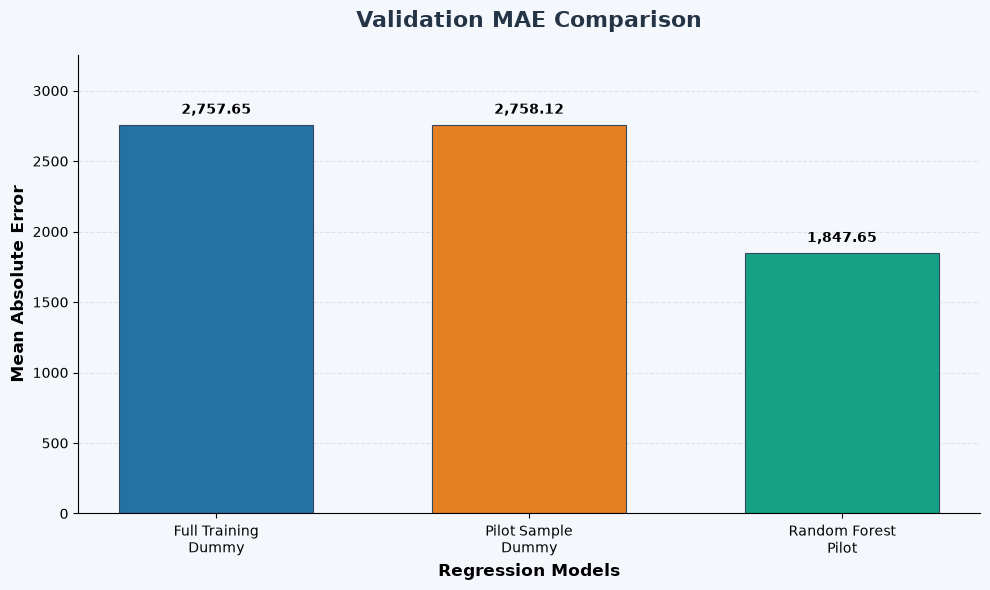

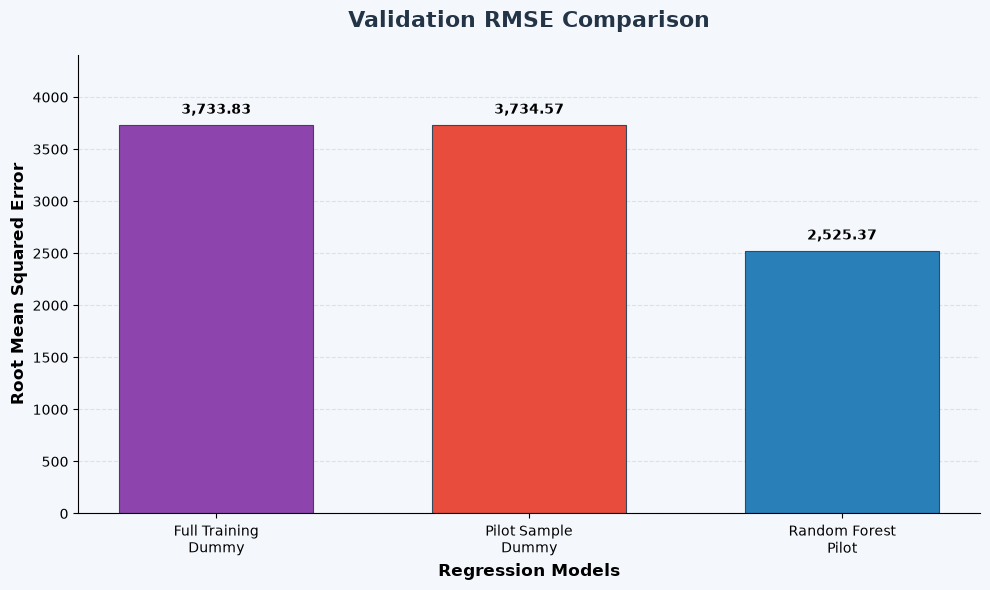

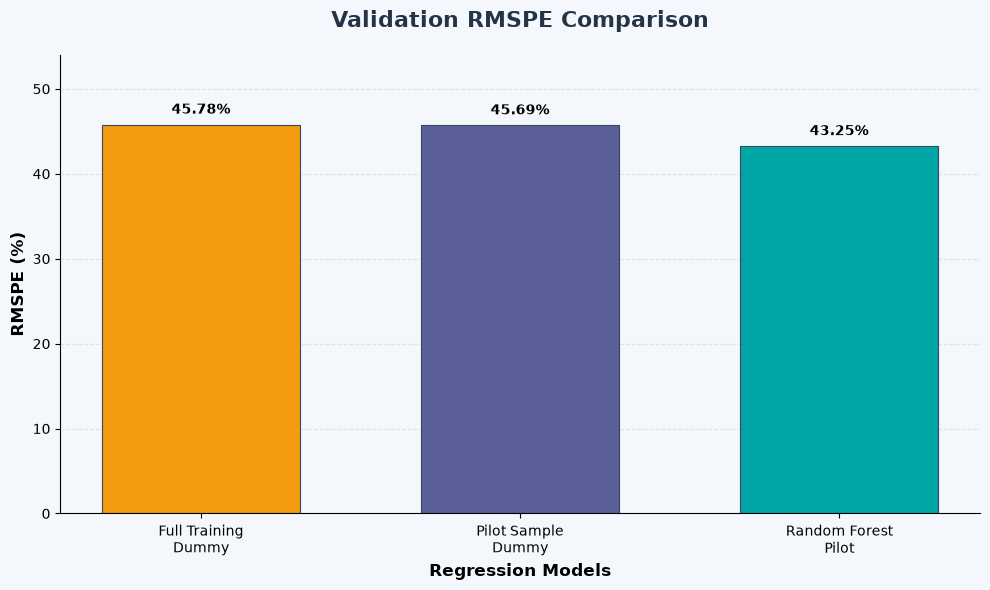

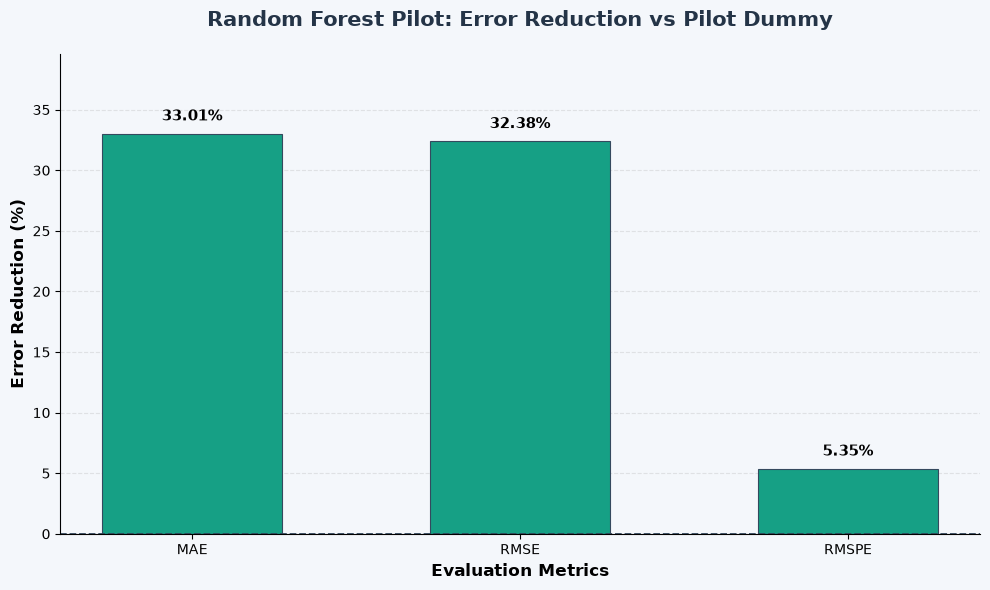

2026-11-05 17:11:47,516 | INFO | Project6_ML_Modeling | Section 6 completed successfully. Comparison tables, relative improvements and four colorful graphs were saved.



SECTION 6 FINAL VALIDATION
Prediction arrays valid: True
Metric reproducibility: True
Comparison metrics finite: True
Improvement calculations finite: True

Saved output files:
section6_model_comparison.csv                          : True
section6_relative_improvement.csv                      : True
section6_relative_error_reduction.png                  : True
section6_mae_comparison.png                            : True
section6_rmse_comparison.png                           : True
section6_rmspe_percent_comparison.png                  : True

SECTION 6 COMPLETED SUCCESSFULLY: True


In [22]:

# ============================================================
# PROJECT 6 - NOTEBOOK 04
# SECTION 6: FORMAL MODEL COMPARISON AND PERFORMANCE ANALYSIS
# ============================================================

from IPython.display import display
import matplotlib.pyplot as plt


# STEP 1: CHECK PREVIOUS SECTIONS

if "section_5_successful" not in globals() or not section_5_successful:
    raise RuntimeError(
        "Section 5 must complete successfully before Section 6."
    )


required_variables = [
    "baseline_valid_predictions",
    "pilot_baseline_valid_predictions",
    "rf_pilot_valid_predictions",
    "baseline_valid_metrics",
    "pilot_baseline_valid_metrics",
    "rf_pilot_valid_metrics",
    "calculate_sales_metrics",
    "y_valid",
    "y_train",
    "y_train_pilot",
    "EVALUATION_DIR",
    "logger"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing Section 6 variables: {missing_variables}"
    )


logger.info("Section 6 started: formal model comparison.")


# STEP 2: VERIFY VALIDATION PREDICTION ARRAYS

prediction_sets = {
    "Full Training Dummy": baseline_valid_predictions,
    "Pilot Sample Dummy": pilot_baseline_valid_predictions,
    "Random Forest Pilot": rf_pilot_valid_predictions
}

prediction_checks = {}

for model_name, predictions in prediction_sets.items():

    predictions = np.asarray(predictions)

    prediction_checks[model_name] = (
        predictions.ndim == 1
        and len(predictions) == len(y_valid)
        and np.isfinite(predictions).all()
    )

if not all(prediction_checks.values()):
    raise ValueError(
        f"Prediction validation failed: {prediction_checks}"
    )


# STEP 3: RECALCULATE VALIDATION METRICS

model_predictions = {

    "DummyRegressor - Full Training":
        baseline_valid_predictions,

    "DummyRegressor - Pilot Sample":
        pilot_baseline_valid_predictions,

    "Random Forest - Pilot":
        rf_pilot_valid_predictions
}

previous_metrics = {

    "DummyRegressor - Full Training":
        baseline_valid_metrics,

    "DummyRegressor - Pilot Sample":
        pilot_baseline_valid_metrics,

    "Random Forest - Pilot":
        rf_pilot_valid_metrics
}

metric_columns = [
    "MAE",
    "RMSE",
    "RMSPE_Percent"
]

recalculated_metrics = {}
metric_reproducibility_checks = {}

for model_name, predictions in model_predictions.items():

    current_metrics = calculate_sales_metrics(
        y_true=y_valid,
        y_pred=predictions,
        dataset_name="Validation"
    )

    recalculated_metrics[model_name] = current_metrics

    for metric_name in metric_columns:

        metric_reproducibility_checks[
            f"{model_name} - {metric_name}"
        ] = np.isclose(
            current_metrics[metric_name],
            previous_metrics[model_name][metric_name],
            rtol=1e-9,
            atol=1e-6
        )


if not all(metric_reproducibility_checks.values()):

    raise ValueError(
        "Recalculated metrics do not match earlier sections. "
        f"Failed checks: "
        f"{[k for k, v in metric_reproducibility_checks.items() if not v]}"
    )


# STEP 4: CREATE CONSOLIDATED MODEL COMPARISON TABLE

training_rows = {

    "DummyRegressor - Full Training":
        len(y_train),

    "DummyRegressor - Pilot Sample":
        len(y_train_pilot),

    "Random Forest - Pilot":
        len(y_train_pilot)
}

comparison_records = []

for model_name, metrics in recalculated_metrics.items():

    comparison_records.append({

        "Model": model_name,

        "Training_Rows": training_rows[model_name],

        "Validation_Rows": len(y_valid),

        "MAE": metrics["MAE"],

        "RMSE": metrics["RMSE"],

        "RMSPE_Percent": metrics["RMSPE_Percent"]

    })


model_comparison_df = pd.DataFrame(
    comparison_records
)


print("=" * 100)
print("MODEL COMPARISON - VALIDATION DATA")
print("=" * 100)


display(
    model_comparison_df.style
    .format({
        "Training_Rows": "{:,.0f}",
        "Validation_Rows": "{:,.0f}",
        "MAE": "{:,.2f}",
        "RMSE": "{:,.2f}",
        "RMSPE_Percent": "{:.2f}%"
    })
    .hide(axis="index")
    .highlight_min(
        subset=metric_columns,
        color="#D9EAD3"
    )
    .set_caption(
        "Validation performance: lower error is better"
    )
)


# STEP 5: IDENTIFY BEST CURRENT MODEL FOR EACH METRIC

best_model_by_metric = {}

for metric_name in metric_columns:

    best_index = model_comparison_df[
        metric_name
    ].idxmin()

    best_model_by_metric[metric_name] = (
        model_comparison_df.loc[
            best_index, "Model"
        ]
    )


# STEP 6: CALCULATE RELATIVE ERROR REDUCTION

# Compare Random Forest with both baselines.
# Positive percentage means Random Forest reduced error.

reference_models = [
    "DummyRegressor - Pilot Sample",
    "DummyRegressor - Full Training"
]

rf_metrics = recalculated_metrics[
    "Random Forest - Pilot"
]

improvement_records = []

for reference_name in reference_models:

    reference_metrics = recalculated_metrics[
        reference_name
    ]

    for metric_name in metric_columns:

        reference_value = reference_metrics[metric_name]

        rf_value = rf_metrics[metric_name]

        if reference_value == 0:
            raise ZeroDivisionError(
                f"Cannot calculate improvement for {metric_name}."
            )

        reduction = (
            (reference_value - rf_value)
            / reference_value
        ) * 100

        improvement_records.append({

            "Reference_Model": reference_name,

            "Metric": metric_name,

            "Reference_Value": reference_value,

            "Random_Forest_Value": rf_value,

            "Error_Reduction_Percent": reduction

        })


relative_improvement_df = pd.DataFrame(
    improvement_records
)


print("\n" + "=" * 100)
print("RANDOM FOREST RELATIVE ERROR REDUCTION")
print("=" * 100)


display(
    relative_improvement_df.style
    .format({
        "Reference_Value": "{:,.2f}",
        "Random_Forest_Value": "{:,.2f}",
        "Error_Reduction_Percent": "{:.2f}%"
    })
    .hide(axis="index")
    .set_caption(
        "Positive reduction indicates an improvement"
    )
)


# STEP 7: CHECK IMPROVEMENT AGAINST MATCHED PILOT BASELINE

rf_beats_pilot_dummy = all(
    rf_metrics[metric]
    < recalculated_metrics[
        "DummyRegressor - Pilot Sample"
    ][metric]
    for metric in metric_columns
)

print("\nBEST MODEL BY METRIC")

for metric_name, model_name in best_model_by_metric.items():

    print(f"{metric_name:<20}: {model_name}")


print(
    "\nRF Pilot better than pilot Dummy on all three metrics:",
    rf_beats_pilot_dummy
)


# STEP 8: CREATE COLORFUL MAE, RMSE AND RMSPE COMPARISON GRAPHS

chart_specs = [

    (
        "MAE",
        "Validation MAE Comparison",
        "Mean Absolute Error",
        ["#2471A3", "#E67E22", "#16A085"]
    ),

    (
        "RMSE",
        "Validation RMSE Comparison",
        "Root Mean Squared Error",
        ["#8E44AD", "#E74C3C", "#2980B9"]
    ),

    (
        "RMSPE_Percent",
        "Validation RMSPE Comparison",
        "RMSPE (%)",
        ["#F39C12", "#5B5F97", "#00A6A6"]
    )

]

short_model_names = [
    "Full Training\nDummy",
    "Pilot Sample\nDummy",
    "Random Forest\nPilot"
]

comparison_chart_paths = []

for metric_name, chart_title, y_label, colors in chart_specs:

    values = model_comparison_df[
        metric_name
    ].to_numpy(dtype=float)

    fig, ax = plt.subplots(
        figsize=(10, 6),
        facecolor="#F4F7FB"
    )

    ax.set_facecolor("#F4F7FB")

    bars = ax.bar(
        short_model_names,
        values,
        color=colors,
        edgecolor="#34495E",
        linewidth=0.8,
        width=0.62
    )

    ax.set_title(
        chart_title,
        fontsize=16,
        fontweight="bold",
        color="#243447",
        pad=20
    )

    ax.set_xlabel(
        "Regression Models",
        fontsize=12,
        fontweight="bold"
    )

    ax.set_ylabel(
        y_label,
        fontsize=12,
        fontweight="bold"
    )

    for bar, value in zip(bars, values):

        suffix = "%" if metric_name == "RMSPE_Percent" else ""

        ax.annotate(
            f"{value:,.2f}{suffix}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height()
            ),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            fontsize=10,
            fontweight="bold"
        )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.30
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.margins(y=0.18)

    fig.tight_layout()

    chart_path = (
        EVALUATION_DIR
        / f"section6_{metric_name.lower()}_comparison.png"
    )

    fig.savefig(
        chart_path,
        dpi=180,
        bbox_inches="tight",
        facecolor=fig.get_facecolor()
    )

    plt.show()
    plt.close(fig)

    comparison_chart_paths.append(chart_path)


# STEP 9: CREATE COLORFUL RELATIVE IMPROVEMENT GRAPH

pilot_improvement = relative_improvement_df[
    relative_improvement_df["Reference_Model"]
    == "DummyRegressor - Pilot Sample"
].set_index("Metric").reindex(metric_columns)

improvement_values = pilot_improvement[
    "Error_Reduction_Percent"
].to_numpy(dtype=float)


improvement_colors = [

    "#16A085" if value > 0
    else "#E74C3C" if value < 0
    else "#7F8C8D"

    for value in improvement_values
]


fig, ax = plt.subplots(
    figsize=(10, 6),
    facecolor="#F4F7FB"
)

ax.set_facecolor("#F4F7FB")

bars = ax.bar(
    ["MAE", "RMSE", "RMSPE"],
    improvement_values,
    color=improvement_colors,
    edgecolor="#34495E",
    linewidth=0.8,
    width=0.55
)

ax.axhline(
    0,
    color="#34495E",
    linewidth=1.3,
    linestyle="--"
)

ax.set_title(
    "Random Forest Pilot: Error Reduction vs Pilot Dummy",
    fontsize=15,
    fontweight="bold",
    color="#243447",
    pad=20
)

ax.set_xlabel(
    "Evaluation Metrics",
    fontsize=12,
    fontweight="bold"
)

ax.set_ylabel(
    "Error Reduction (%)",
    fontsize=12,
    fontweight="bold"
)

for bar, value in zip(bars, improvement_values):

    positive = value >= 0

    ax.annotate(
        f"{value:.2f}%",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 7 if positive else -16),
        textcoords="offset points",
        ha="center",
        va="bottom" if positive else "top",
        fontsize=11,
        fontweight="bold"
    )

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.30
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.margins(y=0.20)

fig.tight_layout()


improvement_chart_path = (
    EVALUATION_DIR
    / "section6_relative_error_reduction.png"
)

fig.savefig(
    improvement_chart_path,
    dpi=180,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()
plt.close(fig)


# STEP 10: SAVE COMPARISON TABLES

comparison_csv_path = (
    EVALUATION_DIR
    / "section6_model_comparison.csv"
)

improvement_csv_path = (
    EVALUATION_DIR
    / "section6_relative_improvement.csv"
)

model_comparison_df.to_csv(
    comparison_csv_path,
    index=False
)

relative_improvement_df.to_csv(
    improvement_csv_path,
    index=False
)


# STEP 11: VERIFY ALL SAVED OUTPUT FILES

section6_output_paths = [
    comparison_csv_path,
    improvement_csv_path,
    improvement_chart_path,
    *comparison_chart_paths
]

saved_output_checks = {

    path.name: (
        path.is_file()
        and path.stat().st_size > 0
    )

    for path in section6_output_paths
}


if not all(saved_output_checks.values()):

    raise IOError(
        "One or more Section 6 files were not saved: "
        f"{saved_output_checks}"
    )


# STEP 12: FINAL SECTION VALIDATION

all_metrics_finite = bool(
    np.isfinite(
        model_comparison_df[
            metric_columns
        ].to_numpy(dtype=float)
    ).all()
)

all_improvements_finite = bool(
    np.isfinite(
        relative_improvement_df[
            "Error_Reduction_Percent"
        ].to_numpy(dtype=float)
    ).all()
)

section_6_successful = (

    all(prediction_checks.values())

    and all(metric_reproducibility_checks.values())

    and all_metrics_finite

    and all_improvements_finite

    and len(model_comparison_df) == 3

    and len(relative_improvement_df) == 6

    and all(saved_output_checks.values())

)


print("\n" + "=" * 100)
print("SECTION 6 FINAL VALIDATION")
print("=" * 100)

print(
    "Prediction arrays valid:",
    all(prediction_checks.values())
)

print(
    "Metric reproducibility:",
    all(metric_reproducibility_checks.values())
)

print(
    "Comparison metrics finite:",
    all_metrics_finite
)

print(
    "Improvement calculations finite:",
    all_improvements_finite
)

print("\nSaved output files:")

for name, status in saved_output_checks.items():

    print(f"{name:<55}: {status}")


print(
    "\nSECTION 6 COMPLETED SUCCESSFULLY:",
    section_6_successful
)

print("=" * 100)


if not section_6_successful:

    raise RuntimeError(
        "Section 6 validation failed. "
        "Review the output before continuing."
    )


logger.info(
    "Section 6 completed successfully. "
    "Comparison tables, relative improvements and "
    "four colorful graphs were saved."
)



# SECTION 7: RANDOM FOREST HYPERPARAMETER TUNING

## Purpose

Improve the initial Random Forest pilot model by evaluating a small, controlled set of hyperparameter configurations.

The objective is to identify a configuration that provides lower validation RMSPE while also monitoring MAE, RMSE and computational cost.

## Hyperparameters to investigate

1. `n_estimators`: number of decision trees in the forest.
2. `max_depth`: maximum depth of each decision tree.
3. `min_samples_leaf`: minimum observations required in a leaf node.
4. `min_samples_split`: minimum observations required to split an internal node.

## Tuning strategy

Four resource-conscious configurations will be evaluated:

- Compact model: shallower trees.
- Current pilot configuration: reference configuration from Section 5.
- More trees: increase the number of estimators.
- Regularized model: increase minimum samples per leaf.

All candidates will use the same 60,000-row training sample and the same 42-day chronological validation set.

## Evaluation methodology

- Fit each candidate using only the pilot training sample.
- Generate predictions on the complete validation dataset.
- Calculate MAE, RMSE and RMSPE.
- Use RMSPE as the primary model-selection metric.
- Use MAE and RMSE as supporting metrics.
- Record model fitting time to understand computational cost.
- Compare the tuned configuration with the pilot DummyRegressor baseline.

## Important considerations

- The validation dataset is used for model selection, not for fitting.
- The Kaggle test dataset is not used for tuning or hyperparameter selection.
- A small controlled candidate set is used to manage computation and reduce excessive repeated evaluation on the same validation period.
- Randomized or shuffled cross-validation is not used because the project follows a chronological forecasting split.
- The selected configuration is a tuned pilot candidate, not yet a final production model.

## Expected outcome

A `rf_tuning_results_df` table, a selected `best_rf_pipeline`, its validation predictions, model parameters and diagnostic comparison charts.

The section will finish with `section_7_successful = True` only after all candidate models, validation metrics, selection logic and saved outputs pass verification.


2026-11-05 17:11:47,579 | INFO | Project6_ML_Modeling | Section 7 started: Random Forest hyperparameter tuning.


RANDOM FOREST TUNING CONFIGURATIONS


Model,Trees,Max_Depth,Min_Samples_Split,Min_Samples_Leaf,Max_Features,Max_Samples
RF_Compact,40,14,20,10,sqrt,0.800000
RF_Current_Pilot,40,18,20,10,sqrt,0.800000
RF_More_Trees,60,18,20,10,sqrt,0.800000
RF_Regularized,40,18,40,20,sqrt,0.800000



FITTING CANDIDATE 1: RF_Compact

RF_Compact validation results:
MAE: 1,920.28
RMSE: 2,612.31
RMSPE: 44.22%
Fit Time: 0.49 seconds

FITTING CANDIDATE 2: RF_Current_Pilot

RF_Current_Pilot validation results:
MAE: 1,847.65
RMSE: 2,525.37
RMSPE: 43.25%
Fit Time: 0.64 seconds

FITTING CANDIDATE 3: RF_More_Trees

RF_More_Trees validation results:
MAE: 1,898.08
RMSE: 2,570.83
RMSPE: 42.39%
Fit Time: 0.93 seconds

FITTING CANDIDATE 4: RF_Regularized

RF_Regularized validation results:
MAE: 1,942.02
RMSE: 2,662.56
RMSPE: 42.61%
Fit Time: 0.49 seconds

RANDOM FOREST HYPERPARAMETER TUNING RESULTS


Model,Trees,Max_Depth,Min_Samples_Leaf,Min_Samples_Split,MAE,RMSE,RMSPE_Percent,RMSPE_Reduction_vs_Pilot_Dummy_Percent,Fit_Time_Seconds
RF_More_Trees,60,18,10,20,"1,898.08","2,570.83",42.39%,7.23%,0.93s
RF_Regularized,40,18,20,40,"1,942.02","2,662.56",42.61%,6.75%,0.49s
RF_Current_Pilot,40,18,10,20,"1,847.65","2,525.37",43.25%,5.35%,0.64s
RF_Compact,40,14,10,20,"1,920.28","2,612.31",44.22%,3.21%,0.49s



SELECTED RANDOM FOREST CONFIGURATION
Selected Model: RF_More_Trees

Selected Parameters:
n_estimators             : 60
max_depth                : 18
min_samples_split        : 20
min_samples_leaf         : 10
max_features             : sqrt
bootstrap                : True
max_samples              : 0.8
criterion                : squared_error
random_state             : 42
n_jobs                   : 2

Selected Validation Metrics:
MAE: 1,898.08
RMSE: 2,570.83
RMSPE: 42.39%

SELECTED MODEL IMPROVEMENT VS PILOT DUMMY
MAE_Reduction_Percent         : 31.18%
RMSE_Reduction_Percent        : 31.16%
RMSPE_Reduction_Percent       : 7.23%


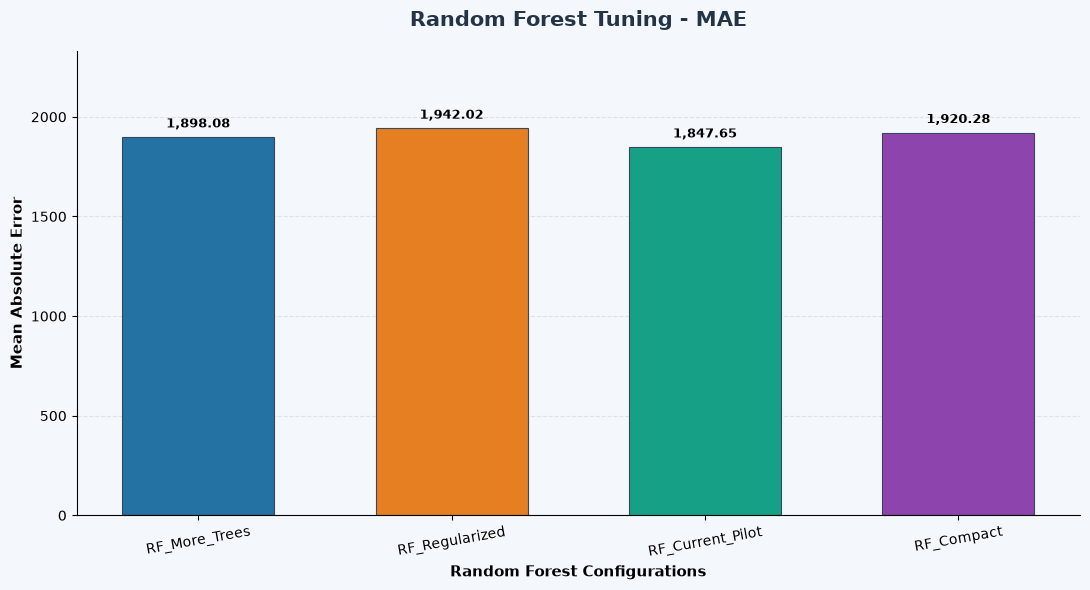

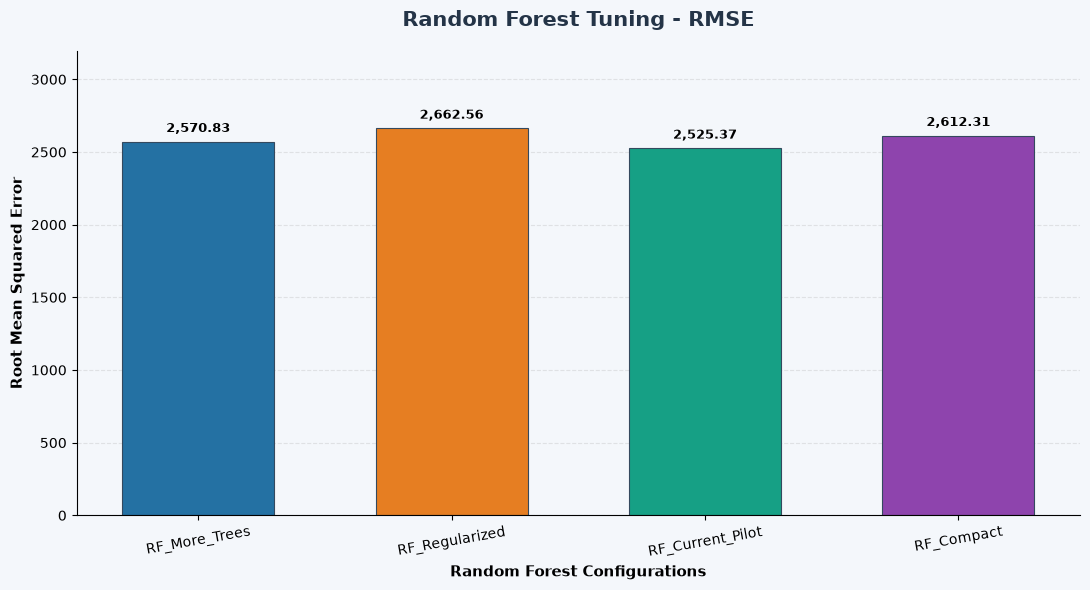

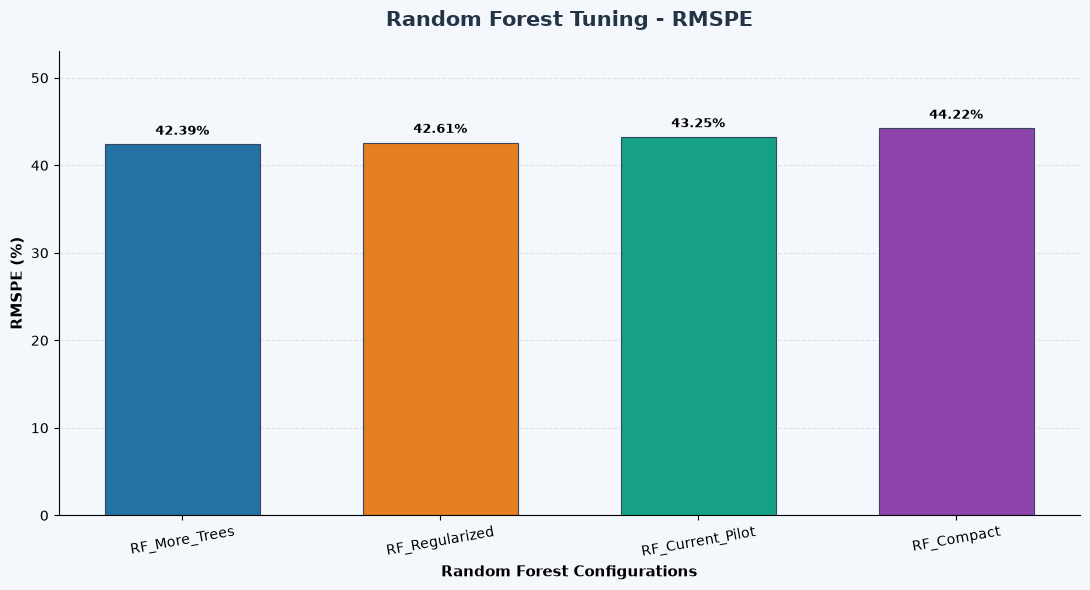

2026-11-05 17:11:52,226 | INFO | Project6_ML_Modeling | Section 7 completed successfully. The best Random Forest pilot configuration was selected using validation RMSPE.



SECTION 7 FINAL VALIDATION
Number of candidate models: 4
Tuning metrics finite: True
Selected prediction count valid: True
Selected model is a Pipeline: True

Saved output files:
section7_random_forest_tuning_results.csv              : True
section7_best_rf_configuration.json                    : True
section7_mae_tuning.png                                : True
section7_rmse_tuning.png                               : True
section7_rmspe_percent_tuning.png                      : True

SECTION 7 COMPLETED SUCCESSFULLY: True


In [23]:

# ============================================================
# PROJECT 6 - NOTEBOOK 04
# SECTION 7: RANDOM FOREST HYPERPARAMETER TUNING
# ============================================================

import time
import gc
import json
import matplotlib.pyplot as plt


# STEP 1: VERIFY PREVIOUS SECTION

if "section_6_successful" not in globals() or not section_6_successful:

    raise RuntimeError(
        "Section 6 has not completed successfully. "
        "Run Section 6 before Section 7."
    )


# STEP 2: VERIFY REQUIRED INPUT VARIABLES

required_variables = [

    "X_train_pilot",

    "y_train_pilot",

    "X_valid_processed",

    "y_valid",

    "calculate_sales_metrics",

    "pilot_baseline_valid_metrics",

    "RANDOM_STATE",

    "EVALUATION_DIR",

    "logger"

]


missing_variables = [

    name

    for name in required_variables

    if name not in globals()

]


if missing_variables:

    raise NameError(
        "Missing variables required for Section 7: "
        f"{missing_variables}"
    )


# STEP 3: VERIFY TRAINING AND VALIDATION DIMENSIONS

if X_train_pilot.shape[0] != len(y_train_pilot):

    raise ValueError(
        "Pilot training features and Sales target "
        "are not aligned."
    )


if X_train_pilot.shape[1] != X_valid_processed.shape[1]:

    raise ValueError(
        "Pilot training and validation feature counts differ."
    )


if X_valid_processed.shape[0] != len(y_valid):

    raise ValueError(
        "Validation features and target are not aligned."
    )


if not sp.issparse(X_train_pilot) or not sp.issparse(X_valid_processed):

    raise TypeError(
        "Training and validation feature matrices "
        "must remain sparse."
    )


if not np.isfinite(y_train_pilot).all():

    raise ValueError(
        "Pilot training target contains invalid values."
    )


if not np.isfinite(y_valid).all():

    raise ValueError(
        "Validation target contains invalid values."
    )


logger.info(
    "Section 7 started: Random Forest hyperparameter tuning."
)


# STEP 4: DEFINE CONTROLLED HYPERPARAMETER CONFIGURATIONS

# All configurations use the same training sample.
# The current pilot model is included as a reference.

rf_tuning_candidates = [

    {

        "model_name": "RF_Compact",

        "parameters": {

            "n_estimators": 40,

            "max_depth": 14,

            "min_samples_split": 20,

            "min_samples_leaf": 10,

            "max_features": "sqrt",

            "bootstrap": True,

            "max_samples": 0.8,

            "criterion": "squared_error",

            "random_state": RANDOM_STATE,

            "n_jobs": 2

        }

    },


    {

        "model_name": "RF_Current_Pilot",

        "parameters": {

            "n_estimators": 40,

            "max_depth": 18,

            "min_samples_split": 20,

            "min_samples_leaf": 10,

            "max_features": "sqrt",

            "bootstrap": True,

            "max_samples": 0.8,

            "criterion": "squared_error",

            "random_state": RANDOM_STATE,

            "n_jobs": 2

        }

    },


    {

        "model_name": "RF_More_Trees",

        "parameters": {

            "n_estimators": 60,

            "max_depth": 18,

            "min_samples_split": 20,

            "min_samples_leaf": 10,

            "max_features": "sqrt",

            "bootstrap": True,

            "max_samples": 0.8,

            "criterion": "squared_error",

            "random_state": RANDOM_STATE,

            "n_jobs": 2

        }

    },


    {

        "model_name": "RF_Regularized",

        "parameters": {

            "n_estimators": 40,

            "max_depth": 18,

            "min_samples_split": 40,

            "min_samples_leaf": 20,

            "max_features": "sqrt",

            "bootstrap": True,

            "max_samples": 0.8,

            "criterion": "squared_error",

            "random_state": RANDOM_STATE,

            "n_jobs": 2

        }

    }

]


# STEP 5: DISPLAY THE CANDIDATE CONFIGURATIONS

candidate_summary_records = []


for candidate in rf_tuning_candidates:

    params = candidate["parameters"]

    candidate_summary_records.append({

        "Model": candidate["model_name"],

        "Trees": params["n_estimators"],

        "Max_Depth": params["max_depth"],

        "Min_Samples_Split": params["min_samples_split"],

        "Min_Samples_Leaf": params["min_samples_leaf"],

        "Max_Features": params["max_features"],

        "Max_Samples": params["max_samples"]

    })


rf_candidate_config_df = pd.DataFrame(
    candidate_summary_records
)


print("=" * 100)

print("RANDOM FOREST TUNING CONFIGURATIONS")

print("=" * 100)


display(

    rf_candidate_config_df.style

    .hide(axis="index")

    .set_caption(
        "Controlled Random Forest candidate configurations"
    )

)


# STEP 6: INITIALIZE TUNING VARIABLES

rf_tuning_records = []

best_rf_pipeline = None

best_rf_valid_predictions = None

best_rf_parameters = None

best_rf_model_name = None

best_rf_metrics = None

best_candidate_key = None


# STEP 7: TRAIN AND EVALUATE EACH CANDIDATE

for candidate_number, candidate in enumerate(
    rf_tuning_candidates,
    start=1
):

    model_name = candidate["model_name"]

    model_parameters = candidate["parameters"]


    print("\n" + "=" * 90)

    print(
        f"FITTING CANDIDATE {candidate_number}: {model_name}"
    )

    print("=" * 90)


    # Create one scikit-learn Pipeline per candidate.

    candidate_pipeline = Pipeline(

        steps=[

            (

                "regressor",

                RandomForestRegressor(
                    **model_parameters
                )

            )

        ]

    )


    # Record fitting time.

    fit_start_time = time.perf_counter()


    # Fit on training sample only.

    candidate_pipeline.fit(
        X_train_pilot,
        y_train_pilot
    )


    fit_time_seconds = (
        time.perf_counter() - fit_start_time
    )


    # Predict on the same untouched validation dataset.

    candidate_predictions = (
        candidate_pipeline.predict(
            X_valid_processed
        )
    )


    # Validate predictions.

    if len(candidate_predictions) != len(y_valid):

        raise ValueError(
            f"{model_name}: Validation prediction count mismatch."
        )


    if not np.isfinite(candidate_predictions).all():

        raise ValueError(
            f"{model_name}: Predictions contain invalid values."
        )


    if (candidate_predictions < 0).any():

        raise ValueError(
            f"{model_name}: Negative sales predictions detected."
        )


    # Calculate validation metrics.

    candidate_metrics = calculate_sales_metrics(

        y_true=y_valid,

        y_pred=candidate_predictions,

        dataset_name="Validation"

    )


    # Calculate improvement against the pilot-size Dummy baseline.

    dummy_rmspe = pilot_baseline_valid_metrics[
        "RMSPE_Percent"
    ]


    rmspe_reduction = (

        (dummy_rmspe - candidate_metrics["RMSPE_Percent"])

        / dummy_rmspe

    ) * 100


    # Store actual results.

    candidate_record = {

        "Model": model_name,

        "Trees": model_parameters["n_estimators"],

        "Max_Depth": model_parameters["max_depth"],

        "Min_Samples_Leaf":
            model_parameters["min_samples_leaf"],

        "Min_Samples_Split":
            model_parameters["min_samples_split"],

        "MAE":
            candidate_metrics["MAE"],

        "RMSE":
            candidate_metrics["RMSE"],

        "RMSPE_Percent":
            candidate_metrics["RMSPE_Percent"],

        "RMSPE_Reduction_vs_Pilot_Dummy_Percent":
            rmspe_reduction,

        "Fit_Time_Seconds":
            fit_time_seconds

    }


    rf_tuning_records.append(
        candidate_record
    )


    # Primary selection: lowest validation RMSPE.
    # Tie-breakers: lower MAE, then lower RMSE.

    candidate_key = (

        candidate_metrics["RMSPE_Percent"],

        candidate_metrics["MAE"],

        candidate_metrics["RMSE"]

    )


    if (

        best_candidate_key is None

        or candidate_key < best_candidate_key

    ):

        best_candidate_key = candidate_key

        best_rf_pipeline = candidate_pipeline

        best_rf_valid_predictions = (
            candidate_predictions.copy()
        )

        best_rf_parameters = dict(
            model_parameters
        )

        best_rf_model_name = model_name

        best_rf_metrics = dict(
            candidate_metrics
        )


    print(
        f"\n{model_name} validation results:"
    )

    print(
        f"MAE: {candidate_metrics['MAE']:,.2f}"
    )

    print(
        f"RMSE: {candidate_metrics['RMSE']:,.2f}"
    )

    print(
        f"RMSPE: {candidate_metrics['RMSPE_Percent']:.2f}%"
    )

    print(
        f"Fit Time: {fit_time_seconds:.2f} seconds"
    )


    # Release the temporary model reference.
    # Only the current best pipeline is retained.

    del candidate_pipeline

    del candidate_predictions

    gc.collect()


# STEP 8: CREATE SORTED TUNING RESULTS TABLE

rf_tuning_results_df = pd.DataFrame(
    rf_tuning_records
)


rf_tuning_results_df = (

    rf_tuning_results_df

    .sort_values(

        by=[

            "RMSPE_Percent",

            "MAE",

            "RMSE"

        ],

        ascending=True

    )

    .reset_index(drop=True)

)


print("\n" + "=" * 110)

print("RANDOM FOREST HYPERPARAMETER TUNING RESULTS")

print("=" * 110)


display(

    rf_tuning_results_df.style

    .format({

        "MAE": "{:,.2f}",

        "RMSE": "{:,.2f}",

        "RMSPE_Percent": "{:.2f}%",

        "RMSPE_Reduction_vs_Pilot_Dummy_Percent": "{:.2f}%",

        "Fit_Time_Seconds": "{:.2f}s"

    })

    .hide(axis="index")

    .highlight_min(

        subset=[

            "MAE",

            "RMSE",

            "RMSPE_Percent"

        ],

        color="#D9EAD3"

    )

    .set_caption(
        "Validation-based hyperparameter tuning – lowest RMSPE is preferred"
    )

)


# STEP 9: VERIFY THE SELECTED MODEL

if best_rf_pipeline is None:

    raise RuntimeError(
        "No best Random Forest model was selected."
    )


if best_rf_valid_predictions is None:

    raise RuntimeError(
        "Selected model validation predictions are missing."
    )


if best_rf_parameters is None or best_rf_metrics is None:

    raise RuntimeError(
        "Selected model configuration or metrics are missing."
    )


if not np.isfinite(best_rf_valid_predictions).all():

    raise ValueError(
        "Selected model predictions contain invalid values."
    )


# STEP 10: DISPLAY THE SELECTED CONFIGURATION

print("\n" + "=" * 100)

print("SELECTED RANDOM FOREST CONFIGURATION")

print("=" * 100)


print(
    "Selected Model:",
    best_rf_model_name
)


print("\nSelected Parameters:")


for parameter_name, parameter_value in best_rf_parameters.items():

    print(
        f"{parameter_name:<25}: {parameter_value}"
    )


print("\nSelected Validation Metrics:")


print(
    f"MAE: {best_rf_metrics['MAE']:,.2f}"
)


print(
    f"RMSE: {best_rf_metrics['RMSE']:,.2f}"
)


print(
    f"RMSPE: {best_rf_metrics['RMSPE_Percent']:.2f}%"
)


# STEP 11: COMPARE SELECTED MODEL WITH PILOT DUMMY

selected_model_vs_dummy = {

    "MAE_Reduction_Percent": (

        (
            pilot_baseline_valid_metrics["MAE"]

            - best_rf_metrics["MAE"]

        )

        / pilot_baseline_valid_metrics["MAE"]

    ) * 100,


    "RMSE_Reduction_Percent": (

        (
            pilot_baseline_valid_metrics["RMSE"]

            - best_rf_metrics["RMSE"]

        )

        / pilot_baseline_valid_metrics["RMSE"]

    ) * 100,


    "RMSPE_Reduction_Percent": (

        (
            pilot_baseline_valid_metrics["RMSPE_Percent"]

            - best_rf_metrics["RMSPE_Percent"]

        )

        / pilot_baseline_valid_metrics["RMSPE_Percent"]

    ) * 100

}


print("\nSELECTED MODEL IMPROVEMENT VS PILOT DUMMY")


for metric_name, improvement in selected_model_vs_dummy.items():

    print(
        f"{metric_name:<30}: {improvement:.2f}%"
    )


# STEP 12: CREATE COLORFUL TUNING COMPARISON GRAPHS

tuning_chart_specs = [

    (

        "MAE",

        "Random Forest Tuning - MAE",

        "Mean Absolute Error"

    ),

    (

        "RMSE",

        "Random Forest Tuning - RMSE",

        "Root Mean Squared Error"

    ),

    (

        "RMSPE_Percent",

        "Random Forest Tuning - RMSPE",

        "RMSPE (%)"

    )

]


candidate_colors = [

    "#2471A3",

    "#E67E22",

    "#16A085",

    "#8E44AD"

]


tuning_chart_paths = []


for metric_name, chart_title, y_label in tuning_chart_specs:

    chart_data = rf_tuning_results_df.copy()


    labels = chart_data["Model"].tolist()


    values = chart_data[
        metric_name
    ].to_numpy(dtype=float)


    fig, ax = plt.subplots(

        figsize=(11, 6),

        facecolor="#F4F7FB"

    )

    ax.set_facecolor("#F4F7FB")


    bars = ax.bar(

        labels,

        values,

        color=candidate_colors[:len(values)],

        edgecolor="#34495E",

        linewidth=0.8,

        width=0.60

    )


    ax.set_title(

        chart_title,

        fontsize=15,

        fontweight="bold",

        color="#243447",

        pad=18

    )


    ax.set_xlabel(

        "Random Forest Configurations",

        fontsize=11,

        fontweight="bold"

    )


    ax.set_ylabel(

        y_label,

        fontsize=11,

        fontweight="bold"

    )


    for bar, value in zip(bars, values):

        suffix = (
            "%"
            if metric_name == "RMSPE_Percent"
            else ""
        )

        ax.annotate(

            f"{value:,.2f}{suffix}",

            xy=(

                bar.get_x() + bar.get_width() / 2,

                bar.get_height()

            ),

            xytext=(0, 7),

            textcoords="offset points",

            ha="center",

            fontsize=9,

            fontweight="bold"

        )


    ax.grid(

        axis="y",

        linestyle="--",

        alpha=0.30

    )


    ax.set_axisbelow(True)

    ax.tick_params(
        axis="x",
        rotation=10
    )


    ax.spines["top"].set_visible(False)

    ax.spines["right"].set_visible(False)


    ax.margins(y=0.20)

    fig.tight_layout()


    chart_path = (

        EVALUATION_DIR

        / f"section7_{metric_name.lower()}_tuning.png"

    )


    fig.savefig(

        chart_path,

        dpi=180,

        bbox_inches="tight",

        facecolor=fig.get_facecolor()

    )


    plt.show()

    plt.close(fig)


    tuning_chart_paths.append(
        chart_path
    )


# STEP 13: SAVE TUNING RESULTS AND BEST CONFIGURATION

tuning_results_path = (

    EVALUATION_DIR

    / "section7_random_forest_tuning_results.csv"

)


best_configuration_path = (

    EVALUATION_DIR

    / "section7_best_rf_configuration.json"

)


rf_tuning_results_df.to_csv(

    tuning_results_path,

    index=False

)


best_configuration_metadata = {

    "selected_model": best_rf_model_name,

    "selection_metric": "RMSPE_Percent",

    "validation_strategy": "Chronological 42-day validation",

    "training_sample_rows": int(
        X_train_pilot.shape[0]
    ),

    "validation_rows": int(
        X_valid_processed.shape[0]
    ),

    "parameters": best_rf_parameters,

    "validation_metrics": {

        "MAE": float(
            best_rf_metrics["MAE"]
        ),

        "RMSE": float(
            best_rf_metrics["RMSE"]
        ),

        "RMSPE_Percent": float(
            best_rf_metrics["RMSPE_Percent"]
        )

    }

}


with open(

    best_configuration_path,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        best_configuration_metadata,

        file,

        indent=4

    )


# STEP 14: VERIFY SAVED FILES

section7_saved_files = [

    tuning_results_path,

    best_configuration_path,

    *tuning_chart_paths

]


section7_file_checks = {

    path.name: (

        path.is_file()

        and path.stat().st_size > 0

    )

    for path in section7_saved_files

}


if not all(section7_file_checks.values()):

    raise IOError(
        "Section 7 output file verification failed: "
        f"{section7_file_checks}"
    )


# STEP 15: FINAL SECTION VALIDATION

tuning_metrics_are_finite = bool(

    np.isfinite(

        rf_tuning_results_df[

            [

                "MAE",

                "RMSE",

                "RMSPE_Percent",

                "Fit_Time_Seconds"

            ]

        ].to_numpy(dtype=float)

    ).all()

)


selected_prediction_length_valid = (

    len(best_rf_valid_predictions) == len(y_valid)

)


selected_pipeline_valid = isinstance(
    best_rf_pipeline,
    Pipeline
)


section_7_successful = (

    len(rf_tuning_candidates) == 4

    and len(rf_tuning_results_df) == 4

    and tuning_metrics_are_finite

    and selected_prediction_length_valid

    and selected_pipeline_valid

    and len(best_rf_parameters) > 0

    and all(section7_file_checks.values())

)


print("\n" + "=" * 100)

print("SECTION 7 FINAL VALIDATION")

print("=" * 100)


print(
    "Number of candidate models:",
    len(rf_tuning_results_df)
)


print(
    "Tuning metrics finite:",
    tuning_metrics_are_finite
)


print(
    "Selected prediction count valid:",
    selected_prediction_length_valid
)


print(
    "Selected model is a Pipeline:",
    selected_pipeline_valid
)


print("\nSaved output files:")


for file_name, check_status in section7_file_checks.items():

    print(
        f"{file_name:<55}: {check_status}"
    )


print(
    "\nSECTION 7 COMPLETED SUCCESSFULLY:",
    section_7_successful
)


print("=" * 100)


if not section_7_successful:

    raise RuntimeError(
        "Section 7 validation failed. "
        "Review candidate results and saved outputs."
    )


logger.info(
    "Section 7 completed successfully. "
    "The best Random Forest pilot configuration "
    "was selected using validation RMSPE."
)



# SECTION 8: RANDOM FOREST FEATURE IMPORTANCE ANALYSIS

## Purpose

Analyse the feature importance values of the selected Random Forest model to understand which processed input features contribute most to the model's sales predictions.

## Selected model

The selected model is `best_rf_pipeline`, chosen in Section 7 using the lowest validation RMSPE among the evaluated configurations.

Its RandomForestRegressor estimator will be used for feature importance analysis.

## Key activities

1. Extract impurity-based feature importance from the selected Random Forest.
2. Verify that the importance values align with all 1,149 processed feature names.
3. Calculate feature importance variability across individual trees.
4. Rank the top 20 processed features.
5. Group one-hot encoded columns back to their original input features where possible.
6. Calculate combined importance for each original feature.
7. Display professionally formatted feature importance tables.
8. Create colourful horizontal bar charts for the top processed and original features.
9. Save the detailed results and graphs.

## Methodology and interpretation

The primary feature importance method is Mean Decrease in Impurity (MDI), available through the Random Forest `feature_importances_` attribute.

The importance values are normalized and sum to approximately 1.

For categorical variables, importance values of their one-hot encoded columns will be added together to provide an original-feature-level summary.

The standard deviation of feature importance across individual trees will also be reported as a measure of variation between trees.

## Important limitations

- Impurity-based importance describes how much a feature is used to reduce split impurity; it does not establish causation.
- High-cardinality variables can receive inflated impurity-based importance.
- Correlated features can share or redistribute importance.
- Tree-to-tree variability is not a statistical confidence interval.
- These results describe the selected pilot model trained on 60,000 rows, not a final model trained on all available training rows.

## Expected outcome

A detailed processed feature importance table, an aggregated original feature importance table, and two visualizations highlighting the most important features.

The section will finish with `section_8_successful = True` only after feature alignment, importance sums and saved-output verification pass.


2026-11-05 17:11:52,290 | INFO | Project6_ML_Modeling | Section 8 started: Random Forest feature importance analysis.


TOP 20 PROCESSED FEATURE IMPORTANCE


Rank,Feature_Name,Importance,Importance_Percent,Importance_SD_Across_Trees
1,numerical__Open,0.233094,23.309%,0.263857
2,numerical__DayOfWeek,0.210783,21.078%,0.255423
3,numerical__IsWeekend,0.124656,12.466%,0.183501
4,numerical__Promo,0.117511,11.751%,0.150811
5,categorical__StateHoliday_0,0.056589,5.659%,0.083423
6,categorical__StateHoliday_a,0.020675,2.067%,0.038546
7,numerical__DaysUntilHoliday,0.018798,1.880%,0.031294
8,categorical__StoreType_b,0.015188,1.519%,0.022089
9,categorical__Store_817,0.011662,1.166%,0.015860
10,numerical__WeekOfYear,0.010577,1.058%,0.014785



ORIGINAL FEATURE IMPORTANCE - TOP 20


Rank,Original_Feature,Importance,Importance_SD_Across_Trees,Processed_Feature_Count,Importance_Percent
1,Open,0.233094,0.263857,1,23.309%
2,DayOfWeek,0.210783,0.255423,1,21.078%
3,IsWeekend,0.124656,0.183501,1,12.466%
4,Promo,0.117511,0.150811,1,11.751%
5,Store,0.113251,0.253482,"1,115",11.325%
6,StateHoliday,0.090329,0.144467,4,9.033%
7,DaysUntilHoliday,0.018798,0.031294,1,1.880%
8,StoreType,0.016616,0.024967,4,1.662%
9,Assortment,0.011141,0.017777,3,1.114%
10,WeekOfYear,0.010577,0.014785,1,1.058%


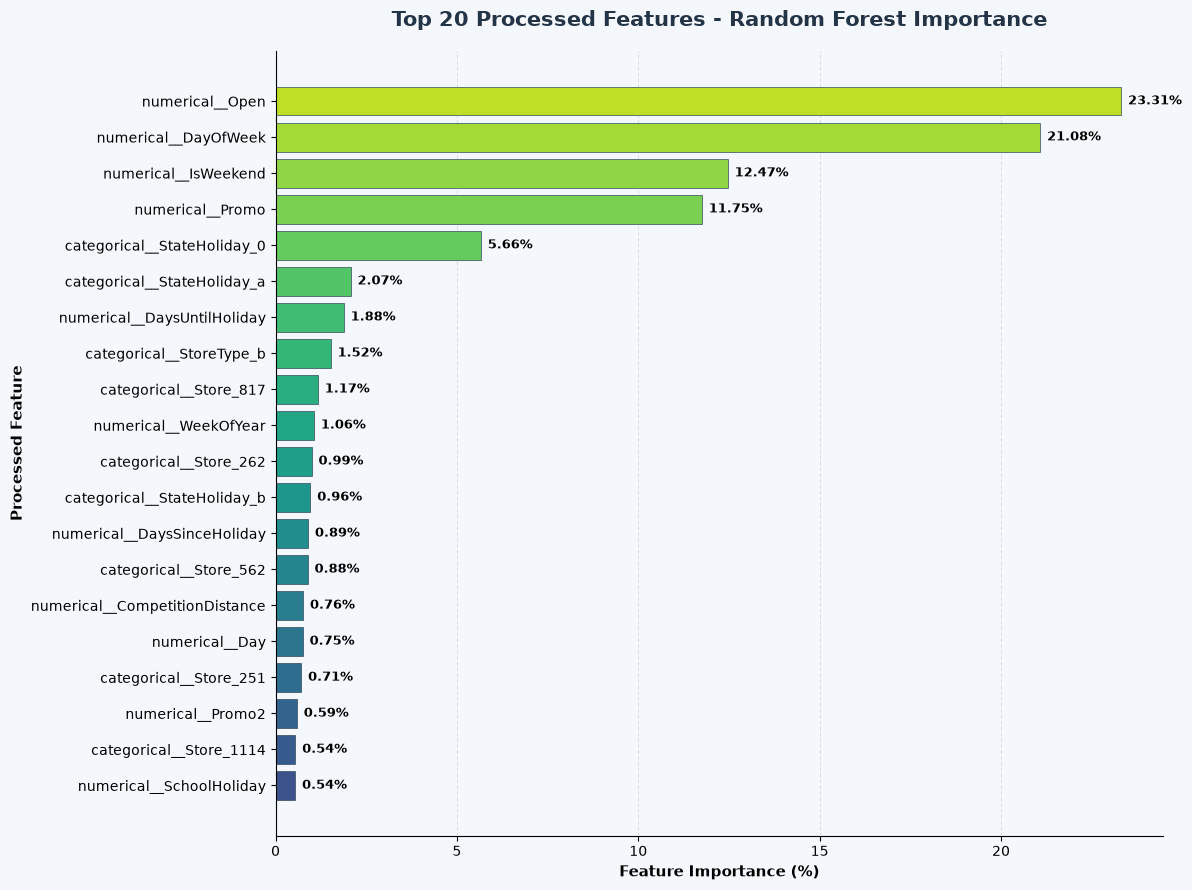

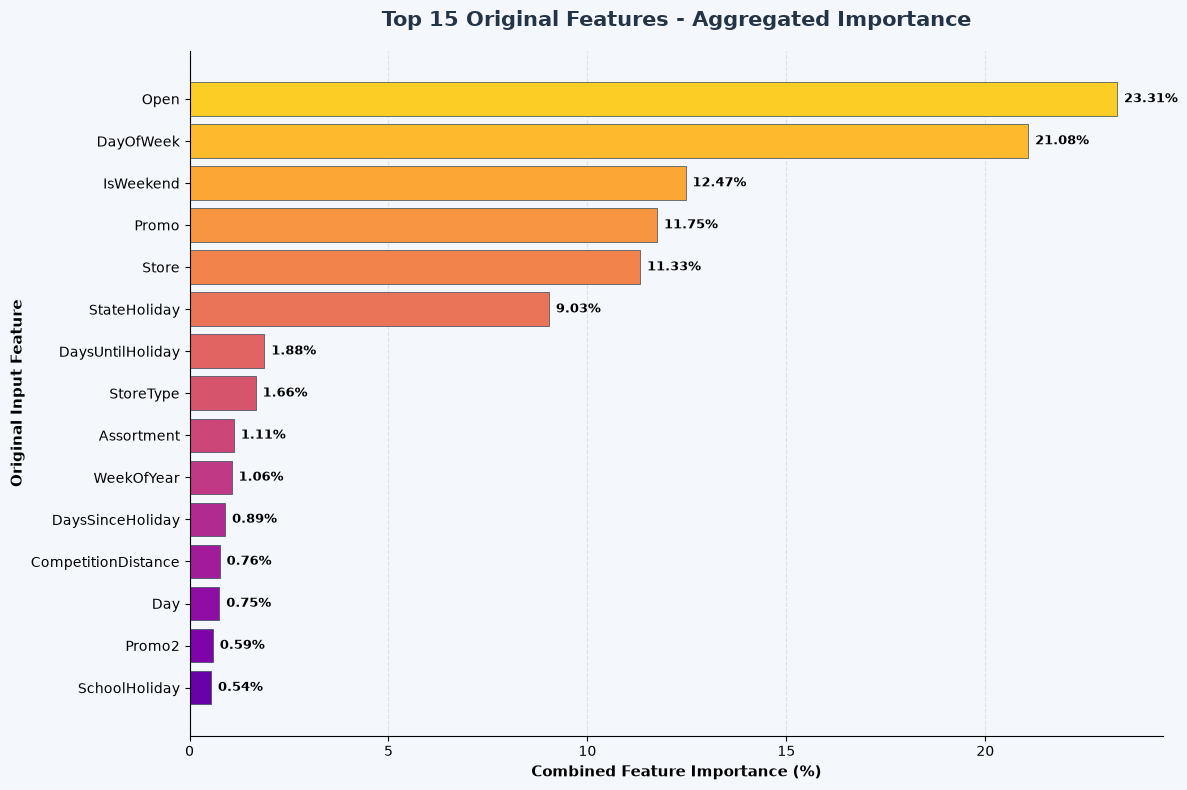

2026-11-05 17:11:53,384 | INFO | Project6_ML_Modeling | Section 8 completed successfully. Processed and original feature importance tables and visualizations were generated.



CUMULATIVE IMPORTANCE SUMMARY
----------------------------------------------------------------------------------------------------
Top 5 original features combined: 79.93%
Top 10 original features combined: 94.68%
Top 15 original features combined: 98.20%
Top 20 original features combined: 99.83%

SECTION 8 FINAL VALIDATION
Processed feature count correct              : True
Processed importance sums to one             : True
Grouped importance sums to one               : True
Feature names are unique                     : True
Importance values finite                     : True
Tree importance dimensions correct           : True
All output files saved                       : True

Saved Files:
section8_processed_feature_importance.csv         : True
section8_grouped_feature_importance.csv           : True
section8_cumulative_importance.csv                : True
section8_feature_importance_summary.json          : True
section8_top20_processed_features.png             : True
section8_t

In [24]:

# ============================================================
# PROJECT 6 - NOTEBOOK 04
# SECTION 8: RANDOM FOREST FEATURE IMPORTANCE ANALYSIS
# ============================================================

import matplotlib.pyplot as plt
import json


# STEP 1: VERIFY PREVIOUS SECTION

if "section_7_successful" not in globals() or not section_7_successful:

    raise RuntimeError(
        "Section 7 has not completed successfully. "
        "Run Section 7 before Section 8."
    )


# STEP 2: VERIFY REQUIRED VARIABLES

required_variables = [

    "best_rf_pipeline",

    "best_rf_model_name",

    "best_rf_parameters",

    "feature_names",

    "preprocessor",

    "EVALUATION_DIR",

    "logger"

]


missing_variables = [

    name

    for name in required_variables

    if name not in globals()

]


if missing_variables:

    raise NameError(
        "Missing variables required for Section 8: "
        f"{missing_variables}"
    )


logger.info(
    "Section 8 started: Random Forest feature importance analysis."
)


# STEP 3: EXTRACT THE TRAINED RANDOM FOREST ESTIMATOR

if not isinstance(best_rf_pipeline, Pipeline):

    raise TypeError(
        "Selected model is not a scikit-learn Pipeline."
    )


if "regressor" not in best_rf_pipeline.named_steps:

    raise KeyError(
        "The selected Pipeline does not contain "
        "a 'regressor' step."
    )


rf_selected_estimator = (
    best_rf_pipeline.named_steps["regressor"]
)


if not isinstance(
    rf_selected_estimator,
    RandomForestRegressor
):

    raise TypeError(
        "The selected estimator is not RandomForestRegressor."
    )


# STEP 4: EXTRACT FEATURE IMPORTANCE

processed_importances = np.asarray(

    rf_selected_estimator.feature_importances_,

    dtype=np.float64

)


expected_feature_count = X_train_pilot.shape[1]


if len(processed_importances) != expected_feature_count:

    raise ValueError(
        "Feature importance count does not match "
        "the trained model input feature count."
    )


if len(feature_names) != expected_feature_count:

    raise ValueError(
        "Processed feature names do not match "
        "the Random Forest input feature count."
    )


if not np.isfinite(processed_importances).all():

    raise ValueError(
        "Feature importance contains NaN or infinite values."
    )


if (processed_importances < 0).any():

    raise ValueError(
        "Negative feature importance values detected."
    )


total_importance = processed_importances.sum()


if not np.isclose(
    total_importance,
    1.0,
    atol=1e-6
):

    raise ValueError(
        "Normalized feature importance values do not sum to 1. "
        f"Observed sum: {total_importance}"
    )


# STEP 5: CALCULATE TREE-LEVEL IMPORTANCE VARIABILITY

# Every tree has its own feature importance vector.
# We calculate the standard deviation across trees.

individual_tree_importances = np.vstack([

    tree.feature_importances_

    for tree in rf_selected_estimator.estimators_

])


if individual_tree_importances.shape[1] != expected_feature_count:

    raise ValueError(
        "Individual tree feature importance dimensions are incorrect."
    )


tree_importance_std = np.std(

    individual_tree_importances,

    axis=0

)


# STEP 6: CREATE PROCESSED FEATURE IMPORTANCE DATAFRAME

feature_importance_df = pd.DataFrame({

    "Feature_Name": feature_names,

    "Importance": processed_importances,

    "Importance_Percent": processed_importances * 100,

    "Importance_SD_Across_Trees": tree_importance_std

})


feature_importance_df = (

    feature_importance_df

    .sort_values(

        "Importance",

        ascending=False

    )

    .reset_index(drop=True)

)


feature_importance_df.insert(

    0,

    "Rank",

    np.arange(
        1,
        len(feature_importance_df) + 1
    )

)


print("=" * 100)

print("TOP 20 PROCESSED FEATURE IMPORTANCE")

print("=" * 100)


display(

    feature_importance_df.head(20).style

    .format({

        "Importance": "{:.6f}",

        "Importance_Percent": "{:.3f}%",

        "Importance_SD_Across_Trees": "{:.6f}"

    })

    .hide(axis="index")

    .background_gradient(

        subset=["Importance_Percent"],

        cmap="YlGnBu"

    )

    .set_caption(
        "Top 20 processed features ranked by Random Forest impurity importance"
    )

)


# STEP 7: IDENTIFY ORIGINAL INPUT FEATURES

# Notebook 03 saved numerical and categorical feature names
# in the modelling metadata.

original_feature_names = []


for metadata_key in [

    "numerical_features",

    "categorical_features"

]:

    metadata_values = modeling_metadata_source.get(

        metadata_key,

        []

    )


    if isinstance(
        metadata_values,
        (list, tuple, np.ndarray, pd.Index)
    ):

        original_feature_names.extend(

            str(value)

            for value in metadata_values

        )


# If metadata does not contain the original feature lists,
# use the fitted ColumnTransformer to recover its input columns.

if not original_feature_names:

    for transformer_name, transformer, columns in getattr(

        preprocessor,

        "transformers_",

        []

    ):

        if isinstance(columns, str):

            original_feature_names.append(columns)

        else:

            try:

                original_feature_names.extend(

                    str(column)

                    for column in list(columns)

                    if isinstance(column, str)

                )

            except TypeError:

                pass


# Remove duplicate original names and sort longest first.
# Longest-first mapping avoids mapping StoreType to Store.

original_feature_names = sorted(

    set(original_feature_names),

    key=len,

    reverse=True

)


# STEP 8: MAP ENCODED FEATURES TO ORIGINAL FEATURES

def map_to_original_feature(processed_feature_name):
    """
    Convert processed feature names to original feature names.

    Examples:
        numerical__DayOfWeek -> DayOfWeek
        categorical__Store_1 -> Store
        categorical__StoreType_b -> StoreType
    """

    base_name = str(
        processed_feature_name
    ).split("__", 1)[-1]


    matching_features = [

        original_name

        for original_name in original_feature_names

        if (

            base_name == original_name

            or base_name.startswith(
                original_name + "_"
            )

        )

    ]


    if matching_features:

        # Longest matching original name is preferred.

        return max(
            matching_features,
            key=len
        )


    # If there is no known match, preserve the processed name
    # without the transformer prefix.

    return base_name


feature_importance_df["Original_Feature"] = (

    feature_importance_df["Feature_Name"]

    .apply(map_to_original_feature)

)


# STEP 9: AGGREGATE ONE-HOT ENCODED FEATURES

# Importance values for the encoded levels of an original
# categorical feature are combined using summation.

grouped_feature_importance_df = (

    feature_importance_df

    .groupby(

        "Original_Feature",

        as_index=False

    )

    .agg(

        Importance=(

            "Importance",

            "sum"

        ),

        Importance_SD_Across_Trees=(

            "Importance_SD_Across_Trees",

            "sum"

        ),

        Processed_Feature_Count=(

            "Feature_Name",

            "count"

        )

    )

)


grouped_feature_importance_df[
    "Importance_Percent"
] = (

    grouped_feature_importance_df["Importance"] * 100

)


grouped_feature_importance_df = (

    grouped_feature_importance_df

    .sort_values(

        "Importance",

        ascending=False

    )

    .reset_index(drop=True)

)


grouped_feature_importance_df.insert(

    0,

    "Rank",

    np.arange(

        1,

        len(grouped_feature_importance_df) + 1

    )

)


# STEP 10: VALIDATE AGGREGATED IMPORTANCE

grouped_importance_sum = (

    grouped_feature_importance_df["Importance"].sum()

)


grouped_importance_check = np.isclose(

    grouped_importance_sum,

    1.0,

    atol=1e-6

)


if not grouped_importance_check:

    raise ValueError(
        "Aggregated original feature importance "
        "does not sum to 1."
    )


print("\n" + "=" * 100)

print("ORIGINAL FEATURE IMPORTANCE - TOP 20")

print("=" * 100)


display(

    grouped_feature_importance_df.head(20).style

    .format({

        "Importance": "{:.6f}",

        "Importance_Percent": "{:.3f}%",

        "Importance_SD_Across_Trees": "{:.6f}",

        "Processed_Feature_Count": "{:,.0f}"

    })

    .hide(axis="index")

    .background_gradient(

        subset=["Importance_Percent"],

        cmap="YlOrBr"

    )

    .set_caption(
        "Aggregated original feature importance – one-hot levels combined"
    )

)


# STEP 11: CREATE COLORFUL TOP 20 PROCESSED FEATURES GRAPH

top_processed_features = (

    feature_importance_df

    .head(20)

    .sort_values(

        "Importance_Percent",

        ascending=True

    )

)


fig, ax = plt.subplots(

    figsize=(12, 9),

    facecolor="#F4F7FB"

)


ax.set_facecolor("#F4F7FB")


colors = plt.cm.viridis(

    np.linspace(

        0.25,

        0.90,

        len(top_processed_features)

    )

)


bars = ax.barh(

    top_processed_features["Feature_Name"],

    top_processed_features["Importance_Percent"],

    color=colors,

    edgecolor="#34495E",

    linewidth=0.5

)


ax.set_title(

    "Top 20 Processed Features - Random Forest Importance",

    fontsize=15,

    fontweight="bold",

    color="#243447",

    pad=18

)


ax.set_xlabel(

    "Feature Importance (%)",

    fontsize=11,

    fontweight="bold"

)


ax.set_ylabel(

    "Processed Feature",

    fontsize=11,

    fontweight="bold"

)


for bar, value in zip(

    bars,

    top_processed_features["Importance_Percent"]

):

    ax.annotate(

        f"{value:.2f}%",

        xy=(

            bar.get_width(),

            bar.get_y() + bar.get_height() / 2

        ),

        xytext=(5, 0),

        textcoords="offset points",

        va="center",

        fontsize=9,

        fontweight="bold"

    )


ax.grid(

    axis="x",

    linestyle="--",

    alpha=0.30

)


ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)

ax.spines["right"].set_visible(False)


fig.tight_layout()


top_processed_chart_path = (

    EVALUATION_DIR

    / "section8_top20_processed_features.png"

)


fig.savefig(

    top_processed_chart_path,

    dpi=180,

    bbox_inches="tight",

    facecolor=fig.get_facecolor()

)


plt.show()

plt.close(fig)


# STEP 12: CREATE COLORFUL ORIGINAL FEATURE IMPORTANCE GRAPH

top_original_features = (

    grouped_feature_importance_df

    .head(15)

    .sort_values(

        "Importance_Percent",

        ascending=True

    )

)


fig, ax = plt.subplots(

    figsize=(12, 8),

    facecolor="#F4F7FB"

)


ax.set_facecolor("#F4F7FB")


colors = plt.cm.plasma(

    np.linspace(

        0.20,

        0.90,

        len(top_original_features)

    )

)


bars = ax.barh(

    top_original_features["Original_Feature"],

    top_original_features["Importance_Percent"],

    color=colors,

    edgecolor="#34495E",

    linewidth=0.5

)


ax.set_title(

    "Top 15 Original Features - Aggregated Importance",

    fontsize=15,

    fontweight="bold",

    color="#243447",

    pad=18

)


ax.set_xlabel(

    "Combined Feature Importance (%)",

    fontsize=11,

    fontweight="bold"

)


ax.set_ylabel(

    "Original Input Feature",

    fontsize=11,

    fontweight="bold"

)


for bar, value in zip(

    bars,

    top_original_features["Importance_Percent"]

):

    ax.annotate(

        f"{value:.2f}%",

        xy=(

            bar.get_width(),

            bar.get_y() + bar.get_height() / 2

        ),

        xytext=(5, 0),

        textcoords="offset points",

        va="center",

        fontsize=9,

        fontweight="bold"

    )


ax.grid(

    axis="x",

    linestyle="--",

    alpha=0.30

)


ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)

ax.spines["right"].set_visible(False)


fig.tight_layout()


top_original_chart_path = (

    EVALUATION_DIR

    / "section8_top15_original_features.png"

)


fig.savefig(

    top_original_chart_path,

    dpi=180,

    bbox_inches="tight",

    facecolor=fig.get_facecolor()

)


plt.show()

plt.close(fig)


# STEP 13: CALCULATE CUMULATIVE IMPORTANCE

# This shows how much total importance is represented
# by the most important original features.

cumulative_importance_df = (

    grouped_feature_importance_df.copy()

)


cumulative_importance_df[
    "Cumulative_Importance_Percent"
] = (

    cumulative_importance_df["Importance_Percent"].cumsum()

)


print("\nCUMULATIVE IMPORTANCE SUMMARY")

print("-" * 100)


for top_n in [5, 10, 15, 20]:

    available_n = min(

        top_n,

        len(cumulative_importance_df)

    )

    cumulative_value = (

        cumulative_importance_df

        .head(available_n)

        ["Importance_Percent"]

        .sum()

    )


    print(

        f"Top {available_n} original features combined: "

        f"{cumulative_value:.2f}%"

    )


# STEP 14: SAVE FEATURE IMPORTANCE TABLES

processed_importance_path = (

    EVALUATION_DIR

    / "section8_processed_feature_importance.csv"

)


grouped_importance_path = (

    EVALUATION_DIR

    / "section8_grouped_feature_importance.csv"

)


cumulative_importance_path = (

    EVALUATION_DIR

    / "section8_cumulative_importance.csv"

)


feature_importance_df.to_csv(

    processed_importance_path,

    index=False

)


grouped_feature_importance_df.to_csv(

    grouped_importance_path,

    index=False

)


cumulative_importance_df.to_csv(

    cumulative_importance_path,

    index=False

)


# STEP 15: CREATE SUMMARY METADATA

feature_importance_summary = {

    "selected_model":

        best_rf_model_name,

    "importance_method":

        "Mean Decrease in Impurity (MDI)",

    "processed_feature_count":

        int(len(feature_importance_df)),

    "original_feature_group_count":

        int(len(grouped_feature_importance_df)),

    "total_processed_importance":

        float(processed_importances.sum()),

    "total_grouped_importance":

        float(grouped_importance_sum),

    "top_5_original_features":

        grouped_feature_importance_df.head(5)[
            "Original_Feature"
        ].tolist(),

    "interpretation_limitations": [

        "Feature importance does not establish causation.",

        "Impurity-based importance may favour high-cardinality features.",

        "Correlated features can share importance.",

        "Tree-to-tree variability is not a confidence interval.",

        "Importance is based on the selected pilot model."

    ]

}


feature_importance_summary_path = (

    EVALUATION_DIR

    / "section8_feature_importance_summary.json"

)


with open(

    feature_importance_summary_path,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        feature_importance_summary,

        file,

        indent=4

    )


# STEP 16: VERIFY SAVED OUTPUT FILES

section8_output_paths = [

    processed_importance_path,

    grouped_importance_path,

    cumulative_importance_path,

    feature_importance_summary_path,

    top_processed_chart_path,

    top_original_chart_path

]


section8_saved_file_checks = {

    path.name: (

        path.is_file()

        and path.stat().st_size > 0

    )

    for path in section8_output_paths

}


# STEP 17: FINAL SECTION VALIDATION

section8_checks = {

    "Processed feature count correct":

        len(feature_importance_df) == expected_feature_count,

    "Processed importance sums to one":

        np.isclose(
            processed_importances.sum(),
            1.0,
            atol=1e-6
        ),

    "Grouped importance sums to one":

        grouped_importance_check,

    "Feature names are unique":

        feature_importance_df["Feature_Name"].is_unique,

    "Importance values finite":

        bool(
            np.isfinite(processed_importances).all()
        ),

    "Tree importance dimensions correct":

        individual_tree_importances.shape[1]
        == expected_feature_count,

    "All output files saved":

        all(section8_saved_file_checks.values())

}


section_8_successful = all(
    section8_checks.values()
)


print("\n" + "=" * 100)

print("SECTION 8 FINAL VALIDATION")

print("=" * 100)


for check_name, check_status in section8_checks.items():

    print(
        f"{check_name:<45}: {check_status}"
    )


print("\nSaved Files:")


for file_name, file_status in section8_saved_file_checks.items():

    print(
        f"{file_name:<50}: {file_status}"
    )


print(
    "\nSECTION 8 COMPLETED SUCCESSFULLY:",
    section_8_successful
)


print("=" * 100)


if not section_8_successful:

    raise RuntimeError(
        "Section 8 feature importance validation failed. "
        "Review the feature names and importance outputs."
    )


logger.info(
    "Section 8 completed successfully. "
    "Processed and original feature importance tables "
    "and visualizations were generated."
)


In [25]:

# ============================================================
# SECTION 8: CORRECT ORIGINAL-FEATURE TREE VARIABILITY
# ============================================================

# Recalculate variation after grouping one-hot encoded
# features within each individual tree.

rf_selected_estimator = (
    best_rf_pipeline.named_steps["regressor"]
)

original_feature_order = (
    grouped_feature_importance_df["Original_Feature"].tolist()
)

n_trees, n_features = individual_tree_importances.shape

tree_grouped_importances = np.zeros(
    (n_trees, len(original_feature_order)),
    dtype=np.float64
)

for tree_index in range(n_trees):

    tree_importance_df = pd.DataFrame({

        "Original_Feature":
            feature_importance_df["Original_Feature"].to_numpy(),

        "Importance":
            individual_tree_importances[tree_index]

    })

    grouped_tree_values = (
        tree_importance_df
        .groupby("Original_Feature")["Importance"]
        .sum()
    )

    tree_grouped_importances[tree_index] = (
        grouped_tree_values
        .reindex(original_feature_order, fill_value=0)
        .to_numpy()
    )


# Calculate standard deviation across trees
# AFTER combining encoded levels within each tree.

grouped_feature_importance_df[
    "Importance_SD_Across_Trees"
] = np.std(
    tree_grouped_importances,
    axis=0,
    ddof=0
)


# Recheck importance sum.

assert np.isclose(
    grouped_feature_importance_df["Importance"].sum(),
    1.0,
    atol=1e-6
)


assert np.isfinite(
    grouped_feature_importance_df[
        "Importance_SD_Across_Trees"
    ]
).all()


# Replace the earlier grouped CSV with the corrected version.

grouped_importance_path = (
    EVALUATION_DIR
    / "section8_grouped_feature_importance.csv"
)

grouped_feature_importance_df.to_csv(
    grouped_importance_path,
    index=False
)


print("Corrected original-feature tree variability:")

display(
    grouped_feature_importance_df.head(15).style
    .format({
        "Importance": "{:.6f}",
        "Importance_Percent": "{:.3f}%",
        "Importance_SD_Across_Trees": "{:.6f}"
    })
    .hide(axis="index")
)

print(
    "\nCorrected grouped importance sum:",
    grouped_feature_importance_df["Importance"].sum()
)

print(
    "\nCorrected grouped CSV saved:",
    grouped_importance_path.is_file()
)


Corrected original-feature tree variability:


Rank,Original_Feature,Importance,Importance_SD_Across_Trees,Processed_Feature_Count,Importance_Percent
1,Open,0.233094,0.255423,1,23.309%
2,DayOfWeek,0.210783,0.263857,1,21.078%
3,IsWeekend,0.124656,0.150811,1,12.466%
4,Promo,0.117511,0.011197,1,11.751%
5,Store,0.113251,0.138952,1115,11.325%
6,StateHoliday,0.090329,0.182101,4,9.033%
7,DaysUntilHoliday,0.018798,0.001509,1,1.880%
8,StoreType,0.016616,0.007351,4,1.662%
9,Assortment,0.011141,0.000004,3,1.114%
10,WeekOfYear,0.010577,0.014785,1,1.058%



Corrected grouped importance sum: 1.0

Corrected grouped CSV saved: True



# SECTION 9: PREDICTION INTERVAL ESTIMATION AND EVALUATION

## Purpose

Estimate prediction intervals for the selected Random Forest model and evaluate how often actual validation Sales values fall within the estimated lower and upper bounds.

## Selected model

Use `best_rf_pipeline`, selected in Section 7 using the lowest validation RMSPE.

## Interval estimation methodology

A Random Forest contains multiple decision trees. Each individual tree generates its own prediction for a given observation.

We will use the distribution of predictions across individual trees to estimate an empirical central 90% prediction interval:

- Lower bound: 5th percentile of individual tree predictions.
- Point prediction: Average prediction of the fitted Random Forest.
- Upper bound: 95th percentile of individual tree predictions.

## Evaluation metrics

1. Empirical coverage percentage.
2. Number of observations covered by the estimated interval.
3. Mean prediction interval width.
4. Median prediction interval width.
5. Coverage for positive-sales and zero-sales observations separately.

The nominal interval level is 90%, but actual validation coverage may be higher or lower.

## Visualizations

- Actual Sales, point predictions and lower/upper prediction bounds for a reproducible sample of validation observations.
- Empirical coverage comparison across all validation observations, positive-sales observations and zero-sales observations, with a 90% reference line.

## Important limitations

- Tree-to-tree prediction spread is an empirical measure of model variation, not a formally calibrated statistical confidence interval.
- Individual Random Forest trees are not statistically independent.
- A finite number of trees produces approximate empirical quantiles.
- The validation data was also used for hyperparameter selection in Section 7. Therefore, coverage measured on this dataset is a diagnostic result and not an independent calibration guarantee.
- The intervals are based on the selected pilot model trained using 60,000 observations, not a final model trained on all available training data.

## Expected outcome

A validation prediction interval summary, lower and upper prediction arrays, coverage statistics, colorful visualizations and saved evaluation files.

The section will finish with `section_9_successful = True` only after interval calculations, coverage checks and saved-output verification pass.


2026-11-05 17:11:53,533 | INFO | Project6_ML_Modeling | Section 9 started: estimating Random Forest prediction intervals.


PREDICTION INTERVAL CONFIGURATION
Selected Model: RF_More_Trees
Number of Trees: 60
Lower Quantile: 0.05
Upper Quantile: 0.95
Nominal Interval Coverage: 90%

VALIDATION PREDICTION INTERVAL SUMMARY


Segment,Observations,Covered_Observations,Coverage_Percent,Nominal_Coverage_Percent,Mean_Interval_Width,Median_Interval_Width
All Validation,"46,830","29,698",63.42%,90.00%,"3,849.84","3,295.35"
Positive Sales,"40,282","23,150",57.47%,90.00%,"3,499.23","3,120.02"
Zero Sales,"6,548","6,548",100.00%,90.00%,"6,006.78","5,721.88"


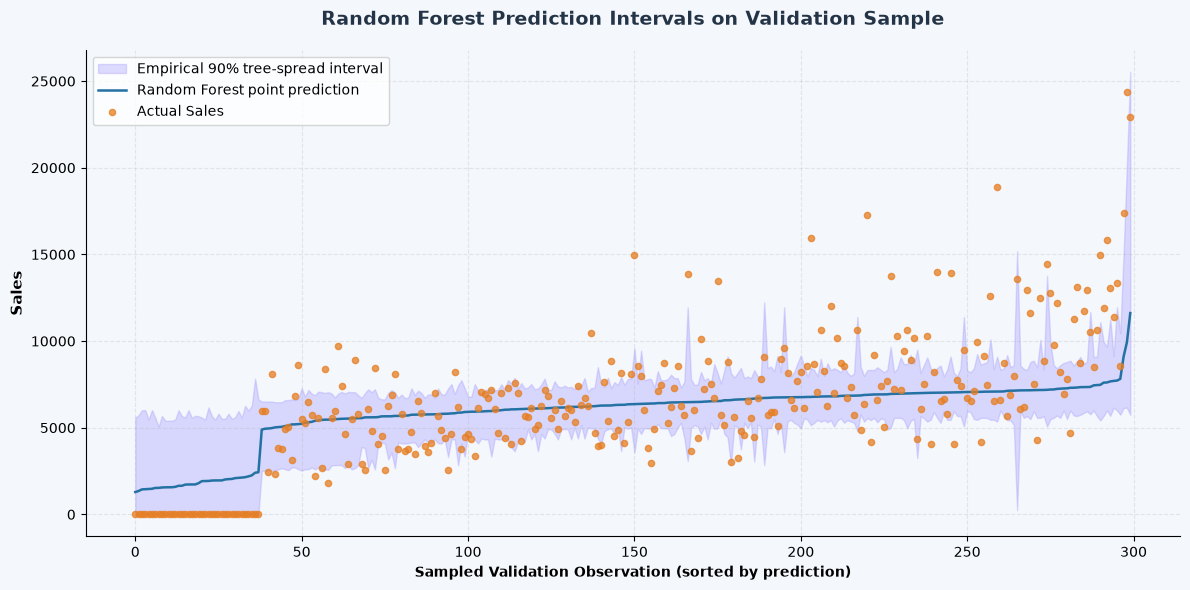

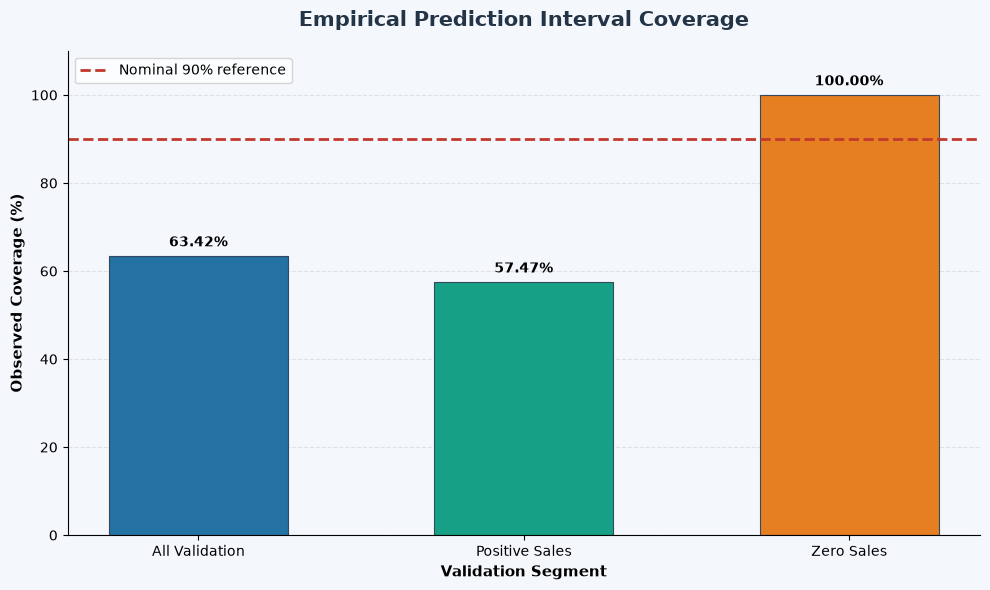

2026-11-05 17:11:55,253 | INFO | Project6_ML_Modeling | Section 9 completed successfully. Empirical prediction intervals, validation coverage and diagnostic visualizations were generated.



SECTION 9 FINAL VALIDATION
Lower and upper bounds finite                     : True
Lower bound never exceeds upper bound             : True
Interval widths non-negative                      : True
Prediction interval row count valid               : True
Coverage values between zero and 100              : True
All output files saved                            : True

Saved Files:
section9_prediction_interval_sample.png                : True
section9_interval_coverage.png                         : True
section9_prediction_interval_metadata.json             : True
section9_validation_prediction_intervals.csv           : True

SECTION 9 COMPLETED SUCCESSFULLY: True


In [26]:

# ============================================================
# PROJECT 6 - NOTEBOOK 04
# SECTION 9: PREDICTION INTERVAL ESTIMATION
# AND VALIDATION EVALUATION
# ============================================================

import matplotlib.pyplot as plt
import json


# STEP 1: VERIFY PREVIOUS SECTION

if "section_8_successful" not in globals() or not section_8_successful:

    raise RuntimeError(
        "Section 8 has not completed successfully. "
        "Run Section 8 before Section 9."
    )


# STEP 2: VERIFY REQUIRED VARIABLES

required_variables = [

    "best_rf_pipeline",

    "best_rf_model_name",

    "best_rf_valid_predictions",

    "X_valid_processed",

    "y_valid",

    "EVALUATION_DIR",

    "logger",

    "RANDOM_STATE"

]


missing_variables = [

    name

    for name in required_variables

    if name not in globals()

]


if missing_variables:

    raise NameError(
        "Missing variables required for Section 9: "
        f"{missing_variables}"
    )


logger.info(
    "Section 9 started: estimating Random Forest prediction intervals."
)


# STEP 3: EXTRACT SELECTED RANDOM FOREST ESTIMATOR

if not isinstance(best_rf_pipeline, Pipeline):

    raise TypeError(
        "Selected model is not a scikit-learn Pipeline."
    )


rf_interval_estimator = (
    best_rf_pipeline.named_steps["regressor"]
)


if not isinstance(
    rf_interval_estimator,
    RandomForestRegressor
):

    raise TypeError(
        "Selected estimator is not a RandomForestRegressor."
    )


if not hasattr(
    rf_interval_estimator,
    "estimators_"
):

    raise ValueError(
        "Random Forest does not contain fitted decision trees."
    )


# STEP 4: VERIFY VALIDATION DATA

if not sp.issparse(X_valid_processed):

    raise TypeError(
        "Validation matrix must remain in sparse format."
    )


if X_valid_processed.shape[0] != len(y_valid):

    raise ValueError(
        "Validation features and targets are not aligned."
    )


if len(best_rf_valid_predictions) != len(y_valid):

    raise ValueError(
        "Selected model validation predictions have "
        "an incorrect number of rows."
    )


if not np.isfinite(y_valid).all():

    raise ValueError(
        "Validation actual Sales contains invalid values."
    )


# STEP 5: DEFINE INTERVAL QUANTILES

LOWER_QUANTILE = 0.05

UPPER_QUANTILE = 0.95

NOMINAL_COVERAGE_PERCENT = 90.0


n_estimators = len(
    rf_interval_estimator.estimators_
)


print("=" * 100)

print("PREDICTION INTERVAL CONFIGURATION")

print("=" * 100)


print(
    "Selected Model:",
    best_rf_model_name
)


print(
    "Number of Trees:",
    n_estimators
)


print(
    "Lower Quantile:",
    LOWER_QUANTILE
)


print(
    "Upper Quantile:",
    UPPER_QUANTILE
)


print(
    "Nominal Interval Coverage:",
    f"{NOMINAL_COVERAGE_PERCENT:.0f}%"
)


# STEP 6: GENERATE INDIVIDUAL TREE PREDICTIONS

# Each tree predicts all validation observations.
# Memory usage is controlled by keeping the prediction matrix
# separate from the much larger training feature matrix.

tree_prediction_list = []


for tree_number, tree in enumerate(

    rf_interval_estimator.estimators_,

    start=1

):

    tree_predictions = np.asarray(

        tree.predict(X_valid_processed),

        dtype=np.float64

    )


    if len(tree_predictions) != len(y_valid):

        raise ValueError(
            f"Tree {tree_number} produced an incorrect "
            "number of validation predictions."
        )


    if not np.isfinite(tree_predictions).all():

        raise ValueError(
            f"Tree {tree_number} generated invalid predictions."
        )


    tree_prediction_list.append(
        tree_predictions
    )


# Shape:
# Rows = trees
# Columns = validation observations

tree_prediction_matrix = np.vstack(
    tree_prediction_list
)


if tree_prediction_matrix.shape != (
    n_estimators,
    len(y_valid)
):

    raise ValueError(
        "Individual tree prediction matrix has "
        "unexpected dimensions."
    )


# STEP 7: CALCULATE LOWER AND UPPER INTERVAL BOUNDS

lower_prediction_bounds = np.quantile(

    tree_prediction_matrix,

    LOWER_QUANTILE,

    axis=0

)


upper_prediction_bounds = np.quantile(

    tree_prediction_matrix,

    UPPER_QUANTILE,

    axis=0

)


# STEP 8: CALCULATE RANDOM FOREST POINT PREDICTIONS

# Use the fitted pipeline's average prediction.

interval_point_predictions = np.asarray(

    best_rf_pipeline.predict(
        X_valid_processed
    ),

    dtype=np.float64

)


# STEP 9: VALIDATE INTERVAL BOUNDS

if not np.isfinite(lower_prediction_bounds).all():

    raise ValueError(
        "Lower prediction bounds contain invalid values."
    )


if not np.isfinite(upper_prediction_bounds).all():

    raise ValueError(
        "Upper prediction bounds contain invalid values."
    )


if not np.isfinite(interval_point_predictions).all():

    raise ValueError(
        "Point predictions contain invalid values."
    )


if not (
    (lower_prediction_bounds <= upper_prediction_bounds).all()
):

    raise ValueError(
        "Some lower prediction bounds exceed upper bounds."
    )


# STEP 10: CALCULATE INTERVAL WIDTH

prediction_interval_width = (

    upper_prediction_bounds

    - lower_prediction_bounds

)


if (prediction_interval_width < 0).any():

    raise ValueError(
        "Negative prediction interval width detected."
    )


# STEP 11: CREATE A REUSABLE COVERAGE SUMMARY FUNCTION

def summarize_prediction_interval(
    actual_values,
    lower_bounds,
    upper_bounds,
    segment_name
):
    """
    Calculate empirical prediction interval coverage
    and interval width for a selected validation segment.
    """

    actual = np.asarray(
        actual_values,
        dtype=np.float64
    )

    lower = np.asarray(
        lower_bounds,
        dtype=np.float64
    )

    upper = np.asarray(
        upper_bounds,
        dtype=np.float64
    )


    if len(actual) == 0:

        raise ValueError(
            f"{segment_name} segment is empty."
        )


    # An observation is covered when actual Sales
    # lies inside the lower and upper bounds.

    covered_mask = (

        (actual >= lower)

        & (actual <= upper)

    )


    covered_count = int(
        covered_mask.sum()
    )


    coverage_percentage = (
        covered_count / len(actual)
    ) * 100


    interval_widths = (
        upper - lower
    )


    return {

        "Segment": segment_name,

        "Observations": len(actual),

        "Covered_Observations": covered_count,

        "Coverage_Percent": coverage_percentage,

        "Nominal_Coverage_Percent":
            NOMINAL_COVERAGE_PERCENT,

        "Mean_Interval_Width":
            float(np.mean(interval_widths)),

        "Median_Interval_Width":
            float(np.median(interval_widths))

    }


# STEP 12: CREATE VALIDATION SUBGROUP MASKS

all_validation_mask = np.ones(
    len(y_valid),
    dtype=bool
)


positive_sales_mask = (
    y_valid > 0
)


zero_sales_mask = (
    y_valid == 0
)


# STEP 13: CALCULATE COVERAGE FOR ALL VALIDATION OBSERVATIONS

all_validation_summary = summarize_prediction_interval(

    actual_values=y_valid[all_validation_mask],

    lower_bounds=lower_prediction_bounds[all_validation_mask],

    upper_bounds=upper_prediction_bounds[all_validation_mask],

    segment_name="All Validation"

)


positive_sales_summary = summarize_prediction_interval(

    actual_values=y_valid[positive_sales_mask],

    lower_bounds=lower_prediction_bounds[positive_sales_mask],

    upper_bounds=upper_prediction_bounds[positive_sales_mask],

    segment_name="Positive Sales"

)


zero_sales_summary = summarize_prediction_interval(

    actual_values=y_valid[zero_sales_mask],

    lower_bounds=lower_prediction_bounds[zero_sales_mask],

    upper_bounds=upper_prediction_bounds[zero_sales_mask],

    segment_name="Zero Sales"

)


# STEP 14: CREATE PROFESSIONAL COVERAGE TABLE

prediction_interval_summary_df = pd.DataFrame(

    [

        all_validation_summary,

        positive_sales_summary,

        zero_sales_summary

    ]

)


print("\n" + "=" * 110)

print("VALIDATION PREDICTION INTERVAL SUMMARY")

print("=" * 110)


display(

    prediction_interval_summary_df.style

    .format({

        "Observations": "{:,.0f}",

        "Covered_Observations": "{:,.0f}",

        "Coverage_Percent": "{:.2f}%",

        "Nominal_Coverage_Percent": "{:.2f}%",

        "Mean_Interval_Width": "{:,.2f}",

        "Median_Interval_Width": "{:,.2f}"

    })

    .hide(axis="index")

    .set_caption(
        "Empirical coverage and interval width on validation data"
    )

)


# STEP 15: CREATE A REPRODUCIBLE VISUAL SAMPLE

# Randomly select observations and sort them by point prediction.
# X-axis shows sample rank, not chronological time.

interval_plot_sample_size = min(

    300,

    len(y_valid)

)


interval_rng = np.random.default_rng(

    RANDOM_STATE + 9

)


interval_plot_indices = np.sort(

    interval_rng.choice(

        len(y_valid),

        size=interval_plot_sample_size,

        replace=False

    )

)


# Sort selected observations by point prediction.

sort_order = np.argsort(

    interval_point_predictions[
        interval_plot_indices
    ]

)


sample_indices = interval_plot_indices[
    sort_order
]


sample_x = np.arange(
    len(sample_indices)
)


sample_actual = y_valid[
    sample_indices
]


sample_point = interval_point_predictions[
    sample_indices
]


sample_lower = lower_prediction_bounds[
    sample_indices
]


sample_upper = upper_prediction_bounds[
    sample_indices
]


# STEP 16: PLOT ACTUAL SALES AND INTERVAL BOUNDS

fig, ax = plt.subplots(

    figsize=(12, 6),

    facecolor="#F4F7FB"

)

ax.set_facecolor("#F4F7FB")


# Prediction interval band.

ax.fill_between(

    sample_x,

    sample_lower,

    sample_upper,

    color="#A29BFE",

    alpha=0.35,

    label="Empirical 90% tree-spread interval"

)


# Random Forest point predictions.

ax.plot(

    sample_x,

    sample_point,

    color="#2471A3",

    linewidth=1.8,

    label="Random Forest point prediction"

)


# Actual observed sales.

ax.scatter(

    sample_x,

    sample_actual,

    color="#E67E22",

    s=20,

    alpha=0.75,

    label="Actual Sales",

    zorder=3

)


ax.set_title(

    "Random Forest Prediction Intervals on Validation Sample",

    fontsize=14,

    fontweight="bold",

    color="#243447",

    pad=18

)


ax.set_xlabel(

    "Sampled Validation Observation (sorted by prediction)",

    fontsize=10,

    fontweight="bold"

)


ax.set_ylabel(

    "Sales",

    fontsize=11,

    fontweight="bold"

)


ax.legend(
    frameon=True
)


ax.grid(

    linestyle="--",

    alpha=0.25

)


ax.spines["top"].set_visible(False)

ax.spines["right"].set_visible(False)


fig.tight_layout()


interval_sample_plot_path = (

    EVALUATION_DIR

    / "section9_prediction_interval_sample.png"

)


fig.savefig(

    interval_sample_plot_path,

    dpi=180,

    bbox_inches="tight",

    facecolor=fig.get_facecolor()

)


plt.show()

plt.close(fig)


# STEP 17: CREATE COVERAGE COMPARISON GRAPH

coverage_labels = (

    prediction_interval_summary_df["Segment"].tolist()

)


coverage_values = (

    prediction_interval_summary_df["Coverage_Percent"].to_numpy()

)


fig, ax = plt.subplots(

    figsize=(10, 6),

    facecolor="#F4F7FB"

)

ax.set_facecolor("#F4F7FB")


coverage_colors = [

    "#2471A3",

    "#16A085",

    "#E67E22"

]


bars = ax.bar(

    coverage_labels,

    coverage_values,

    color=coverage_colors,

    edgecolor="#34495E",

    linewidth=0.8,

    width=0.55

)


# Nominal 90% reference line.

ax.axhline(

    NOMINAL_COVERAGE_PERCENT,

    color="#C0392B",

    linestyle="--",

    linewidth=2,

    label="Nominal 90% reference"

)


for bar, value in zip(

    bars,

    coverage_values

):

    ax.annotate(

        f"{value:.2f}%",

        xy=(

            bar.get_x() + bar.get_width() / 2,

            bar.get_height()

        ),

        xytext=(0, 7),

        textcoords="offset points",

        ha="center",

        fontsize=10,

        fontweight="bold"

    )


ax.set_title(

    "Empirical Prediction Interval Coverage",

    fontsize=15,

    fontweight="bold",

    color="#243447",

    pad=18

)


ax.set_xlabel(

    "Validation Segment",

    fontsize=11,

    fontweight="bold"

)


ax.set_ylabel(

    "Observed Coverage (%)",

    fontsize=11,

    fontweight="bold"

)


ax.set_ylim(

    0,

    max(

        100,

        float(coverage_values.max()) + 10

    )

)


ax.legend()

ax.grid(

    axis="y",

    linestyle="--",

    alpha=0.30

)


ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)

ax.spines["right"].set_visible(False)


fig.tight_layout()


coverage_plot_path = (

    EVALUATION_DIR

    / "section9_interval_coverage.png"

)


fig.savefig(

    coverage_plot_path,

    dpi=180,

    bbox_inches="tight",

    facecolor=fig.get_facecolor()

)


plt.show()

plt.close(fig)


# STEP 18: CREATE SUMMARY METADATA

prediction_interval_metadata = {

    "selected_model":

        best_rf_model_name,

    "number_of_estimators":

        int(n_estimators),

    "lower_quantile":

        LOWER_QUANTILE,

    "upper_quantile":

        UPPER_QUANTILE,

    "nominal_interval_coverage_percent":

        NOMINAL_COVERAGE_PERCENT,

    "interval_method":

        "Empirical quantiles of individual Random Forest tree predictions",

    "point_prediction_method":

        "Mean prediction across Random Forest trees",

    "validation_strategy":

        "Chronological 42-day validation set",

    "coverage_interpretation":

        "Exploratory validation diagnostic; not independently calibrated",

    "statistical_guarantee":

        "No formal confidence or prediction coverage guarantee",

    "validation_metrics":

        prediction_interval_summary_df.to_dict(
            orient="records"
        )

}


interval_metadata_path = (

    EVALUATION_DIR

    / "section9_prediction_interval_metadata.json"

)


with open(

    interval_metadata_path,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        prediction_interval_metadata,

        file,

        indent=4

    )


# STEP 19: SAVE VALIDATION INTERVAL RESULTS

interval_results_df = pd.DataFrame({

    "Validation_Row_Index":
        np.arange(len(y_valid)),

    "Actual_Sales":
        y_valid,

    "Predicted_Sales":
        interval_point_predictions,

    "Lower_Bound_5th_Percentile":
        lower_prediction_bounds,

    "Upper_Bound_95th_Percentile":
        upper_prediction_bounds,

    "Interval_Width":
        prediction_interval_width,

    "Covered_By_Interval":

        (

            (y_valid >= lower_prediction_bounds)

            &

            (y_valid <= upper_prediction_bounds)

        )

})


interval_results_path = (

    EVALUATION_DIR

    / "section9_validation_prediction_intervals.csv"

)


interval_results_df.to_csv(

    interval_results_path,

    index=False

)


# STEP 20: VERIFY SAVED OUTPUT FILES

section9_output_paths = [

    interval_sample_plot_path,

    coverage_plot_path,

    interval_metadata_path,

    interval_results_path

]


section9_saved_file_checks = {

    path.name: (

        path.is_file()

        and path.stat().st_size > 0

    )

    for path in section9_output_paths

}


if not all(section9_saved_file_checks.values()):

    raise IOError(

        "Section 9 output files could not all be verified: "

        f"{section9_saved_file_checks}"

    )


# STEP 21: FINAL SECTION VALIDATION

interval_checks = {

    "Lower and upper bounds finite":

        bool(

            np.isfinite(lower_prediction_bounds).all()

            and np.isfinite(upper_prediction_bounds).all()

        ),

    "Lower bound never exceeds upper bound":

        bool(

            (

                lower_prediction_bounds

                <= upper_prediction_bounds

            ).all()

        ),

    "Interval widths non-negative":

        bool(

            (prediction_interval_width >= 0).all()

        ),

    "Prediction interval row count valid":

        len(interval_results_df) == len(y_valid),

    "Coverage values between zero and 100":

        bool(

            (

                (

                    prediction_interval_summary_df[
                        "Coverage_Percent"
                    ] >= 0

                )

                &

                (

                    prediction_interval_summary_df[
                        "Coverage_Percent"
                    ] <= 100

                )

            ).all()

        ),

    "All output files saved":

        all(section9_saved_file_checks.values())

}


section_9_successful = all(
    interval_checks.values()
)


print("\n" + "=" * 110)

print("SECTION 9 FINAL VALIDATION")

print("=" * 110)


for check_name, check_status in interval_checks.items():

    print(
        f"{check_name:<50}: {check_status}"
    )


print("\nSaved Files:")


for file_name, file_status in section9_saved_file_checks.items():

    print(
        f"{file_name:<55}: {file_status}"
    )


print(
    "\nSECTION 9 COMPLETED SUCCESSFULLY:",
    section_9_successful
)


print("=" * 110)


if not section_9_successful:

    raise RuntimeError(
        "Section 9 prediction interval validation failed."
    )


logger.info(
    "Section 9 completed successfully. "
    "Empirical prediction intervals, validation coverage "
    "and diagnostic visualizations were generated."
)



# SECTION 10: TIMESTAMPED MODEL SERIALIZATION AND VERSION MANAGEMENT

## Purpose

Serialize the selected Random Forest pilot model using a timestamped filename, along with its fitted preprocessing object and supporting metadata.

This supports model reproducibility, version tracking and future prediction-serving workflows.

## Selected model

The selected candidate is `best_rf_pipeline`, chosen in Section 7 using the lowest validation RMSPE.

The selected model was trained on a reproducible 60,000-row sample from the training dataset. It is therefore recorded as a tuned pilot model, not a final full-training production model.

## Key activities

1. Verify the selected model and its validation results.
2. Create a timestamped model version identifier.
3. Package the fitted estimator pipeline, fitted preprocessor and processed feature names.
4. Serialize the model package using joblib.
5. Store model configuration, training size, validation metrics and software-independent metadata.
6. Record feature importance and prediction interval evaluation findings.
7. Reload the saved model package.
8. Compare reloaded predictions with the original selected model predictions.
9. Save a model version registry and serialization report.

## Important methodology

- The fitted preprocessing object from Notebook 03 is preserved; it is not fitted again.
- The estimator pipeline expects the same 1,149-column processed feature representation used during training.
- For new raw input data, the saved preprocessor must transform the data before it is passed to the model pipeline.
- The test dataset is not used for model fitting or model selection.
- Prediction intervals are documented as uncalibrated empirical tree-spread ranges because observed validation coverage was below the nominal 90% level.
- This model predicts Sales only. A separate Customers prediction model is still required before the dashboard can provide both outputs requested by the project brief.

## Expected outcome

A timestamped model package, model metadata JSON, version registry CSV and serialization verification report.

The section will finish with `section_10_successful = True` only after the serialized model reloads correctly and reproduces the original validation predictions.


In [27]:

# ============================================================
# PROJECT 6 - NOTEBOOK 04
# SECTION 10: TIMESTAMPED MODEL SERIALIZATION
# ============================================================

import json
import joblib
from datetime import datetime


# STEP 1: VERIFY PREVIOUS SECTIONS

if "section_9_successful" not in globals() or not section_9_successful:

    raise RuntimeError(
        "Section 9 has not completed successfully. "
        "Run Section 9 before Section 10."
    )


# STEP 2: VERIFY REQUIRED VARIABLES

required_variables = [

    "best_rf_pipeline",

    "best_rf_parameters",

    "best_rf_model_name",

    "best_rf_metrics",

    "best_rf_valid_predictions",

    "preprocessor",

    "feature_names",

    "prediction_interval_summary_df",

    "grouped_feature_importance_df",

    "ML_MODEL_DIR",

    "EVALUATION_DIR",

    "logger"

]


missing_variables = [

    name

    for name in required_variables

    if name not in globals()

]


if missing_variables:

    raise NameError(
        "Missing variables required for Section 10: "
        f"{missing_variables}"
    )


logger.info(
    "Section 10 started: timestamped model serialization."
)


# STEP 3: VERIFY SELECTED PIPELINE AND PREPROCESSOR

if not isinstance(best_rf_pipeline, Pipeline):

    raise TypeError(
        "Selected Random Forest model is not a Pipeline."
    )


if "regressor" not in best_rf_pipeline.named_steps:

    raise KeyError(
        "Selected model does not contain a regressor step."
    )


selected_estimator = (
    best_rf_pipeline.named_steps["regressor"]
)


if not isinstance(selected_estimator, RandomForestRegressor):

    raise TypeError(
        "Selected estimator is not RandomForestRegressor."
    )


if not callable(getattr(preprocessor, "transform", None)):

    raise TypeError(
        "Saved preprocessing object does not support transform()."
    )


if len(feature_names) != X_train_pilot.shape[1]:

    raise ValueError(
        "Feature names do not match the selected model's input features."
    )


# STEP 4: VERIFY MODEL AND VALIDATION METRICS

if len(best_rf_valid_predictions) != len(y_valid):

    raise ValueError(
        "Selected model validation predictions are not aligned."
    )


if not np.isfinite(best_rf_valid_predictions).all():

    raise ValueError(
        "Selected model predictions contain invalid values."
    )


required_metrics = [
    "MAE",
    "RMSE",
    "RMSPE_Percent"
]


for metric_name in required_metrics:

    if metric_name not in best_rf_metrics:

        raise KeyError(
            f"Selected model metric is missing: {metric_name}"
        )


    if not np.isfinite(best_rf_metrics[metric_name]):

        raise ValueError(
            f"Selected model metric is invalid: {metric_name}"
        )


# STEP 5: CREATE A UNIQUE TIMESTAMPED MODEL VERSION

timestamp_token = datetime.now().strftime(
    "%d-%m-%Y-%H-%M-%S-00"
)


model_version = (
    f"RandomForest_{timestamp_token}"
)


ML_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# Avoid overwriting an existing model version.

model_file_path = (
    ML_MODEL_DIR
    / f"{model_version}.pkl"
)


version_counter = 1


while model_file_path.exists():

    model_version = (
        f"RandomForest_{timestamp_token}_v{version_counter}"
    )

    model_file_path = (
        ML_MODEL_DIR
        / f"{model_version}.pkl"
    )

    version_counter += 1


model_metadata_path = (
    ML_MODEL_DIR
    / f"{model_version}_metadata.json"
)


# STEP 6: PREPARE JSON-SAFE EVALUATION RESULTS

# DataFrame.to_json converts NumPy numeric values
# into standard JSON-compatible values.

interval_evaluation_records = json.loads(

    prediction_interval_summary_df.to_json(
        orient="records"
    )

)


top_original_features = json.loads(

    grouped_feature_importance_df.head(10)[

        [

            "Original_Feature",

            "Importance_Percent"

        ]

    ].to_json(
        orient="records"
    )

)


selected_validation_metrics = {

    metric_name: float(
        best_rf_metrics[metric_name]
    )

    for metric_name in required_metrics

}


selected_model_parameters = {

    parameter_name: (

        value.item()

        if isinstance(value, np.generic)

        else value

    )

    for parameter_name, value in best_rf_parameters.items()

}


# STEP 7: CREATE COMPLETE MODEL METADATA

model_metadata = {

    "project_name":

        "Sales Forecasting Across Multiple Retail Stores",


    "notebook":

        "04_machine_learning_modeling_evaluation",


    "model_version":

        model_version,


    "created_at":

        datetime.now().isoformat(timespec="seconds"),


    "model_type":

        "RandomForestRegressor",


    "model_stage":

        "Tuned pilot model - not full-training production model",


    "target_variable":

        "Sales",


    "selected_model_name":

        best_rf_model_name,


    "selection_metric":

        "RMSPE_Percent",


    "selected_hyperparameters":

        selected_model_parameters,


    "training_rows":

        int(X_train_pilot.shape[0]),


    "validation_rows":

        int(X_valid_processed.shape[0]),


    "processed_feature_count":

        int(X_train_pilot.shape[1]),


    "validation_metrics":

        selected_validation_metrics,


    "baseline_comparison":

        {

            "pilot_dummy_MAE":

                float(pilot_baseline_valid_metrics["MAE"]),


            "pilot_dummy_RMSE":

                float(pilot_baseline_valid_metrics["RMSE"]),


            "pilot_dummy_RMSPE_Percent":

                float(pilot_baseline_valid_metrics["RMSPE_Percent"])

        },


    "feature_importance_method":

        "Mean Decrease in Impurity (MDI)",


    "top_10_original_features":

        top_original_features,


    "prediction_interval_method":

        "Empirical quantiles of individual tree predictions",


    "prediction_interval_nominal_coverage":

        90.0,


    "prediction_interval_validation_results":

        interval_evaluation_records,


    "prediction_interval_status":

        "Not calibrated to nominal 90 percent coverage",


    "prediction_interval_warning":

        "Observed overall validation coverage was below the nominal "
        "90 percent level. These empirical tree-spread bounds must not "
        "be represented as guaranteed 90 percent confidence intervals.",


    "preprocessing":

        {

            "preprocessor_source":

                "Notebook 03 fitted preprocessor.joblib",

            "fitted_on":

                "X_train only",

            "preprocessor_included_in_model_bundle":

                True

        },


    "inference_workflow":

        [

            "Receive raw input data with the required original feature columns.",

            "Apply the saved fitted preprocessor using transform().",

            "Pass the processed sparse matrix to model_pipeline.predict()."

        ],


    "test_data_used_for_model_selection":

        False,


    "customer_forecast_status":

        "Not included. A separate Customers prediction model is required "
        "to satisfy the dashboard requirement for both Sales and Customers.",


    "source_metadata_discrepancies":

        modeling_metadata_source.get(
            "source_metadata_discrepancies",
            []
        ),


    "model_file":

        str(model_file_path)

}


# STEP 8: CREATE MODEL BUNDLE

# Store both the estimator pipeline and the fitted preprocessor.
# The estimator pipeline expects the processed feature matrix.

model_bundle = {

    "model_version":

        model_version,


    "model_pipeline":

        best_rf_pipeline,


    "preprocessor":

        preprocessor,


    "feature_names":

        feature_names,


    "metadata":

        model_metadata

}


# STEP 9: SERIALIZE THE MODEL BUNDLE

joblib.dump(

    model_bundle,

    model_file_path,

    compress=3

)


# STEP 10: SAVE MODEL METADATA JSON

with open(

    model_metadata_path,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        model_metadata,

        file,

        indent=4,

        ensure_ascii=False

    )


# STEP 11: RELOAD THE SAVED MODEL BUNDLE

loaded_model_bundle = joblib.load(
    model_file_path
)


# STEP 12: VERIFY RELOADED BUNDLE STRUCTURE

required_bundle_keys = {

    "model_version",

    "model_pipeline",

    "preprocessor",

    "feature_names",

    "metadata"

}


bundle_structure_valid = (

    isinstance(loaded_model_bundle, dict)

    and required_bundle_keys.issubset(
        loaded_model_bundle.keys()
    )

)


if not bundle_structure_valid:

    raise ValueError(
        "Reloaded model bundle has an incorrect structure."
    )


# STEP 13: VERIFY RELOADED MODEL PREDICTIONS

# Use only a small validation slice for reproducibility.
# Do not train or tune the model here.

verification_rows = min(
    256,
    X_valid_processed.shape[0]
)


reloaded_sample_predictions = (

    loaded_model_bundle["model_pipeline"]

    .predict(

        X_valid_processed[:verification_rows]

    )

)


original_sample_predictions = (

    best_rf_valid_predictions[:verification_rows]

)


reloaded_predictions_match = np.allclose(

    reloaded_sample_predictions,

    original_sample_predictions,

    rtol=1e-10,

    atol=1e-8

)


if not reloaded_predictions_match:

    raise ValueError(
        "Predictions from the reloaded model do not match "
        "the original selected model."
    )


# STEP 14: VERIFY PREPROCESSOR AND FEATURE SCHEMA

reloaded_preprocessor = (
    loaded_model_bundle["preprocessor"]
)


reloaded_feature_names = (
    loaded_model_bundle["feature_names"]
)


preprocessor_reloaded_valid = callable(

    getattr(
        reloaded_preprocessor,
        "transform",
        None
    )

)


feature_schema_reloaded_valid = (

    reloaded_feature_names == feature_names

)


# STEP 15: VERIFY METADATA JSON

with open(

    model_metadata_path,

    "r",

    encoding="utf-8"

) as file:

    reloaded_metadata = json.load(file)


metadata_reloaded_valid = (

    reloaded_metadata["model_version"]

    == model_version

    and reloaded_metadata["selected_model_name"]

    == best_rf_model_name

    and reloaded_metadata["target_variable"]

    == "Sales"

)


# STEP 16: CREATE SERIALIZATION REPORT

serialization_checks = {

    "Model file exists":

        model_file_path.is_file(),


    "Model file is non-empty":

        model_file_path.is_file()

        and model_file_path.stat().st_size > 0,


    "Metadata JSON exists":

        model_metadata_path.is_file(),


    "Metadata JSON is non-empty":

        model_metadata_path.is_file()

        and model_metadata_path.stat().st_size > 0,


    "Bundle structure valid":

        bundle_structure_valid,


    "Reloaded predictions match":

        bool(reloaded_predictions_match),


    "Preprocessor reloaded":

        preprocessor_reloaded_valid,


    "Feature schema matches":

        feature_schema_reloaded_valid,


    "Metadata reload valid":

        metadata_reloaded_valid

}


serialization_report_df = pd.DataFrame({

    "Validation_Check":

        list(serialization_checks.keys()),


    "Passed":

        list(serialization_checks.values())

})


print("=" * 100)

print("MODEL SERIALIZATION VERIFICATION REPORT")

print("=" * 100)


display(

    serialization_report_df.style

    .hide(axis="index")

    .apply(

        lambda row: [

            "background-color: #D9EAD3"
            if row["Passed"]
            else "background-color: #F4CCCC"

            for _ in row

        ],

        axis=1

    )

    .set_caption(
        "Timestamped model package verification"
    )

)


# STEP 17: SAVE SERIALIZATION REPORT

serialization_report_path = (

    EVALUATION_DIR

    / f"{model_version}_serialization_report.csv"

)


serialization_report_df.to_csv(

    serialization_report_path,

    index=False

)


# STEP 18: REGISTER THE MODEL VERSION

# Keep a simple CSV registry for model version history.
# MLflow tracking will be handled in a later project stage.

model_registry_path = (

    ML_MODEL_DIR

    / "model_version_registry.csv"

)


registry_record = {

    "Model_Version":

        model_version,


    "Created_At":

        model_metadata["created_at"],


    "Model_Type":

        "RandomForestRegressor",


    "Model_Stage":

        "Tuned Pilot",


    "Training_Rows":

        int(X_train_pilot.shape[0]),


    "Validation_Rows":

        int(X_valid_processed.shape[0]),


    "MAE":

        float(best_rf_metrics["MAE"]),


    "RMSE":

        float(best_rf_metrics["RMSE"]),


    "RMSPE_Percent":

        float(best_rf_metrics["RMSPE_Percent"]),


    "Model_File":

        str(model_file_path),


    "Metadata_File":

        str(model_metadata_path)

}


if model_registry_path.exists():

    model_registry_df = pd.read_csv(
        model_registry_path
    )

else:

    model_registry_df = pd.DataFrame()


new_registry_row = pd.DataFrame([
    registry_record
])


model_registry_df = pd.concat(

    [

        model_registry_df,

        new_registry_row

    ],

    ignore_index=True

)


model_registry_df.to_csv(

    model_registry_path,

    index=False

)


# STEP 19: VERIFY ALL SERIALIZATION OUTPUTS

section10_output_paths = [

    model_file_path,

    model_metadata_path,

    serialization_report_path,

    model_registry_path

]


section10_file_checks = {

    path.name: (

        path.is_file()

        and path.stat().st_size > 0

    )

    for path in section10_output_paths

}


# STEP 20: FINAL SECTION VALIDATION

section_10_successful = (

    all(serialization_checks.values())

    and all(section10_file_checks.values())

    and verification_rows > 0

)


print("\n" + "=" * 100)

print("SECTION 10 FINAL VALIDATION")

print("=" * 100)


for check_name, check_status in serialization_checks.items():

    print(
        f"{check_name:<40}: {check_status}"
    )


print("\nModel Version:")

print(model_version)


print("\nModel File:")

print(model_file_path)


print("\nMetadata File:")

print(model_metadata_path)


print("\nModel Registry:")

print(model_registry_path)


print(
    "\nSECTION 10 COMPLETED SUCCESSFULLY:",
    section_10_successful
)


print("=" * 100)


if not section_10_successful:

    raise RuntimeError(
        "Section 10 model serialization validation failed. "
        "Review the serialization report."
    )


logger.info(
    "Section 10 completed successfully. "
    "Timestamped model bundle, metadata and version registry "
    "were saved and verified."
)


2026-11-05 17:11:55,297 | INFO | Project6_ML_Modeling | Section 10 started: timestamped model serialization.


MODEL SERIALIZATION VERIFICATION REPORT


Validation_Check,Passed
Model file exists,True
Model file is non-empty,True
Metadata JSON exists,True
Metadata JSON is non-empty,True
Bundle structure valid,True
Reloaded predictions match,True
Preprocessor reloaded,True
Feature schema matches,True
Metadata reload valid,True


2026-11-05 17:11:55,427 | INFO | Project6_ML_Modeling | Section 10 completed successfully. Timestamped model bundle, metadata and version registry were saved and verified.



SECTION 10 FINAL VALIDATION
Model file exists                       : True
Model file is non-empty                 : True
Metadata JSON exists                    : True
Metadata JSON is non-empty              : True
Bundle structure valid                  : True
Reloaded predictions match              : True
Preprocessor reloaded                   : True
Feature schema matches                  : True
Metadata reload valid                   : True

Model Version:
RandomForest_05-11-2026-17-11-55-00

Model File:
D:\Project_6_Rossmann_Forecasting\models\machine_learning\RandomForest_05-11-2026-17-11-55-00.pkl

Metadata File:
D:\Project_6_Rossmann_Forecasting\models\machine_learning\RandomForest_05-11-2026-17-11-55-00_metadata.json

Model Registry:
D:\Project_6_Rossmann_Forecasting\models\machine_learning\model_version_registry.csv

SECTION 10 COMPLETED SUCCESSFULLY: True



# SECTION 11: FINAL MODEL DEVELOPMENT SUMMARY AND COMPLETION AUDIT

## Purpose

Consolidate the results of Sections 1–10 into a final, reproducible summary of the machine-learning modelling and evaluation stage.

This section records the selected Random Forest pilot model, compares it with the baseline models, summarizes feature importance and prediction interval results, and verifies the saved model artifacts.

## Key activities

1. Verify successful completion of Sections 1–10.
2. Create a final validation metrics table.
3. Report the selected model and its hyperparameters.
4. Calculate improvements against the pilot-size DummyRegressor baseline.
5. Summarize the top original features by importance.
6. Summarize empirical prediction interval coverage and width.
7. Record model version, serialized model path and metadata path.
8. Record known metadata discrepancies and methodological limitations.
9. Generate a professional validation performance chart.
10. Save the final CSV, JSON and Markdown summary reports.

## Selected model status

The selected model is a tuned Random Forest pilot model trained on a reproducible 60,000-row sample.

It was selected using validation RMSPE, not by using the Kaggle test dataset.

It must not be described as a final production model trained on all 970,379 training rows.

## Key limitations to document

- Validation performance was used for hyperparameter selection; therefore, it is not an independent final generalization estimate.
- The empirical tree-spread prediction interval did not achieve the nominal 90% coverage and requires further calibration.
- The original Notebook 03 metadata file had missing `train_rows` and `preprocessing_fitted_on` fields. These discrepancies were preserved and documented.
- This model predicts Sales only. A separate Customers prediction model is required for the complete dashboard requirement.
- LSTM, MLflow and the web dashboard remain separate project stages.

## Expected outcome

A consolidated final metrics table, model-development summary, validation performance chart and Markdown report.

The section will finish with `section_11_successful = True` only after all previous sections, required artifacts, summary calculations and report files pass their final checks.


2026-11-05 17:11:55,549 | INFO | Project6_ML_Modeling | Section 11 started: final model development summary and audit.


FINAL VALIDATION PERFORMANCE COMPARISON


Model,Model_Status,Training_Rows,Validation_Rows,MAE,RMSE,RMSPE_Percent
Dummy - Full Training,Baseline,"970,379","46,830","2,757.65","3,733.83",45.78%
Dummy - Pilot Sample,Matched baseline,"60,000","46,830","2,758.12","3,734.57",45.69%
RF_More_Trees,Selected tuned pilot,"60,000","46,830","1,898.08","2,570.83",42.39%



IMPROVEMENT AGAINST MATCHED PILOT DUMMY


Metric,Pilot_Dummy,Selected_RF,Relative_Error_Reduction_Percent
MAE,"2,758.12","1,898.08",31.18%
RMSE,"3,734.57","2,570.83",31.16%
RMSPE_Percent,45.69,42.39,7.23%



TOP 10 ORIGINAL FEATURES


Rank,Original_Feature,Importance_Percent
1,Open,23.309%
2,DayOfWeek,21.078%
3,IsWeekend,12.466%
4,Promo,11.751%
5,Store,11.325%
6,StateHoliday,9.033%
7,DaysUntilHoliday,1.880%
8,StoreType,1.662%
9,Assortment,1.114%
10,WeekOfYear,1.058%



PREDICTION INTERVAL SUMMARY


Segment,Observations,Covered_Observations,Coverage_Percent,Nominal_Coverage_Percent,Mean_Interval_Width,Median_Interval_Width
All Validation,"46,830","29,698",63.42%,90.00%,"3,849.84","3,295.35"
Positive Sales,"40,282","23,150",57.47%,90.00%,"3,499.23","3,120.02"
Zero Sales,"6,548","6,548",100.00%,90.00%,"6,006.78","5,721.88"



SOURCE METADATA AUDIT
Original metadata audit passed: True
Recorded discrepancies: []


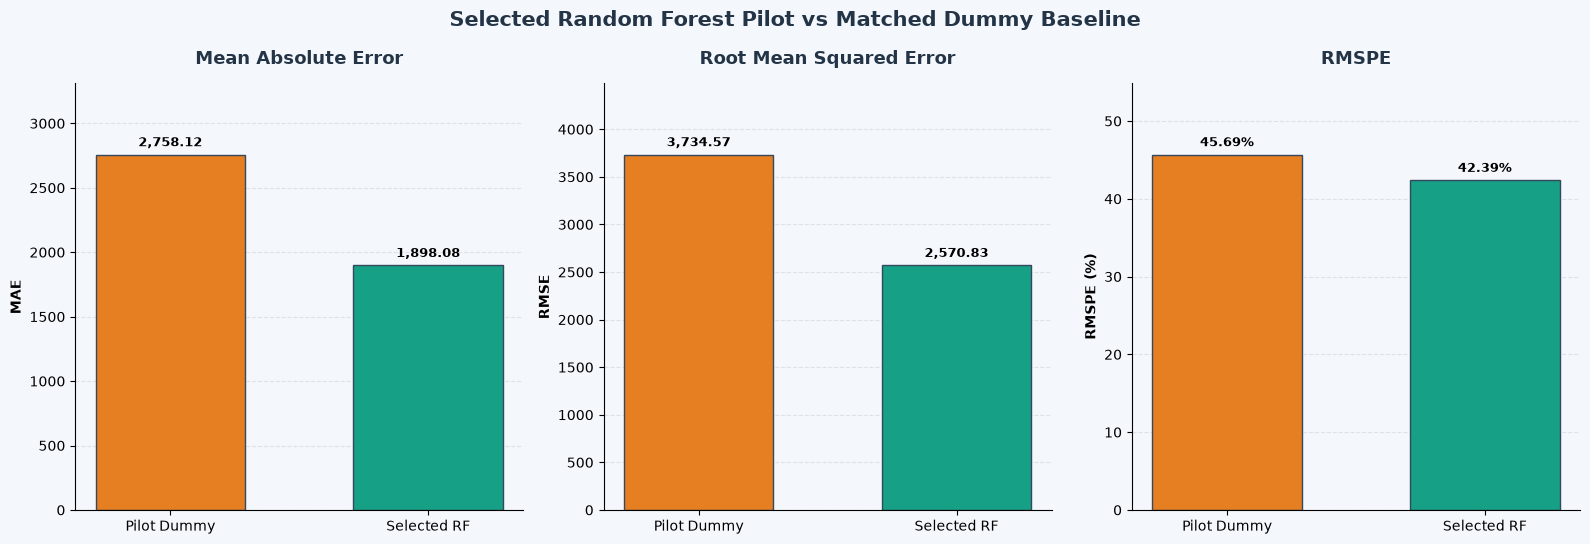


NOTEBOOK 04 - SECTION 11 FINAL COMPLETION AUDIT


Check,Passed
Sections 1-10 completed,True
Selected estimator is RandomForestRegressor,True
Selected validation predictions valid,True
Final metrics table has three models,True
Top feature summary available,True
Prediction interval summary has three segments,True
Serialized model bundle reload valid,True
Serialized predictions match,True
Saved model metadata valid,True
Model registry contains current version,True


2026-11-05 17:11:56,178 | INFO | Project6_ML_Modeling | Section 11 completed successfully. Final model summary, metrics, feature importance, prediction interval assessment, serialization verification and final reports were saved.



Original Notebook 03 metadata audit passed: True
Original metadata discrepancies: []
Metadata discrepancies are documented. The source JSON was not silently modified.

Selected model version:
RandomForest_05-11-2026-17-11-55-00

Selected model file:
D:\Project_6_Rossmann_Forecasting\models\machine_learning\RandomForest_05-11-2026-17-11-55-00.pkl

Final report:
D:\Project_6_Rossmann_Forecasting\reports\model_evaluation\section11_final_model_development_report.md

Final metrics CSV:
D:\Project_6_Rossmann_Forecasting\reports\model_evaluation\section11_final_validation_metrics.csv

Final chart:
D:\Project_6_Rossmann_Forecasting\reports\model_evaluation\section11_final_model_performance.png

Final audit CSV:
D:\Project_6_Rossmann_Forecasting\reports\model_evaluation\section11_final_audit.csv

SECTION 11 COMPLETED SUCCESSFULLY: True


In [28]:

# ============================================================
# PROJECT 6 - NOTEBOOK 04
# SECTION 11: FINAL MODEL DEVELOPMENT SUMMARY AND AUDIT
# ============================================================

import json
from pathlib import Path
from datetime import datetime
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor


# STEP 1: VERIFY THAT SECTIONS 1-10 COMPLETED SUCCESSFULLY

required_section_flags = [
    "section_1_successful", "section_2_successful",
    "section_3_successful", "section_4_successful",
    "section_5_successful", "section_6_successful",
    "section_7_successful", "section_8_successful",
    "section_9_successful", "section_10_successful"
]

missing_section_flags = [
    name for name in required_section_flags if name not in globals()
]

if missing_section_flags:
    raise NameError(
        f"Missing previous section flags: {missing_section_flags}. "
        "Run the missing sections before Section 11."
    )

section_completion_status = {
    name: bool(globals()[name]) for name in required_section_flags
}

failed_sections = [
    name for name, status in section_completion_status.items() if not status
]

if failed_sections:
    raise RuntimeError(
        f"Previous sections have not passed: {failed_sections}"
    )


# STEP 2: VERIFY VARIABLES CREATED IN SECTIONS 1-10

required_variables = [
    "best_rf_pipeline", "best_rf_model_name", "best_rf_parameters",
    "best_rf_metrics", "best_rf_valid_predictions",
    "baseline_valid_metrics", "pilot_baseline_valid_metrics",
    "grouped_feature_importance_df", "prediction_interval_summary_df",
    "y_valid", "y_train", "y_train_pilot", "X_valid_processed",
    "model_version", "model_file_path", "model_metadata_path",
    "model_registry_path", "serialization_report_path",
    "metadata_discrepancies", "metadata_audit_passed",
    "EVALUATION_DIR", "logger"
]

missing_variables = [
    name for name in required_variables if name not in globals()
]

if missing_variables:
    raise NameError(
        f"Missing variables required for Section 11: {missing_variables}"
    )

logger.info("Section 11 started: final model development summary and audit.")


# STEP 3: VALIDATE SELECTED MODEL AND VALIDATION PREDICTIONS

if not isinstance(best_rf_pipeline, Pipeline):
    raise TypeError("best_rf_pipeline must be a scikit-learn Pipeline.")

if "regressor" not in best_rf_pipeline.named_steps:
    raise KeyError("Selected Pipeline does not contain a 'regressor' step.")

selected_estimator = best_rf_pipeline.named_steps["regressor"]

if not isinstance(selected_estimator, RandomForestRegressor):
    raise TypeError("Selected estimator is not RandomForestRegressor.")

best_rf_valid_predictions = np.asarray(
    best_rf_valid_predictions,
    dtype=float
)

if len(best_rf_valid_predictions) != len(y_valid):
    raise ValueError("Selected model predictions do not align with y_valid.")

if not np.isfinite(best_rf_valid_predictions).all():
    raise ValueError("Selected model predictions contain NaN or infinity.")


# STEP 4: VALIDATE METRICS AND CREATE FINAL COMPARISON TABLE

metric_names = ["MAE", "RMSE", "RMSPE_Percent"]

metric_sources = {
    "Dummy - Full Training": baseline_valid_metrics,
    "Dummy - Pilot Sample": pilot_baseline_valid_metrics,
    "Selected Random Forest": best_rf_metrics
}

for model_name, metric_dict in metric_sources.items():
    for metric_name in metric_names:
        if metric_name not in metric_dict:
            raise KeyError(f"{model_name} is missing {metric_name}.")
        if not np.isfinite(float(metric_dict[metric_name])):
            raise ValueError(f"{model_name} has invalid {metric_name}.")


final_model_metrics_df = pd.DataFrame([
    {
        "Model": "Dummy - Full Training",
        "Model_Status": "Baseline",
        "Training_Rows": len(y_train),
        "Validation_Rows": len(y_valid),
        **{m: float(baseline_valid_metrics[m]) for m in metric_names}
    },
    {
        "Model": "Dummy - Pilot Sample",
        "Model_Status": "Matched baseline",
        "Training_Rows": len(y_train_pilot),
        "Validation_Rows": len(y_valid),
        **{m: float(pilot_baseline_valid_metrics[m]) for m in metric_names}
    },
    {
        "Model": best_rf_model_name,
        "Model_Status": "Selected tuned pilot",
        "Training_Rows": len(y_train_pilot),
        "Validation_Rows": len(y_valid),
        **{m: float(best_rf_metrics[m]) for m in metric_names}
    }
])


print("=" * 100)
print("FINAL VALIDATION PERFORMANCE COMPARISON")
print("=" * 100)

display(
    final_model_metrics_df.style
    .format({
        "Training_Rows": "{:,.0f}",
        "Validation_Rows": "{:,.0f}",
        "MAE": "{:,.2f}",
        "RMSE": "{:,.2f}",
        "RMSPE_Percent": "{:.2f}%"
    })
    .hide(axis="index")
    .highlight_min(
        subset=metric_names,
        color="#D9EAD3"
    )
    .set_caption("Validation performance: lower error is better")
)


# STEP 5: CALCULATE IMPROVEMENT AGAINST THE MATCHED PILOT DUMMY

relative_improvement = {}

for metric_name in metric_names:

    reference = float(
        pilot_baseline_valid_metrics[metric_name]
    )

    selected = float(
        best_rf_metrics[metric_name]
    )

    relative_improvement[metric_name] = (
        ((reference - selected) / reference) * 100
        if reference != 0 else None
    )


rmspe_percentage_point_reduction = (
    float(pilot_baseline_valid_metrics["RMSPE_Percent"])
    - float(best_rf_metrics["RMSPE_Percent"])
)


improvement_df = pd.DataFrame([
    {
        "Metric": metric,
        "Pilot_Dummy": float(pilot_baseline_valid_metrics[metric]),
        "Selected_RF": float(best_rf_metrics[metric]),
        "Relative_Error_Reduction_Percent": relative_improvement[metric]
    }
    for metric in metric_names
])


print("\nIMPROVEMENT AGAINST MATCHED PILOT DUMMY")

display(
    improvement_df.style
    .format({
        "Pilot_Dummy": "{:,.2f}",
        "Selected_RF": "{:,.2f}",
        "Relative_Error_Reduction_Percent": "{:.2f}%"
    })
    .hide(axis="index")
    .set_caption("Positive reduction means lower prediction error")
)


# STEP 6: VALIDATE AND DISPLAY TOP ORIGINAL FEATURES

feature_columns = [
    "Rank",
    "Original_Feature",
    "Importance_Percent"
]

missing_feature_columns = [
    c for c in feature_columns
    if c not in grouped_feature_importance_df.columns
]

if missing_feature_columns:
    raise KeyError(
        f"Feature importance table is missing: {missing_feature_columns}"
    )

if grouped_feature_importance_df.empty:
    raise ValueError("Grouped feature importance table is empty.")

if not np.isfinite(
    grouped_feature_importance_df[
        "Importance_Percent"
    ].to_numpy(dtype=float)
).all():
    raise ValueError("Feature importance contains invalid values.")


top_original_features_df = (
    grouped_feature_importance_df
    .head(10)[feature_columns]
    .copy()
)


print("\nTOP 10 ORIGINAL FEATURES")

display(
    top_original_features_df.style
    .format({
        "Rank": "{:.0f}",
        "Importance_Percent": "{:.3f}%"
    })
    .hide(axis="index")
    .background_gradient(
        subset=["Importance_Percent"],
        cmap="YlGnBu"
    )
    .set_caption("Top original features by aggregated Random Forest importance")
)


# STEP 7: VALIDATE PREDICTION INTERVAL SUMMARY

interval_columns = [
    "Segment",
    "Observations",
    "Covered_Observations",
    "Coverage_Percent",
    "Nominal_Coverage_Percent",
    "Mean_Interval_Width",
    "Median_Interval_Width"
]

missing_interval_columns = [
    c for c in interval_columns
    if c not in prediction_interval_summary_df.columns
]

if missing_interval_columns:
    raise KeyError(
        f"Prediction interval summary is missing: {missing_interval_columns}"
    )


all_validation_rows = prediction_interval_summary_df.loc[
    prediction_interval_summary_df["Segment"] == "All Validation"
]

if len(all_validation_rows) != 1:
    raise ValueError(
        "Expected exactly one 'All Validation' interval summary row."
    )


overall_interval_row = all_validation_rows.iloc[0]

actual_interval_coverage = float(
    overall_interval_row["Coverage_Percent"]
)

nominal_interval_coverage = float(
    overall_interval_row["Nominal_Coverage_Percent"]
)

coverage_gap_percentage_points = (
    nominal_interval_coverage - actual_interval_coverage
)


print("\nPREDICTION INTERVAL SUMMARY")

display(
    prediction_interval_summary_df.style
    .format({
        "Observations": "{:,.0f}",
        "Covered_Observations": "{:,.0f}",
        "Coverage_Percent": "{:.2f}%",
        "Nominal_Coverage_Percent": "{:.2f}%",
        "Mean_Interval_Width": "{:,.2f}",
        "Median_Interval_Width": "{:,.2f}"
    })
    .hide(axis="index")
    .set_caption("Empirical tree-spread prediction interval diagnostic")
)


# STEP 8: RECORD THE ORIGINAL NOTEBOOK 03 METADATA AUDIT

metadata_discrepancies_list = list(metadata_discrepancies)

metadata_audit_status = bool(metadata_audit_passed)

print("\nSOURCE METADATA AUDIT")

print("Original metadata audit passed:", metadata_audit_status)

print("Recorded discrepancies:", metadata_discrepancies_list)


# STEP 9: VERIFY SERIALIZED MODEL, METADATA AND MODEL REGISTRY

model_file_path = Path(model_file_path)
model_metadata_path = Path(model_metadata_path)
model_registry_path = Path(model_registry_path)
serialization_report_path = Path(serialization_report_path)


serialization_file_checks = {
    "Model bundle": model_file_path,
    "Model metadata": model_metadata_path,
    "Model registry": model_registry_path,
    "Serialization report": serialization_report_path
}


missing_serialization_files = [
    name
    for name, path in serialization_file_checks.items()
    if not path.is_file() or path.stat().st_size == 0
]

if missing_serialization_files:
    raise FileNotFoundError(
        "Section 10 output files are missing or empty: "
        f"{missing_serialization_files}"
    )


# Reload the saved model bundle from disk.

reloaded_model_bundle = joblib.load(model_file_path)

expected_bundle_keys = {
    "model_version",
    "model_pipeline",
    "preprocessor",
    "feature_names",
    "metadata"
}

bundle_structure_valid = (
    isinstance(reloaded_model_bundle, dict)
    and expected_bundle_keys.issubset(reloaded_model_bundle.keys())
)

if not bundle_structure_valid:
    raise ValueError(
        "Serialized model bundle has an unexpected structure."
    )


if reloaded_model_bundle["model_version"] != model_version:
    raise ValueError(
        "Serialized model version does not match the active version."
    )


# Recheck predictions from a small validation sample.

verification_rows = min(256, len(y_valid))

reloaded_predictions = (
    reloaded_model_bundle["model_pipeline"].predict(
        X_valid_processed[:verification_rows]
    )
)


serialized_predictions_match = bool(
    np.allclose(
        reloaded_predictions,
        best_rf_valid_predictions[:verification_rows],
        rtol=1e-10,
        atol=1e-8
    )
)


if not serialized_predictions_match:
    raise ValueError(
        "Reloaded model predictions do not match "
        "the selected in-memory model."
    )


# Verify saved metadata JSON.

with open(
    model_metadata_path,
    "r",
    encoding="utf-8"
) as file:

    reloaded_model_metadata = json.load(file)


model_metadata_valid = (
    reloaded_model_metadata.get("model_version") == model_version
    and reloaded_model_metadata.get("selected_model_name") == best_rf_model_name
    and reloaded_model_metadata.get("target_variable") == "Sales"
)


if not model_metadata_valid:
    raise ValueError(
        "Saved model metadata does not match the selected model."
    )


# Verify model version registry.

model_registry_df = pd.read_csv(model_registry_path)

registry_valid = (
    "Model_Version" in model_registry_df.columns
    and model_version in model_registry_df[
        "Model_Version"
    ].astype(str).values
)


if not registry_valid:
    raise ValueError(
        "Current model version was not found in the model registry."
    )


# STEP 10: PREPARE KNOWN LIMITATIONS AND FINAL SUMMARY

known_limitations = [

    "The selected Random Forest is a tuned pilot trained on "
    "60,000 rows, not the complete 970,379-row training dataset.",

    "The chronological validation set was used for hyperparameter "
    "selection; validation metrics are not an independent final "
    "generalization estimate.",

    (
        f"The empirical tree-spread interval achieved "
        f"{actual_interval_coverage:.2f}% overall validation coverage "
        f"against a nominal {nominal_interval_coverage:.2f}% level; "
        "it is not calibrated to the nominal coverage."
    ),

    "Tree-to-tree prediction spread is not a guaranteed statistical "
    "confidence interval or prediction coverage guarantee.",

    "The original Notebook 03 metadata JSON has recorded discrepancies: "
    "missing train_rows and preprocessing_fitted_on fields. "
    "The source metadata was preserved.",

    "This model predicts Sales only. A separate Customers prediction "
    "model is still required for the dashboard requirement.",

    "LSTM, MLflow serving and the web dashboard remain separate "
    "project stages."

]


final_summary_payload = {

    "project":
        "Sales Forecasting Across Multiple Retail Stores",

    "notebook":
        "04_machine_learning_modeling_evaluation",

    "generated_at":
        datetime.now().isoformat(timespec="seconds"),

    "completed_sections":
        section_completion_status,

    "selected_model":
        best_rf_model_name,

    "model_stage":
        "Tuned pilot model - not full-training production model",

    "model_version":
        model_version,

    "model_file":
        str(model_file_path),

    "model_metadata_file":
        str(model_metadata_path),

    "model_registry_file":
        str(model_registry_path),

    "training_rows_used":
        int(len(y_train_pilot)),

    "available_full_training_rows":
        int(len(y_train)),

    "validation_rows":
        int(len(y_valid)),

    "processed_feature_count":
        int(X_train_pilot.shape[1]),

    "selected_hyperparameters":
        best_rf_parameters,

    "selected_validation_metrics":
        {
            m: float(best_rf_metrics[m])
            for m in metric_names
        },

    "pilot_dummy_validation_metrics":
        {
            m: float(pilot_baseline_valid_metrics[m])
            for m in metric_names
        },

    "relative_error_reduction_vs_pilot_dummy_percent":
        relative_improvement,

    "rmspe_percentage_point_reduction":
        float(rmspe_percentage_point_reduction),

    "top_10_original_features":
        json.loads(
            top_original_features_df.to_json(orient="records")
        ),

    "prediction_interval_summary":
        json.loads(
            prediction_interval_summary_df.to_json(orient="records")
        ),

    "overall_interval_coverage_percent":
        actual_interval_coverage,

    "nominal_interval_coverage_percent":
        nominal_interval_coverage,

    "interval_coverage_gap_percentage_points":
        float(coverage_gap_percentage_points),

    "source_metadata_audit_passed":
        metadata_audit_status,

    "source_metadata_discrepancies":
        metadata_discrepancies_list,

    "serialized_model_reload_predictions_match":
        serialized_predictions_match,

    "known_limitations":
        known_limitations,

    "next_project_stages": [

        "LSTM time-series modelling (Task 2.6)",

        "MLflow tracking and serving (Task 2.7)",

        "Separate Customers prediction model for dashboard requirements",

        "Sales and Customers prediction dashboard, CSV export and deployment (Task 3)"

    ]

}


# STEP 11: CREATE A PROFESSIONAL PERFORMANCE CHART

chart_specs = [

    ("MAE", "MAE", "Mean Absolute Error"),

    ("RMSE", "RMSE", "Root Mean Squared Error"),

    ("RMSPE_Percent", "RMSPE (%)", "RMSPE")

]


fig, axes = plt.subplots(
    1,
    3,
    figsize=(16, 5.5),
    facecolor="#F4F7FB"
)


for ax, (metric_name, y_label, title) in zip(
    axes,
    chart_specs
):

    ax.set_facecolor("#F4F7FB")

    values = [

        float(pilot_baseline_valid_metrics[metric_name]),

        float(best_rf_metrics[metric_name])

    ]

    bars = ax.bar(

        ["Pilot Dummy", "Selected RF"],

        values,

        color=["#E67E22", "#16A085"],

        edgecolor="#34495E",

        width=0.58

    )


    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        color="#243447",
        pad=14
    )


    ax.set_ylabel(
        y_label,
        fontsize=10,
        fontweight="bold"
    )


    for bar, value in zip(bars, values):

        suffix = (
            "%"
            if metric_name == "RMSPE_Percent"
            else ""
        )

        ax.annotate(

            f"{value:,.2f}{suffix}",

            xy=(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height()
            ),

            xytext=(0, 6),

            textcoords="offset points",

            ha="center",

            fontsize=9,

            fontweight="bold"

        )


    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.30
    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)

    ax.spines["right"].set_visible(False)

    ax.margins(y=0.20)


fig.suptitle(
    "Selected Random Forest Pilot vs Matched Dummy Baseline",
    fontsize=15,
    fontweight="bold",
    color="#243447"
)

fig.tight_layout()


final_performance_chart_path = (
    EVALUATION_DIR / "section11_final_model_performance.png"
)


fig.savefig(
    final_performance_chart_path,
    dpi=180,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

plt.close(fig)


# STEP 12: SAVE FINAL TABLES, JSON SUMMARY AND MARKDOWN REPORT

final_metrics_csv_path = (
    EVALUATION_DIR / "section11_final_validation_metrics.csv"
)

final_improvement_csv_path = (
    EVALUATION_DIR / "section11_final_relative_improvement.csv"
)

final_features_csv_path = (
    EVALUATION_DIR / "section11_top_original_features.csv"
)

final_interval_csv_path = (
    EVALUATION_DIR / "section11_prediction_interval_summary.csv"
)

final_summary_json_path = (
    EVALUATION_DIR / "section11_final_model_development_summary.json"
)

final_markdown_report_path = (
    EVALUATION_DIR / "section11_final_model_development_report.md"
)

final_audit_csv_path = (
    EVALUATION_DIR / "section11_final_audit.csv"
)


# Save all summary tables.

final_model_metrics_df.to_csv(
    final_metrics_csv_path,
    index=False
)

improvement_df.to_csv(
    final_improvement_csv_path,
    index=False
)

top_original_features_df.to_csv(
    final_features_csv_path,
    index=False
)

prediction_interval_summary_df.to_csv(
    final_interval_csv_path,
    index=False
)


# Save JSON summary.

with open(
    final_summary_json_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        final_summary_payload,
        file,
        indent=4,
        ensure_ascii=False,
        default=str
    )


# Create Markdown tables without requiring the optional tabulate package.

def dataframe_to_markdown(dataframe):

    headers = [
        str(column)
        for column in dataframe.columns
    ]

    rows = dataframe.astype(str).values.tolist()

    lines = [
        "| " + " | ".join(headers) + " |"
    ]

    lines.append(
        "| " + " | ".join(
            ["---"] * len(headers)
        ) + " |"
    )

    for row in rows:

        lines.append(
            "| " + " | ".join(row) + " |"
        )

    return "\n".join(lines)


# Prepare final written report.

report_text = f"""
# Project 6: Sales Forecasting Across Multiple Retail Stores

## Notebook 04: Machine Learning Modeling and Evaluation

### 1. Selected model

- Selected model: {best_rf_model_name}
- Model version: {model_version}
- Model stage: Tuned pilot, not full-training production model
- Training rows used: {len(y_train_pilot):,}
- Available full training rows: {len(y_train):,}
- Validation rows: {len(y_valid):,}
- Processed features: {X_train_pilot.shape[1]:,}

### 2. Selected hyperparameters

```json
{json.dumps(best_rf_parameters, indent=4, default=str)}
```

### 3. Validation performance

{dataframe_to_markdown(final_model_metrics_df.round(2))}

### 4. Relative error reduction against pilot Dummy

{dataframe_to_markdown(improvement_df.round(2))}

RMSPE reduction: {rmspe_percentage_point_reduction:.2f} percentage points.

### 5. Top original features

{dataframe_to_markdown(top_original_features_df.round(3))}

Impurity-based feature importance indicates model reliance; it does not establish causation.

### 6. Prediction interval assessment

- Nominal interval coverage: {nominal_interval_coverage:.2f}%
- Actual overall validation coverage: {actual_interval_coverage:.2f}%
- Coverage gap: {coverage_gap_percentage_points:.2f} percentage points.

The empirical tree-spread intervals are not calibrated or guaranteed 90% prediction intervals.

### 7. Model serialization

- Model file: `{model_file_path}`
- Metadata file: `{model_metadata_path}`
- Registry file: `{model_registry_path}`
- Reloaded predictions matched: {serialized_predictions_match}

### 8. Source metadata audit

- Original Notebook 03 metadata audit passed: {metadata_audit_status}
- Recorded discrepancies: {metadata_discrepancies_list}

The original metadata was preserved; discrepancies are disclosed rather than silently overwritten.

### 9. Limitations and pending work

{chr(10).join('- ' + item for item in known_limitations)}

### 10. Conclusion

The selected Random Forest pilot was chosen using validation RMSPE among the evaluated configurations. It improved validation errors against the matched pilot Dummy baseline, but it remains a 60,000-row pilot and requires further final-stage evaluation.

LSTM modelling, MLflow, a separate Customers model, and the prediction dashboard remain pending.
"""


with open(
    final_markdown_report_path,
    "w",
    encoding="utf-8"
) as file:

    file.write(report_text)


# STEP 13: CREATE FINAL AUDIT AND VERIFY REPORT FILES

final_audit_checks = {

    "Sections 1-10 completed":
        all(section_completion_status.values()),

    "Selected estimator is RandomForestRegressor":
        isinstance(selected_estimator, RandomForestRegressor),

    "Selected validation predictions valid":
        len(best_rf_valid_predictions) == len(y_valid)
        and bool(np.isfinite(best_rf_valid_predictions).all()),

    "Final metrics table has three models":
        len(final_model_metrics_df) == 3,

    "Top feature summary available":
        not top_original_features_df.empty,

    "Prediction interval summary has three segments":
        len(prediction_interval_summary_df) == 3,

    "Serialized model bundle reload valid":
        bundle_structure_valid,

    "Serialized predictions match":
        serialized_predictions_match,

    "Saved model metadata valid":
        model_metadata_valid,

    "Model registry contains current version":
        registry_valid,

    "Source metadata discrepancies documented":
        isinstance(metadata_discrepancies_list, list)

}


report_paths_to_check = [

    final_metrics_csv_path,

    final_improvement_csv_path,

    final_features_csv_path,

    final_interval_csv_path,

    final_summary_json_path,

    final_markdown_report_path,

    final_performance_chart_path

]


final_report_file_checks = {

    path.name: (
        path.is_file()
        and path.stat().st_size > 0
    )

    for path in report_paths_to_check

}


if not all(final_report_file_checks.values()):

    raise IOError(
        "One or more final report files are missing: "
        f"{final_report_file_checks}"
    )


# Save the final audit report after verifying other files.

final_audit_df = pd.DataFrame([

    {
        "Check": name,
        "Passed": bool(status)
    }

    for name, status in final_audit_checks.items()

] + [

    {
        "Check": f"Output saved: {name}",
        "Passed": bool(status)
    }

    for name, status in final_report_file_checks.items()

])


final_audit_df.to_csv(
    final_audit_csv_path,
    index=False
)


final_audit_file_valid = (

    final_audit_csv_path.is_file()

    and final_audit_csv_path.stat().st_size > 0

)


# STEP 14: FINAL NOTEBOOK SECTION STATUS

section_11_successful = (

    all(final_audit_checks.values())

    and all(final_report_file_checks.values())

    and final_audit_file_valid

)


print("\n" + "=" * 110)

print("NOTEBOOK 04 - SECTION 11 FINAL COMPLETION AUDIT")

print("=" * 110)


display(

    final_audit_df.style

    .hide(axis="index")

    .set_caption(
        "Notebook 04 final modelling-stage audit"
    )

)


print(
    "\nOriginal Notebook 03 metadata audit passed:",
    metadata_audit_status
)


print(
    "Original metadata discrepancies:",
    metadata_discrepancies_list
)


print(
    "Metadata discrepancies are documented. "
    "The source JSON was not silently modified."
)


print("\nSelected model version:")

print(model_version)


print("\nSelected model file:")

print(model_file_path)


print("\nFinal report:")

print(final_markdown_report_path)


print("\nFinal metrics CSV:")

print(final_metrics_csv_path)


print("\nFinal chart:")

print(final_performance_chart_path)


print("\nFinal audit CSV:")

print(final_audit_csv_path)


print(
    "\nSECTION 11 COMPLETED SUCCESSFULLY:",
    section_11_successful
)


print("=" * 110)


if not section_11_successful:

    failed_checks = [

        name

        for name, passed in final_audit_checks.items()

        if not passed

    ]

    failed_files = [

        name

        for name, passed in final_report_file_checks.items()

        if not passed

    ]

    raise RuntimeError(

        "Section 11 final audit failed. "

        f"Failed checks: {failed_checks}. "

        f"Failed report files: {failed_files}. "

        f"Audit file valid: {final_audit_file_valid}"

    )


logger.info(
    "Section 11 completed successfully. "
    "Final model summary, metrics, feature importance, "
    "prediction interval assessment, serialization verification "
    "and final reports were saved."
)



# SECTION 12: FINAL FULL-TRAINING REFIT AND MODEL FINALIZATION

## Purpose

Refit the selected Random Forest configuration on the complete available training dataset and create a separate full-training model artifact.

The pilot model from Section 7 will be preserved. The new model will use the same selected hyperparameters but all 970,379 available training rows.

## Selected configuration

The hyperparameters selected in Section 7 using validation RMSPE will be reused without further tuning.

## Key activities

1. Verify completion of Sections 1–11.
2. Fit a new Random Forest Pipeline using all processed training rows.
3. Keep the chronological validation dataset separate from model fitting.
4. Generate full-training-model predictions on validation data.
5. Calculate MAE, RMSE and RMSPE.
6. Compare the full-training model against the selected pilot model and Dummy baseline.
7. Calculate feature importance from the full-training model.
8. Estimate empirical prediction intervals using individual tree predictions.
9. Save the full-training model with a new timestamp.
10. Save its preprocessor, feature names, hyperparameters and evaluation metadata.
11. Reload the saved model and verify its predictions.
12. Register the full-training model as a separate version.

## Loss-function and metric justification

The Random Forest uses squared-error split criterion during training. RMSPE is the primary validation and model-selection metric because it evaluates relative prediction error across different sales volumes.

MAE and RMSE are retained as complementary measures. RMSPE is calculated only on positive actual Sales values because zero actual Sales would make percentage error undefined.

## Important methodology

- Only the training matrix is used to fit the final model.
- The validation set remains separate from fitting.
- The test dataset is not used for training or model selection.
- The selected hyperparameters are not changed during this final refit.
- The validation results are not an independent final generalization estimate because the validation period was already used during hyperparameter selection.
- The full-training model's tree-spread intervals must be assessed separately and must not be assumed to provide calibrated 90% coverage.

## Expected outcome

A new full-training Random Forest model, validation evaluation table, feature importance results, empirical prediction interval report, timestamped model package and version registry entry.

The section will finish with `section_12_successful = True` only after model fitting, evaluation, serialization and reload verification succeed.


2026-11-05 21:48:04,171 | INFO | Project6_ML_Modeling | Section 12 started: final full-training model refit.


FINAL FULL-TRAINING RANDOM FOREST
Training rows: 970,379
Validation rows: 46,830
Test rows: 41,088
Processed features: 1,149

Selected parameters:
n_estimators             : 60
max_depth                : 18
min_samples_split        : 20
min_samples_leaf         : 10
max_features             : sqrt
bootstrap                : True
max_samples              : 0.8
criterion                : squared_error
random_state             : 42
n_jobs                   : 2

Starting full-training model fit...


2026-11-05 21:49:06,274 | INFO | Project6_ML_Modeling | Full-training Random Forest fit completed.



Full-training model fit completed in: 62.10 seconds

FULL-TRAINING RANDOM FOREST VALIDATION METRICS
Dataset                  : Full Training Random Forest
Total_Observations       : 46830
Positive_Sales_Observations: 40282
MAE                      : 1743.016013294823
RMSE                     : 2367.111031217721
RMSPE_Percent            : 41.540423212073804

FULL-TRAINING DUMMY BASELINE REUSED FROM SECTION 4
Training rows: 970,379
Validation rows: 46,830
Dummy strategy: mean
Stored and recomputed predictions match: True
MAE                      : 2,757.65
RMSE                     : 3,733.83
RMSPE_Percent            : 45.78


Model,Training_Rows,MAE,RMSE,RMSPE_Percent
Selected RF Pilot,"60,000","1,898.08","2,570.83",42.39%
RF Full Training,"970,379","1,743.02","2,367.11",41.54%
Dummy Full Training,"970,379","2,757.65","3,733.83",45.78%
Dummy Pilot Baseline,"60,000","2,758.12","3,734.57",45.69%



ERROR REDUCTION: FULL-TRAINING RF VS FULL-TRAINING DUMMY
MAE                 : 36.79%
RMSE                : 36.60%
RMSPE_Percent       : 9.25%

REFERENCE: FULL-TRAINING RF VS PILOT DUMMY
MAE                 : 36.80%
RMSE                : 36.62%
RMSPE_Percent       : 9.09%

TOP 15 ORIGINAL FEATURES - FULL-TRAINING MODEL


Rank,Original_Feature,Importance,Processed_Feature_Count,Importance_Percent
1,Open,0.236268,1,23.627%
2,DayOfWeek,0.216034,1,21.603%
3,Promo,0.151672,1,15.167%
4,Store,0.104868,"1,115",10.487%
5,IsWeekend,0.096025,1,9.603%
6,StateHoliday,0.087991,4,8.799%
7,DaysUntilHoliday,0.015590,1,1.559%
8,StoreType,0.012025,4,1.203%
9,Assortment,0.011398,3,1.140%
10,WeekOfYear,0.010778,1,1.078%



FULL-TRAINING MODEL PREDICTION INTERVAL RESULTS


Segment,Observations,Coverage_Percent,Nominal_Coverage_Percent,Mean_Interval_Width,Median_Interval_Width
All Validation,"46,830",63.48%,90.00%,"3,724.46","3,153.14"
Positive Sales,"40,282",57.54%,90.00%,"3,437.17","2,974.98"
Zero Sales,"6,548",100.00%,90.00%,"5,491.80","5,397.06"


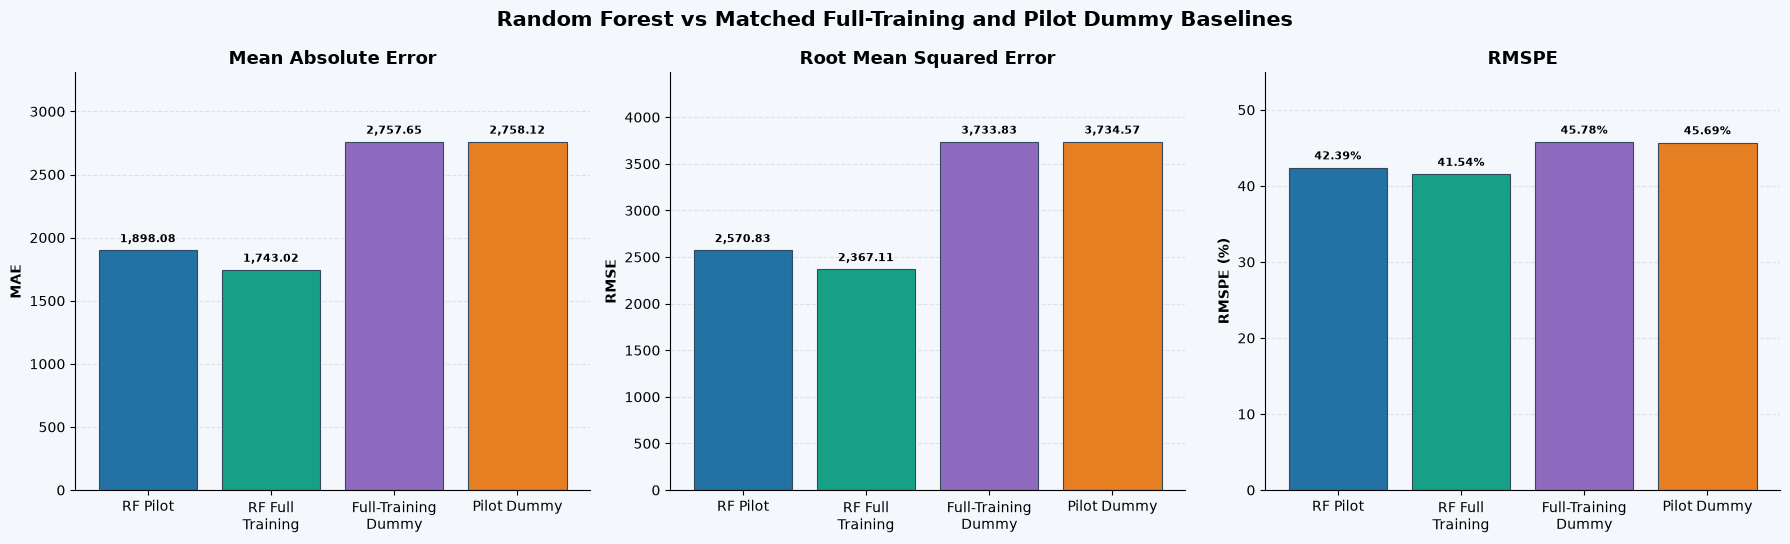

2026-11-05 21:49:08,276 | INFO | Project6_ML_Modeling | Section 12 completed successfully. Full-training Random Forest model fitted, evaluated, serialized and verified.



SECTION 12 FINAL FULL-TRAINING MODEL AUDIT
Full training rows used                      : True
Validation predictions aligned               : True
Validation predictions finite                : True
Full-training Dummy used all training rows   : True
Full-training Dummy sourced from Section 4   : True
Full-training Dummy mean matches all training Sales: True
Full-training Dummy predictions reproduce Section 4: True
Full-training Dummy predictions aligned      : True
Full-training Dummy predictions finite       : True
Full-training Dummy metrics finite           : True
Comparison contains both Dummy baselines     : True
Matched-baseline improvements finite         : True
Full model metrics finite                    : True
Feature importance sums to one               : True
Grouped feature importance sums to one       : True
Prediction interval bounds valid             : True
Model reload predictions match               : True
All output files saved                       : True

Final M

In [31]:
# ============================================================
# PROJECT 6 - NOTEBOOK 04
# SECTION 12: FINAL FULL-TRAINING REFIT,
# MATCHED BASELINE COMPARISON AND MODEL FINALIZATION
# ============================================================

import time
import gc
import json
import joblib
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

from IPython.display import display
from datetime import datetime
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor


# STEP 1: VERIFY THAT SECTIONS 1-11 PASSED

previous_section_flags = [

    "section_1_successful",
    "section_2_successful",
    "section_3_successful",
    "section_4_successful",
    "section_5_successful",
    "section_6_successful",
    "section_7_successful",
    "section_8_successful",
    "section_9_successful",
    "section_10_successful",
    "section_11_successful"

]

missing_flags = [

    name

    for name in previous_section_flags

    if name not in globals()

]

if missing_flags:

    raise NameError(
        f"Missing previous section flags: {missing_flags}"
    )

failed_flags = [

    name

    for name in previous_section_flags

    if not bool(globals()[name])

]

if failed_flags:

    raise RuntimeError(
        f"Previous sections have not passed: {failed_flags}"
    )

logger.info(
    "Section 12 started: final full-training model refit."
)


# STEP 2: VERIFY REQUIRED INPUTS

required_variables = [

    "X_train_processed",
    "X_valid_processed",
    "X_test_processed",

    "y_train",
    "y_train_pilot",
    "y_valid",
    "test_ids",

    "best_rf_parameters",
    "best_rf_pipeline",
    "best_rf_model_name",
    "best_rf_metrics",

    "preprocessor",
    "feature_names",
    "map_to_original_feature",

    "calculate_sales_metrics",

    "pilot_baseline_valid_metrics",

    "baseline_pipeline",
    "baseline_valid_predictions",
    "baseline_valid_metrics",
    "baseline_mean_sales",

    "grouped_feature_importance_df",
    "prediction_interval_summary_df",

    "ML_MODEL_DIR",
    "EVALUATION_DIR",

    "model_registry_path",
    "logger"

]

missing_variables = [

    name

    for name in required_variables

    if name not in globals()

]

if missing_variables:

    raise NameError(
        f"Required Section 12 variables are missing: {missing_variables}"
    )


# STEP 3: VALIDATE MATRIX AND TARGET ALIGNMENT

if X_train_processed.shape[0] != len(y_train):

    raise ValueError(
        "Full training features and Sales target are not aligned."
    )

if X_valid_processed.shape[0] != len(y_valid):

    raise ValueError(
        "Validation features and Sales target are not aligned."
    )

if X_train_processed.shape[1] != X_valid_processed.shape[1]:

    raise ValueError(
        "Training and validation feature counts do not match."
    )

if X_test_processed.shape[1] != X_train_processed.shape[1]:

    raise ValueError(
        "Test and training feature counts do not match."
    )

if not sp.issparse(X_train_processed):

    raise TypeError(
        "Training matrix must remain sparse."
    )

if not sp.issparse(X_valid_processed):

    raise TypeError(
        "Validation matrix must remain sparse."
    )

if not sp.issparse(X_test_processed):

    raise TypeError(
        "Test matrix must remain sparse."
    )

if not np.isfinite(y_train).all():

    raise ValueError(
        "Training Sales target contains invalid values."
    )

if not np.isfinite(y_valid).all():

    raise ValueError(
        "Validation Sales target contains invalid values."
    )

if len(feature_names) != X_train_processed.shape[1]:

    raise ValueError(
        "Feature names do not match the processed matrix."
    )

if not callable(map_to_original_feature):

    raise TypeError(
        "Feature-name mapping function from Section 8 is unavailable."
    )


# STEP 4: DISPLAY FINAL TRAINING CONFIGURATION

print("=" * 100)

print("FINAL FULL-TRAINING RANDOM FOREST")

print("=" * 100)

print(
    "Training rows:",
    f"{X_train_processed.shape[0]:,}"
)

print(
    "Validation rows:",
    f"{X_valid_processed.shape[0]:,}"
)

print(
    "Test rows:",
    f"{X_test_processed.shape[0]:,}"
)

print(
    "Processed features:",
    f"{X_train_processed.shape[1]:,}"
)

print("\nSelected parameters:")

for parameter_name, parameter_value in best_rf_parameters.items():

    print(
        f"{parameter_name:<25}: {parameter_value}"
    )


# STEP 5: BUILD A NEW PIPELINE

# Do not overwrite best_rf_pipeline.
# That object remains the selected pilot model.

final_rf_pipeline = Pipeline(

    steps=[

        (

            "regressor",

            RandomForestRegressor(
                **best_rf_parameters
            )

        )

    ]

)


# STEP 6: FIT THE MODEL ON ALL AVAILABLE TRAINING ROWS

# The complete chronological validation set is not used for fitting.
# The original test set is also not used.

print("\nStarting full-training model fit...")

fit_start_time = time.perf_counter()

try:

    final_rf_pipeline.fit(

        X_train_processed,

        y_train

    )

except MemoryError as exc:

    raise MemoryError(

        "The full-training Random Forest exceeded available memory. "

        "Do not silently continue with a partially fitted model. "

        "Reduce parallel jobs to 1 or reduce model complexity, "

        "then rerun this section."

    ) from exc

final_fit_time_seconds = (

    time.perf_counter() - fit_start_time

)

print(

    "\nFull-training model fit completed in:",

    f"{final_fit_time_seconds:.2f} seconds"

)

logger.info(
    "Full-training Random Forest fit completed."
)


# STEP 7: GENERATE VALIDATION PREDICTIONS

final_full_train_valid_predictions = (

    final_rf_pipeline.predict(

        X_valid_processed

    )

)

if len(final_full_train_valid_predictions) != len(y_valid):

    raise ValueError(
        "Full-training model validation prediction count is incorrect."
    )

if not np.isfinite(final_full_train_valid_predictions).all():

    raise ValueError(
        "Full-training model predictions contain NaN or infinity."
    )


# STEP 8: CALCULATE FULL-TRAINING RANDOM FOREST METRICS

final_full_training_metrics = calculate_sales_metrics(

    y_true=y_valid,

    y_pred=final_full_train_valid_predictions,

    dataset_name="Full Training Random Forest"

)

print("\n" + "=" * 100)

print("FULL-TRAINING RANDOM FOREST VALIDATION METRICS")

print("=" * 100)

for metric_name, metric_value in final_full_training_metrics.items():

    print(f"{metric_name:<25}: {metric_value}")


# STEP 9: REUSE THE MATCHED FULL-TRAINING DUMMY BASELINE
# FROM SECTION 4

# Important:
# Section 4 has already fitted DummyRegressor(strategy="mean")
# on ALL processed training rows (X_train_processed and y_train).
#
# Do not fit the same baseline again here.
# Reuse its saved predictions and validation metrics.


if not isinstance(baseline_pipeline, Pipeline):

    raise TypeError(

        "Section 4 baseline_pipeline is not a scikit-learn Pipeline."

    )

if not hasattr(baseline_pipeline, "named_steps"):

    raise ValueError(

        "Section 4 baseline pipeline does not expose named steps."

    )

if "regressor" not in baseline_pipeline.named_steps:

    raise KeyError(

        "Section 4 baseline pipeline does not contain a regressor step."

    )

section4_dummy_estimator = baseline_pipeline.named_steps["regressor"]

if getattr(section4_dummy_estimator, "strategy", None) != "mean":

    raise ValueError(

        "Section 4 baseline is not DummyRegressor(strategy='mean')."

    )


# Verify that the learned constant matches the mean
# of ALL training Sales.

expected_full_training_mean = float(np.mean(y_train))

if not np.isclose(

    float(baseline_mean_sales),

    expected_full_training_mean,

    rtol=1e-10,

    atol=1e-8

):

    raise ValueError(

        "Section 4 Dummy baseline mean does not match "
        "the full training target mean."

    )


# Confirm that the baseline's saved validation predictions align.

full_training_dummy_valid_predictions = np.asarray(

    baseline_valid_predictions,

    dtype=np.float64

).reshape(-1)

if len(full_training_dummy_valid_predictions) != len(y_valid):

    raise ValueError(

        "Section 4 full-training Dummy predictions are not aligned with y_valid."

    )

if not np.isfinite(full_training_dummy_valid_predictions).all():

    raise ValueError(

        "Section 4 full-training Dummy predictions contain NaN or infinity."

    )


# Re-predict with the saved Section 4 pipeline to verify that
# the stored validation predictions belong to this same fitted model.

section4_dummy_recheck_predictions = np.asarray(

    baseline_pipeline.predict(X_valid_processed),

    dtype=np.float64

).reshape(-1)

section4_dummy_predictions_match = bool(

    np.allclose(

        section4_dummy_recheck_predictions,

        full_training_dummy_valid_predictions,

        rtol=1e-10,

        atol=1e-8

    )

)

if not section4_dummy_predictions_match:

    raise ValueError(

        "Recomputed Section 4 Dummy predictions do not match the stored predictions."

    )


# Reuse the already calculated Section 4 full-training baseline metrics.

full_training_dummy_valid_metrics = dict(baseline_valid_metrics)

dummy_metric_names = ["MAE", "RMSE", "RMSPE_Percent"]

if not all(

    metric_name in full_training_dummy_valid_metrics

    and np.isfinite(float(full_training_dummy_valid_metrics[metric_name]))

    for metric_name in dummy_metric_names

):

    raise ValueError(

        "Section 4 full-training Dummy baseline metrics are missing or invalid."

    )

print("\nFULL-TRAINING DUMMY BASELINE REUSED FROM SECTION 4")

print("Training rows:", f"{len(y_train):,}")

print("Validation rows:", f"{len(y_valid):,}")

print("Dummy strategy:", section4_dummy_estimator.strategy)

print("Stored and recomputed predictions match:", section4_dummy_predictions_match)

for metric_name in dummy_metric_names:

    print(

        f"{metric_name:<25}: "

        f"{float(full_training_dummy_valid_metrics[metric_name]):,.2f}"

    )


# STEP 10: BUILD FOUR-MODEL VALIDATION COMPARISON

# All four models below are evaluated against the same y_valid rows.
# The two full-training models both use all available training rows.

final_full_training_metrics_df = pd.DataFrame([

    {

        "Model": "Selected RF Pilot",

        "Training_Rows": len(y_train_pilot),

        "MAE": best_rf_metrics["MAE"],

        "RMSE": best_rf_metrics["RMSE"],

        "RMSPE_Percent": best_rf_metrics["RMSPE_Percent"]

    },

    {

        "Model": "RF Full Training",

        "Training_Rows": len(y_train),

        "MAE": final_full_training_metrics["MAE"],

        "RMSE": final_full_training_metrics["RMSE"],

        "RMSPE_Percent": final_full_training_metrics["RMSPE_Percent"]

    },

    {

        "Model": "Dummy Full Training",

        "Training_Rows": len(y_train),

        "MAE": full_training_dummy_valid_metrics["MAE"],

        "RMSE": full_training_dummy_valid_metrics["RMSE"],

        "RMSPE_Percent": full_training_dummy_valid_metrics["RMSPE_Percent"]

    },

    {

        "Model": "Dummy Pilot Baseline",

        "Training_Rows": len(y_train_pilot),

        "MAE": pilot_baseline_valid_metrics["MAE"],

        "RMSE": pilot_baseline_valid_metrics["RMSE"],

        "RMSPE_Percent": pilot_baseline_valid_metrics["RMSPE_Percent"]

    }

])

display(

    final_full_training_metrics_df.style

    .format({

        "Training_Rows": "{:,.0f}",

        "MAE": "{:,.2f}",

        "RMSE": "{:,.2f}",

        "RMSPE_Percent": "{:.2f}%"

    })

    .hide(axis="index")

    .highlight_min(

        subset=["MAE", "RMSE", "RMSPE_Percent"],

        color="#D9EAD3"

    )

    .set_caption(

        "Random Forest and Dummy baselines evaluated on the same validation period"

    )

)


# STEP 11: CALCULATE ERROR REDUCTION AGAINST BOTH DUMMY BASELINES

# Percentage reduction =
# (baseline error - model error) / baseline error * 100.
#
# Positive values mean the Random Forest has lower error than the baseline.

full_model_improvement_vs_full_dummy = {}

full_model_improvement_vs_pilot_dummy = {}

for metric_name in ["MAE", "RMSE", "RMSPE_Percent"]:

    final_value = float(final_full_training_metrics[metric_name])

    full_dummy_reference = float(

        full_training_dummy_valid_metrics[metric_name]

    )

    pilot_dummy_reference = float(

        pilot_baseline_valid_metrics[metric_name]

    )

    if full_dummy_reference <= 0 or pilot_dummy_reference <= 0:

        raise ValueError(

            f"Cannot calculate {metric_name} error reduction because "

            "a Dummy baseline metric is zero or negative."

        )

    full_model_improvement_vs_full_dummy[metric_name] = (

        (full_dummy_reference - final_value)

        / full_dummy_reference

    ) * 100

    full_model_improvement_vs_pilot_dummy[metric_name] = (

        (pilot_dummy_reference - final_value)

        / pilot_dummy_reference

    ) * 100


# Keep the existing variable name for downstream compatibility.
# The primary comparison now uses the matched full-training Dummy baseline.

full_model_improvement = full_model_improvement_vs_full_dummy

print("\nERROR REDUCTION: FULL-TRAINING RF VS FULL-TRAINING DUMMY")

for metric_name, reduction in full_model_improvement_vs_full_dummy.items():

    print(f"{metric_name:<20}: {reduction:.2f}%")

print("\nREFERENCE: FULL-TRAINING RF VS PILOT DUMMY")

for metric_name, reduction in full_model_improvement_vs_pilot_dummy.items():

    print(f"{metric_name:<20}: {reduction:.2f}%")


# STEP 12: EXTRACT FULL-TRAINING FEATURE IMPORTANCE

final_estimator = (
    final_rf_pipeline.named_steps["regressor"]
)

final_feature_importances = np.asarray(

    final_estimator.feature_importances_,

    dtype=np.float64

)

if len(final_feature_importances) != len(feature_names):

    raise ValueError(
        "Full-training feature importance does not align "
        "with processed feature names."
    )

if not np.isfinite(final_feature_importances).all():

    raise ValueError(
        "Full-training feature importance contains invalid values."
    )

if not np.isclose(

    final_feature_importances.sum(),

    1.0,

    atol=1e-6

):

    raise ValueError(
        "Full-training feature importance does not sum to 1."
    )


# Create processed feature importance table.

final_feature_importance_df = pd.DataFrame({

    "Feature_Name": feature_names,

    "Importance": final_feature_importances,

    "Importance_Percent": (
        final_feature_importances * 100
    )

})

final_feature_importance_df = (

    final_feature_importance_df

    .sort_values(

        "Importance",

        ascending=False

    )

    .reset_index(drop=True)

)

final_feature_importance_df.insert(

    0,

    "Rank",

    np.arange(

        1,

        len(final_feature_importance_df) + 1

    )

)


# STEP 13: AGGREGATE FULL-TRAINING IMPORTANCE TO ORIGINAL FEATURES

final_feature_importance_df["Original_Feature"] = (

    final_feature_importance_df["Feature_Name"]

    .apply(map_to_original_feature)

)

final_grouped_feature_importance_df = (

    final_feature_importance_df

    .groupby(

        "Original_Feature",

        as_index=False

    )

    .agg(

        Importance=(

            "Importance",

            "sum"

        ),

        Processed_Feature_Count=(

            "Feature_Name",

            "count"

        )

    )

)

final_grouped_feature_importance_df[
    "Importance_Percent"
] = (

    final_grouped_feature_importance_df["Importance"] * 100

)

final_grouped_feature_importance_df = (

    final_grouped_feature_importance_df

    .sort_values(

        "Importance",

        ascending=False

    )

    .reset_index(drop=True)

)

final_grouped_feature_importance_df.insert(

    0,

    "Rank",

    np.arange(

        1,

        len(final_grouped_feature_importance_df) + 1

    )

)

if not np.isclose(

    final_grouped_feature_importance_df["Importance"].sum(),

    1.0,

    atol=1e-6

):

    raise ValueError(
        "Aggregated full-training feature importance does not sum to 1."
    )

print("\nTOP 15 ORIGINAL FEATURES - FULL-TRAINING MODEL")

display(

    final_grouped_feature_importance_df.head(15).style

    .format({

        "Importance": "{:.6f}",

        "Importance_Percent": "{:.3f}%",

        "Processed_Feature_Count": "{:,.0f}"

    })

    .hide(axis="index")

    .background_gradient(

        subset=["Importance_Percent"],

        cmap="YlGnBu"

    )

    .set_caption(
        "Full-training Random Forest aggregated feature importance"
    )

)


# STEP 14: ESTIMATE FULL-TRAINING MODEL PREDICTION INTERVALS

# The individual tree predictions are used to estimate
# empirical 5th and 95th percentile bounds.

tree_prediction_list_final = []

for tree_number, tree in enumerate(

    final_estimator.estimators_,

    start=1

):

    tree_predictions = np.asarray(

        tree.predict(

            X_valid_processed

        ),

        dtype=np.float64

    )

    if len(tree_predictions) != len(y_valid):

        raise ValueError(

            f"Final model tree {tree_number} returned "
            "an incorrect number of predictions."

        )

    if not np.isfinite(tree_predictions).all():

        raise ValueError(

            f"Final model tree {tree_number} produced "
            "invalid predictions."

        )

    tree_prediction_list_final.append(
        tree_predictions
    )

tree_prediction_matrix_final = np.vstack(
    tree_prediction_list_final
)

final_lower_bounds = np.quantile(

    tree_prediction_matrix_final,

    0.05,

    axis=0

)

final_upper_bounds = np.quantile(

    tree_prediction_matrix_final,

    0.95,

    axis=0

)

if not (

    (final_lower_bounds <= final_upper_bounds).all()

):

    raise ValueError(
        "Final prediction interval lower bounds exceed upper bounds."
    )


# Calculate coverage and interval widths.

final_interval_covered = (

    (y_valid >= final_lower_bounds)

    &

    (y_valid <= final_upper_bounds)

)

final_interval_width = (

    final_upper_bounds - final_lower_bounds

)

final_overall_coverage = (

    final_interval_covered.mean() * 100

)

positive_sales_mask_final = (
    y_valid > 0
)

zero_sales_mask_final = (
    y_valid == 0
)

positive_coverage_final = (

    final_interval_covered[
        positive_sales_mask_final
    ].mean() * 100

)

zero_coverage_final = (

    final_interval_covered[
        zero_sales_mask_final
    ].mean() * 100

)

final_interval_summary_df = pd.DataFrame([

    {

        "Segment": "All Validation",

        "Observations": len(y_valid),

        "Coverage_Percent": final_overall_coverage,

        "Nominal_Coverage_Percent": 90.0,

        "Mean_Interval_Width": float(
            np.mean(final_interval_width)
        ),

        "Median_Interval_Width": float(
            np.median(final_interval_width)
        )

    },

    {

        "Segment": "Positive Sales",

        "Observations": int(
            positive_sales_mask_final.sum()
        ),

        "Coverage_Percent": positive_coverage_final,

        "Nominal_Coverage_Percent": 90.0,

        "Mean_Interval_Width": float(
            np.mean(
                final_interval_width[
                    positive_sales_mask_final
                ]
            )
        ),

        "Median_Interval_Width": float(
            np.median(
                final_interval_width[
                    positive_sales_mask_final
                ]
            )
        )

    },

    {

        "Segment": "Zero Sales",

        "Observations": int(
            zero_sales_mask_final.sum()
        ),

        "Coverage_Percent": zero_coverage_final,

        "Nominal_Coverage_Percent": 90.0,

        "Mean_Interval_Width": float(
            np.mean(
                final_interval_width[
                    zero_sales_mask_final
                ]
            )
        ),

        "Median_Interval_Width": float(
            np.median(
                final_interval_width[
                    zero_sales_mask_final
                ]
            )
        )

    }

])

print("\nFULL-TRAINING MODEL PREDICTION INTERVAL RESULTS")

display(

    final_interval_summary_df.style

    .format({

        "Observations": "{:,.0f}",

        "Coverage_Percent": "{:.2f}%",

        "Nominal_Coverage_Percent": "{:.2f}%",

        "Mean_Interval_Width": "{:,.2f}",

        "Median_Interval_Width": "{:,.2f}"

    })

    .hide(axis="index")

    .set_caption(
        "Empirical prediction interval diagnostic for full-training model"
    )

)


# STEP 15: CREATE FULL-TRAINING MODEL PERFORMANCE GRAPH

chart_specs = [

    ("MAE", "MAE", "Mean Absolute Error"),

    ("RMSE", "RMSE", "Root Mean Squared Error"),

    ("RMSPE_Percent", "RMSPE (%)", "RMSPE")

]

fig, axes = plt.subplots(

    1,

    3,

    figsize=(18, 5.5),

    facecolor="#F4F7FB"

)

for ax, (metric_name, y_label, title) in zip(

    axes,

    chart_specs

):

    ax.set_facecolor("#F4F7FB")

    values = [

        float(best_rf_metrics[metric_name]),

        float(final_full_training_metrics[metric_name]),

        float(full_training_dummy_valid_metrics[metric_name]),

        float(pilot_baseline_valid_metrics[metric_name])

    ]

    bars = ax.bar(

        [

            "RF Pilot",

            "RF Full\nTraining",

            "Full-Training\nDummy",

            "Pilot Dummy"

        ],

        values,

        color=[

            "#2471A3",

            "#16A085",

            "#8E6BBE",

            "#E67E22"

        ],

        edgecolor="#34495E",

        linewidth=0.8

    )

    ax.set_title(

        title,

        fontsize=13,

        fontweight="bold"

    )

    ax.set_ylabel(

        y_label,

        fontsize=10,

        fontweight="bold"

    )

    for bar, value in zip(bars, values):

        suffix = (
            "%"
            if metric_name == "RMSPE_Percent"
            else ""
        )

        ax.annotate(

            f"{value:,.2f}{suffix}",

            xy=(

                bar.get_x() + bar.get_width() / 2,

                bar.get_height()

            ),

            xytext=(0, 6),

            textcoords="offset points",

            ha="center",

            fontsize=8,

            fontweight="bold"

        )

    ax.grid(

        axis="y",

        linestyle="--",

        alpha=0.30

    )

    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)

    ax.spines["right"].set_visible(False)

    ax.margins(y=0.20)

fig.suptitle(

    "Random Forest vs Matched Full-Training and Pilot Dummy Baselines",

    fontsize=15,

    fontweight="bold"

)

fig.tight_layout()

full_model_chart_path = (

    EVALUATION_DIR

    / "section12_full_training_model_comparison.png"

)

fig.savefig(

    full_model_chart_path,

    dpi=180,

    bbox_inches="tight",

    facecolor=fig.get_facecolor()

)

plt.show()

plt.close(fig)


# STEP 16: CREATE TIMESTAMPED MODEL VERSION

timestamp_token = datetime.now().strftime(
    "%d-%m-%Y-%H-%M-%S-00"
)

final_model_version = (
    f"RandomForest_FullTraining_{timestamp_token}"
)

ML_MODEL_DIR = Path(ML_MODEL_DIR)

ML_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

final_model_file_path = (

    ML_MODEL_DIR

    / f"{final_model_version}.pkl"

)

counter = 1

while final_model_file_path.exists():

    final_model_version = (

        f"RandomForest_FullTraining_{timestamp_token}_v{counter}"

    )

    final_model_file_path = (

        ML_MODEL_DIR

        / f"{final_model_version}.pkl"

    )

    counter += 1

final_model_metadata_path = (

    ML_MODEL_DIR

    / f"{final_model_version}_metadata.json"

)


# STEP 17: PREPARE FINAL MODEL METADATA

# Section 2 creates a corrected in-memory metadata copy and records
# the audit result. Use those verified values here rather than reading
# a discrepancy field from the untouched source JSON.

required_metadata_variables = [
    "modeling_metadata",
    "metadata_audit_passed",
    "metadata_discrepancies"
]

missing_metadata_variables = [
    name for name in required_metadata_variables
    if name not in globals()
]

if missing_metadata_variables:
    raise NameError(
        "Run Notebook 04 Section 2 before preparing final metadata. "
        f"Missing variables: {missing_metadata_variables}"
    )

source_metadata_discrepancies = list(metadata_discrepancies)

final_model_metadata = {
    "project":
        "Sales Forecasting Across Multiple Retail Stores",

    "notebook":
        "04_machine_learning_modeling_evaluation",

    "model_version":
        final_model_version,

    "created_at":
        datetime.now().isoformat(timespec="seconds"),

    "model_type":
        "RandomForestRegressor",

    "model_stage":
        "Full-training model candidate",

    "target_variable":
        "Sales",

    "training_rows":
        int(X_train_processed.shape[0]),

    "validation_rows":
        int(X_valid_processed.shape[0]),

    "test_rows":
        int(X_test_processed.shape[0]),

    "processed_feature_count":
        int(X_train_processed.shape[1]),

    "parameters":
        best_rf_parameters,

    "training_split":
        "Chronological training period only",

    "bootstrap_sample_fraction_per_tree":
        float(best_rf_parameters["max_samples"]),

    "validation_metrics": {
        "MAE":
            float(final_full_training_metrics["MAE"]),
        "RMSE":
            float(final_full_training_metrics["RMSE"]),
        "RMSPE_Percent":
            float(final_full_training_metrics["RMSPE_Percent"])
    },

    "full_training_dummy_validation_metrics": {
        "MAE":
            float(full_training_dummy_valid_metrics["MAE"]),
        "RMSE":
            float(full_training_dummy_valid_metrics["RMSE"]),
        "RMSPE_Percent":
            float(full_training_dummy_valid_metrics["RMSPE_Percent"])
    },

    "pilot_validation_metrics": {
        "MAE":
            float(best_rf_metrics["MAE"]),
        "RMSE":
            float(best_rf_metrics["RMSE"]),
        "RMSPE_Percent":
            float(best_rf_metrics["RMSPE_Percent"])
    },

    "relative_error_reduction_vs_full_training_dummy_percent":
        full_model_improvement_vs_full_dummy,

    "relative_error_reduction_vs_pilot_dummy_percent":
        full_model_improvement_vs_pilot_dummy,

    "full_training_dummy_strategy":
        "Section 4 DummyRegressor(strategy='mean') fitted on all training rows; reused without refitting",

    "training_criterion":
        "squared_error",

    "primary_validation_selection_metric":
        "RMSPE on positive actual Sales rows",

    "secondary_validation_metrics":
        ["MAE", "RMSE"],

    "feature_importance_method":
        "Mean Decrease in Impurity",

    "prediction_interval_method":
        "5th and 95th percentiles of individual tree predictions",

    "prediction_interval_overall_coverage_percent":
        float(final_overall_coverage),

    "prediction_interval_nominal_coverage_percent":
        90.0,

    "prediction_interval_status":
        "Empirical interval; calibration not guaranteed",

    "validation_selection_note":
        "The validation set was previously used for hyperparameter selection; "
        "these metrics should not be interpreted as an independent final estimate.",

    "preprocessor_source":
        "Notebook 03 fitted preprocessor.joblib",

    "preprocessing_fitted_on":
        modeling_metadata.get(
            "preprocessing_fitted_on",
            "X_train only"
        ),

    "source_metadata_audit_passed":
        bool(metadata_audit_passed),

    "source_metadata_discrepancies":
        source_metadata_discrepancies,

    "source_metadata_audit_details":
        modeling_metadata.get(
            "section_2_metadata_audit",
            {}
        )
}


# STEP 18: CREATE FINAL MODEL BUNDLE

final_model_bundle = {

    "model_version":

        final_model_version,

    "model_pipeline":

        final_rf_pipeline,

    "preprocessor":

        preprocessor,

    "feature_names":

        feature_names,

    "metadata":

        final_model_metadata

}


# STEP 19: SERIALIZE FINAL FULL-TRAINING MODEL

joblib.dump(

    final_model_bundle,

    final_model_file_path,

    compress=3

)


# STEP 20: SAVE FINAL MODEL METADATA

with open(

    final_model_metadata_path,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        final_model_metadata,

        file,

        indent=4,

        ensure_ascii=False,

        default=str

    )


# STEP 21: RELOAD MODEL AND VERIFY PREDICTIONS

reloaded_final_model_bundle = joblib.load(
    final_model_file_path
)

bundle_keys_valid = (

    isinstance(reloaded_final_model_bundle, dict)

    and all(

        key in reloaded_final_model_bundle

        for key in [

            "model_version",

            "model_pipeline",

            "preprocessor",

            "feature_names",

            "metadata"

        ]

    )

)

if not bundle_keys_valid:

    raise ValueError(
        "Full-training model bundle has an invalid structure."
    )

verification_rows = min(

    256,

    len(y_valid)

)

reloaded_final_predictions = (

    reloaded_final_model_bundle["model_pipeline"]

    .predict(

        X_valid_processed[:verification_rows]

    )

)

original_final_predictions = (

    final_full_train_valid_predictions[:verification_rows]

)

final_reload_predictions_match = bool(

    np.allclose(

        reloaded_final_predictions,

        original_final_predictions,

        rtol=1e-10,

        atol=1e-8

    )

)

if not final_reload_predictions_match:

    raise ValueError(
        "Reloaded full-training model predictions do not match "
        "the original full-training model."
    )


# STEP 22: SAVE FULL-TRAINING MODEL VERSION REGISTRY ENTRY

final_registry_path = Path(
    model_registry_path
)

if final_registry_path.is_file():

    existing_registry_df = pd.read_csv(
        final_registry_path
    )

else:

    existing_registry_df = pd.DataFrame()

registry_record = {

    "Model_Version":

        final_model_version,

    "Created_At":

        final_model_metadata["created_at"],

    "Model_Type":

        "RandomForestRegressor",

    "Model_Stage":

        "Full Training Candidate",

    "Training_Rows":

        int(len(y_train)),

    "Validation_Rows":

        int(len(y_valid)),

    "MAE":

        float(final_full_training_metrics["MAE"]),

    "RMSE":

        float(final_full_training_metrics["RMSE"]),

    "RMSPE_Percent":

        float(final_full_training_metrics["RMSPE_Percent"]),

    "Full_Training_Dummy_MAE":

        float(full_training_dummy_valid_metrics["MAE"]),

    "Full_Training_Dummy_RMSE":

        float(full_training_dummy_valid_metrics["RMSE"]),

    "Full_Training_Dummy_RMSPE_Percent":

        float(full_training_dummy_valid_metrics["RMSPE_Percent"]),

    "MAE_Reduction_vs_Full_Training_Dummy_Percent":

        float(full_model_improvement_vs_full_dummy["MAE"]),

    "RMSE_Reduction_vs_Full_Training_Dummy_Percent":

        float(full_model_improvement_vs_full_dummy["RMSE"]),

    "RMSPE_Reduction_vs_Full_Training_Dummy_Percent":

        float(full_model_improvement_vs_full_dummy["RMSPE_Percent"]),

    "Model_File":

        str(final_model_file_path),

    "Metadata_File":

        str(final_model_metadata_path)

}

updated_registry_df = pd.concat(

    [

        existing_registry_df,

        pd.DataFrame([registry_record])

    ],

    ignore_index=True

)

updated_registry_df.to_csv(

    final_registry_path,

    index=False

)


# STEP 23: SAVE FULL-TRAINING EVALUATION TABLES

final_metrics_path = (

    EVALUATION_DIR

    / "section12_full_training_model_metrics.csv"

)

final_importance_path = (

    EVALUATION_DIR

    / "section12_full_training_feature_importance.csv"

)

final_grouped_importance_path = (

    EVALUATION_DIR

    / "section12_full_training_grouped_importance.csv"

)

final_interval_summary_path = (

    EVALUATION_DIR

    / "section12_full_training_interval_summary.csv"

)

final_interval_details_path = (

    EVALUATION_DIR

    / "section12_full_training_validation_intervals.csv"

)

final_full_training_metrics_df.to_csv(

    final_metrics_path,

    index=False

)

final_feature_importance_df.to_csv(

    final_importance_path,

    index=False

)

final_grouped_feature_importance_df.to_csv(

    final_grouped_importance_path,

    index=False

)

final_interval_summary_df.to_csv(

    final_interval_summary_path,

    index=False

)

final_interval_details_df = pd.DataFrame({

    "Validation_Row_Index":
        np.arange(len(y_valid)),

    "Actual_Sales":
        y_valid,

    "Predicted_Sales":
        final_full_train_valid_predictions,

    "Lower_Bound":
        final_lower_bounds,

    "Upper_Bound":
        final_upper_bounds,

    "Interval_Width":
        final_interval_width,

    "Covered":
        final_interval_covered

})

final_interval_details_df.to_csv(

    final_interval_details_path,

    index=False

)


# STEP 24: SAVE FULL-TRAINING SUMMARY JSON

full_training_summary = {

    "model_version":

        final_model_version,

    "model_file":

        str(final_model_file_path),

    "metadata_file":

        str(final_model_metadata_path),

    "training_rows":

        int(len(y_train)),

    "validation_rows":

        int(len(y_valid)),

    "fit_time_seconds":

        float(final_fit_time_seconds),

    "validation_metrics":

        final_full_training_metrics,

    "full_training_dummy_validation_metrics":

        full_training_dummy_valid_metrics,

    "relative_error_reduction_vs_full_training_dummy":

        full_model_improvement_vs_full_dummy,

    "relative_error_reduction_vs_pilot_dummy":

        full_model_improvement_vs_pilot_dummy,

    "overall_interval_coverage_percent":

        float(final_overall_coverage),

    "positive_sales_interval_coverage_percent":

        float(positive_coverage_final),

    "zero_sales_interval_coverage_percent":

        float(zero_coverage_final),

    "reload_predictions_match":

        final_reload_predictions_match,

    "validation_selection_warning":

        "Validation data was previously used in hyperparameter selection."

}

full_training_summary_path = (

    EVALUATION_DIR

    / "section12_full_training_model_summary.json"

)

with open(

    full_training_summary_path,

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        full_training_summary,

        file,

        indent=4,

        default=str

    )


# STEP 25: VERIFY ALL SAVED FILES

section12_output_paths = [

    final_model_file_path,

    final_model_metadata_path,

    final_registry_path,

    final_metrics_path,

    final_importance_path,

    final_grouped_importance_path,

    final_interval_summary_path,

    final_interval_details_path,

    full_training_summary_path,

    full_model_chart_path

]

section12_file_checks = {

    path.name: (

        path.is_file()

        and path.stat().st_size > 0

    )

    for path in section12_output_paths

}


# STEP 26: FINAL SECTION VALIDATION

section12_checks = {

    "Full training rows used":
        len(y_train) == X_train_processed.shape[0],

    "Validation predictions aligned":
        len(final_full_train_valid_predictions) == len(y_valid),

    "Validation predictions finite":
        bool(np.isfinite(final_full_train_valid_predictions).all()),

    "Full-training Dummy used all training rows":
        len(y_train) == X_train_processed.shape[0],

    "Full-training Dummy sourced from Section 4":
        getattr(section4_dummy_estimator, "strategy", None) == "mean",

    "Full-training Dummy mean matches all training Sales":
        bool(np.isclose(
            float(baseline_mean_sales),
            float(np.mean(y_train)),
            rtol=1e-10,
            atol=1e-8
        )),

    "Full-training Dummy predictions reproduce Section 4":
        section4_dummy_predictions_match,

    "Full-training Dummy predictions aligned":
        len(full_training_dummy_valid_predictions) == len(y_valid),

    "Full-training Dummy predictions finite":
        bool(np.isfinite(full_training_dummy_valid_predictions).all()),

    "Full-training Dummy metrics finite":
        bool(np.isfinite([
            full_training_dummy_valid_metrics["MAE"],
            full_training_dummy_valid_metrics["RMSE"],
            full_training_dummy_valid_metrics["RMSPE_Percent"]
        ]).all()),

    "Comparison contains both Dummy baselines":
        {"Dummy Full Training", "Dummy Pilot Baseline"}.issubset(
            set(final_full_training_metrics_df["Model"])
        ),

    "Matched-baseline improvements finite":
        bool(np.isfinite(
            list(full_model_improvement_vs_full_dummy.values())
        ).all()),

    "Full model metrics finite":
        bool(np.isfinite(
            final_full_training_metrics_df[
                ["MAE", "RMSE", "RMSPE_Percent"]
            ].to_numpy(dtype=float)
        ).all()),

    "Feature importance sums to one":
        bool(np.isclose(
            final_feature_importances.sum(),
            1.0,
            atol=1e-6
        )),

    "Grouped feature importance sums to one":
        bool(np.isclose(
            final_grouped_feature_importance_df["Importance"].sum(),
            1.0,
            atol=1e-6
        )),

    "Prediction interval bounds valid":
        bool((final_lower_bounds <= final_upper_bounds).all()),

    "Model reload predictions match":
        final_reload_predictions_match,

    "All output files saved":
        all(section12_file_checks.values())

}

section_12_successful = all(
    section12_checks.values()
)

print("\n" + "=" * 110)

print("SECTION 12 FINAL FULL-TRAINING MODEL AUDIT")

print("=" * 110)

for check_name, check_status in section12_checks.items():

    print(
        f"{check_name:<45}: {check_status}"
    )

print("\nFinal Model Version:")

print(final_model_version)

print("\nFinal Model File:")

print(final_model_file_path)

print("\nFinal Metadata File:")

print(final_model_metadata_path)

print("\nFinal Model Registry:")

print(final_registry_path)

print("\nSaved Output Files:")

for file_name, file_status in section12_file_checks.items():

    print(
        f"{file_name:<55}: {file_status}"
    )

print(
    "\nSECTION 12 COMPLETED SUCCESSFULLY:",
    section_12_successful
)

print("=" * 110)

if not section_12_successful:

    failed_checks = [

        name

        for name, status in section12_checks.items()

        if not status

    ]

    raise RuntimeError(

        "Section 12 full-training model audit failed. "

        f"Failed checks: {failed_checks}"

    )

logger.info(
    "Section 12 completed successfully. "
    "Full-training Random Forest model fitted, evaluated, "
    "serialized and verified."
)